In [1]:
import os
from pathlib import Path
print(os.getcwd())
print('\n'.join(str(p) for p in Path('/workspace').glob('*')))
print('\nPrompts:', list(Path('/workspace/.prompts').glob('*')))

/workspace
/workspace/truth_phys.py
/workspace/.config
/workspace/calphad_grid.csv
/workspace/bofn_alloy.py
/workspace/calphad_grid.py
/workspace/.prompts
/workspace/memory
/workspace/lost+found
/workspace/corrosion_data.csv
/workspace/corrosion_fit.json
/workspace/phys_tables.md
/workspace/.skills
/workspace/.kernel_llm_logs_1.jsonl
/workspace/corrosion_fit.md
/workspace/phys_tables.json
/workspace/fit_corrosion.py

Prompts: [PosixPath('/workspace/.prompts/USER.md'), PosixPath('/workspace/.prompts/BOOTSTRAP.md'), PosixPath('/workspace/.prompts/MEMORY.md')]


In [2]:
from e14c.subagents import submit_task
outdir=Path('/workspace/outputs'); outdir.mkdir(exist_ok=True)
q1='''Independently audit primary sources for /workspace/corrosion_data.csv, focusing Tan2024 DOI 10.3390/ma17061330, Yang2018 10.3390/ma11091777, Zhao2022 10.3390/met12050781. Verify EACH row numerical rate/composition/test; determine same-test comparability and constructed values. Find missed same-study alloys in these papers. Retrieve full text where possible. Save source extracts, row audit, exact added usable numeric data with provenance to /workspace/outputs/audit_mdpi.md and added_mdpi.csv. Do not invent values or trust uploaded provenance line labels. Save full BibTeX via e14c citation APIs for sources used. This is an independent review: report access failures and exact tables. No modeling needed.'''
q2='''Find PRIMARY measured same-test seawater or 3.5% NaCl corrosion comparisons pure Cu or Cu-2Ni/Cu-5Ni vs 10-30Ni, plus low-Ni aluminum bronze / NAB / Cu-Ni-Al. Urgent key evidence missing in /workspace/corrosion_data.csv. Also audit Qian2025 DOI 10.1007/s42114-024-01174-0 and LewisLaQue1981 DOI 10.2172/6255887 rows in that file against actual sources (rates, grades, durations). Prefer immersion mass loss, but report Tafel separately. Save exact numeric rates AND compositions, test and source/table/page to /workspace/outputs/audit_lowNi.md and added_lowNi.csv. Distinguish measured vs constructed, product-form mismatch, no guessed grades. Save full BibTeX via e14c APIs. Seek zero-Ni bridge within same study, not cross-study absolute comparisons. No fitting needed.'''
taskids=[]
for q in [q1,q2]:
    taskids.append(await submit_task(q, agent_type='data-retrieval', project_id=os.environ.get('PROJECT_ID')))
print(taskids)
print('Plan: independently reconstruct within-study fitting and constrained floor optimization before inspecting fit_corrosion.py; audit evidence in parallel; then compare implementation, CALPHAD mappings, and full-truth limits.')

['9004f1f1-e565-407f-b611-f1a14350765f', '9d06146d-044d-46e0-b41d-bdd9f7022e88']
Plan: independently reconstruct within-study fitting and constrained floor optimization before inspecting fit_corrosion.py; audit evidence in parallel; then compare implementation, CALPHAD mappings, and full-truth limits.


In [3]:
import numpy as np, pandas as pd, scipy
from scipy.optimize import lsq_linear, minimize
from scipy.interpolate import RegularGridInterpolator
D=pd.read_csv('corrosion_data.csv'); G=pd.read_csv('calphad_grid.csv')
print(D.groupby('study').size()); print(G.shape); print(G.ok.value_counts()); print(G.isna().sum()[lambda x:x>0]); print(G.columns.tolist())
print('installed:', {x: __import__('importlib').util.find_spec(x) is not None for x in ['pycalphad','torch','botorch']})
# Independent fit: weighted, within-study centered response/design removes study intercepts exactly.
def features(dat, scale=5., linear=False, quadratic=True, fe_cap=1.5, mn=False, interaction=False):
    n,a,f,m=[np.asarray(dat[k],dtype=float) for k in ['ni','al','fe','mn']]
    X=[n/10 if linear else -np.expm1(-n/scale),a]; names=['ni','al']
    if quadratic: X.append(a*a/10); names.append('al2')
    X.append(np.minimum(f,fe_cap)); names.append('fe')
    if mn: X.append(m); names.append('mn')
    if interaction: X.append(n*a/10); names.append('nial')
    return np.array(X).T,names

def independent_fit(dat=D, scale=5., linear=False, quadratic=True, fe_cap=1.5, mn=False, interaction=False, signs=True, weights='given', label='base'):
    dat=dat.copy(); X,names=features(dat,scale,linear,quadratic,fe_cap,mn,interaction)
    y=np.log(dat.rate.to_numpy()); w=dat.weight.to_numpy() if weights=='given' else np.ones(len(dat))
    if weights=='study_equal':
        for st in dat.study.unique():
            ix=np.where(dat.study.to_numpy()==st)[0]; w[ix]=1/len(ix)
    Xc=X.copy(); yc=y.copy()
    for st in dat.study.unique():
        ix=np.where(dat.study.to_numpy()==st)[0]
        Xc[ix]-=np.average(X[ix],axis=0,weights=w[ix]); yc[ix]-=np.average(y[ix],weights=w[ix])
    low=np.full(len(names),-np.inf); high=np.full(len(names),np.inf)
    if signs:
        high[names.index('ni')]=0; high[names.index('fe')]=0
    sol=lsq_linear(Xc*np.sqrt(w[:,None]),yc*np.sqrt(w),bounds=(low,high),tol=1e-13,max_iter=1000)
    return dict(label=label,coef=dict(zip(names,sol.x)),options=dict(scale=scale,linear=linear,quadratic=quadratic,fe_cap=fe_cap,mn=mn,interaction=interaction),sse=float(np.sum(w*(yc-Xc@sol.x)**2)),rank=int(np.linalg.matrix_rank(Xc)),n=len(y),contrasts=len(y)-dat.study.nunique(),singular_values=np.linalg.svd(Xc*np.sqrt(w[:,None]),compute_uv=False).tolist())
ind=independent_fit()
print('FIRST independent fit, before inspecting fitting script:',ind)
(outdir/'independent_first_fit.json').write_text(__import__('json').dumps(ind,indent=2))

study
LewisLaQue1981_1y       4
LewisLaQue1981_quiet    2
Qian2025                2
Tan2024                 4
Yang2018                2
Zhao2022                2
dtype: int64
(864, 38)
ok
1    864
Name: count, dtype: int64
liquidus_C      33
range_C         33
primary         44
alpha600_xni     6
alpha600_xal     6
alpha600_xfe     6
alpha600_xmn     6
dtype: int64
['Ni_wt', 'Al_wt', 'Fe_wt', 'Mn_wt', 'liquidus_C', 'solidus_C', 'range_C', 'primary', 'liquid_sol', 'alpha_sol', 'beta_sol', 'kappa_fe_sol', 'fcc_feni_sol', 'nial_sol', 'gprime_sol', 'other_sol', 'liquid_900', 'alpha_900', 'beta_900', 'kappa_fe_900', 'fcc_feni_900', 'nial_900', 'gprime_900', 'other_900', 'liquid_600', 'alpha_600', 'beta_600', 'kappa_fe_600', 'fcc_feni_600', 'nial_600', 'gprime_600', 'other_600', 'alpha600_xni', 'alpha600_xal', 'alpha600_xfe', 'alpha600_xmn', 'ok', 'wall_s']
installed: {'pycalphad': False, 'torch': True, 'botorch': False}
FIRST independent fit, before inspecting fitting script: {'label': 'ba

501

In [4]:
# Persist the independent regression and optimization implementation as a reusable output script.
import inspect, json
# Add ridge only after initial independent unpenalized result was saved.
src=inspect.getsource(independent_fit).replace("label='base')", "label='base', ridge=0.05)")
src=src.replace("sol=lsq_linear(Xc*np.sqrt(w[:,None]),yc*np.sqrt(w),", "AA=np.vstack([Xc*np.sqrt(w[:,None]),np.sqrt(ridge)*np.eye(len(names))]); yy=np.r_[yc*np.sqrt(w),np.zeros(len(names))]\n    sol=lsq_linear(AA,yy,")
src=src.replace("sse=float", "ridge=ridge,sse=float")
exec(src)
base=independent_fit()
print('Independent ridge fit:',base)
# Match grid handling but use exact unrounded axis levels, as truth_phys does.
axes=[np.linspace(0,30,8),np.linspace(0,9.5,6),np.linspace(0,4.5,6),np.array([0,2,4])]
liq=G.liquidus_C.fillna(1550).to_numpy().reshape(8,6,6,3)
liquidus=RegularGridInterpolator(axes,liq,bounds_error=False,fill_value=None)
def zrate(model,x):
    n,a,f,m=np.asarray(x)
    xx,names=features(dict(ni=n,al=a,fe=f,mn=m),**model['options'])
    return float(xx@np.array([model['coef'][k] for k in names]))
REFS={'9010':np.array([10.,0.,1.4,.8]), '7030':np.array([30.,0.,.6,.8])}
# Optimize all three continuous variables, partitioning discontinuous domain restrictions.
# Mn is fixed at zero for comparability, but optimized as a fourth coordinate for models with Mn.
def optimized_floor(model,bar,mn_free=False):
    target=zrate(model,REFS[bar]); results=[]
    for alo,ahi,fcap,nige in [(0,1.5,2.3,False),(1.5,7,4.5,False),(7,9.5,4.5,True)]:
        bounds=[(0,30),(alo,ahi),(0,fcap)]+([(0,4)] if mn_free else [])
        def to4(x): return np.r_[x,0.] if len(x)==3 else np.array(x)
        def cc(x):
            v=to4(x); cons=[35-v.sum(),1250-float(liquidus(v).item()),target-zrate(model,v)]
            if nige: cons.append(v[0]-v[2])
            return np.array(cons)
        starts=[]
        for ni in [0,3,10,20,29]:
            for al in [alo,(alo+ahi)/2,ahi]:
                starts.append([ni,al,min(1.5,fcap)]+([0.] if mn_free else []))
        for start in starts:
            r=minimize(lambda x:x[0],start,bounds=bounds,constraints={'type':'ineq','fun':cc},method='SLSQP',options={'ftol':1e-11,'maxiter':300})
            if np.min(cc(r.x))>=-2e-7:
                results.append((r.fun,to4(r.x),np.min(cc(r.x)),bool(r.success)))
    if not results: return dict(floor=None,witness=None)
    # Prefer simpler Fe-free witness for numerical ties by a second optimization at minimum Ni.
    best=min(results,key=lambda r:r[0]); v=best[1]
    return dict(floor=float(max(0,best[0])),witness=v.tolist(),rate_ratio=float(np.exp(zrate(model,v)-target)),liquidus=float(liquidus(v).item()),min_constraint=float(best[2]),successful=best[3])
print('Optimized independent base floors:',{b:optimized_floor(base,b) for b in REFS})
impl='import numpy as np, pandas as pd\nfrom scipy.optimize import lsq_linear,minimize\nfrom scipy.interpolate import RegularGridInterpolator\n'+inspect.getsource(features)+'\n'+src+'\n'+inspect.getsource(zrate)+'\n'+inspect.getsource(optimized_floor)
(outdir/'independent_refit.py').write_text(impl)


Independent ridge fit: {'label': 'base', 'coef': {'ni': np.float64(-0.3183709929324111), 'al': np.float64(-0.1686592875388539), 'al2': np.float64(0.32270569341924804), 'fe': np.float64(-1.8826917152994006e-18)}, 'options': {'scale': 5.0, 'linear': False, 'quadratic': True, 'fe_cap': 1.5, 'mn': False, 'interaction': False}, 'ridge': 0.05, 'sse': 0.6009622954160118, 'rank': 4, 'n': 16, 'contrasts': 10, 'singular_values': [9.06532722829953, 1.7670015557840486, 1.0713189505783076, 0.3858861996560145]}


Optimized independent base floors: {'9010': {'floor': 0.9466253643759281, 'witness': [0.9466253643759281, 2.613205937597832, 1.5, 0.0], 'rate_ratio': 1.0000000000004192, 'liquidus': 1087.127503783682, 'min_constraint': -4.191091917959966e-13, 'successful': True}, '7030': {'floor': 1.821657126169972, 'witness': [1.821657126169972, 2.613205888357028, 1.5, 0.0], 'rate_ratio': 1.0000000000000606, 'liquidus': 1089.7701420041494, 'min_constraint': -6.06736882957648e-14, 'successful': True}}


3591

In [5]:
import asyncio
from e14c.web import web_search
searches=await asyncio.gather(*[web_search(q,num_results=5) for q in ['Matcalc mc_ni v2.036 thermodynamic database download','copper nickel seawater corrosion 2% 5% pure copper immersion comparative corrosion rate','copper nickel aluminum bronze corrosion 3.5 NaCl Cu pure copper immersion comparative']])
for query,rs in zip(['database','lowNi','bronze'],searches):
    print('\n',query)
    for r in rs: print(r['title'],r['url'],r.get('snippet','')[:800])
(outdir/'search_initial.json').write_text(json.dumps(searches,indent=2))


 database
MatCalc — Computational Materials Engineering https://www.matcalc.at/index.php/databases/open-databases Open

...

For details on typical applications and suggested application ranges of these databases, please contact This email address is being protected from spambots. You need JavaScript enabled to view it.

MatCalc basic databases mc_fe, mc_ni and mc_al for thermodynamic calculations and kinetic simulations in steel, Ni-base superalloys and Al-base alloys, respectively, can be downloaded and used free of charge under the open database license regulations. The same applies for the physical database;

http://opendatacommons.org/licenses/odbl/1.0/ and http://opendatacommons.org/licenses/dbcl/1.0/

Licenses for our constantly enhanced “MatCalc Engineering databases” (thermodynamic and mobility data) for advanced simulations can be purchased.

## Thermodynamic databases

| Database | Release 
 https://www.matcalc.at/images/stories/Download/Database/mc_ni_v2.034.tdb $*********

97019

In [6]:
# Run a complete independent sensitivity suite. Floors are continuous optimizations, never sample minima.
variants=[('Base',{}),('No ridge',{'ridge':0}),('Ridge 0.5',{'ridge':.5}),('Linear Al',{'quadratic':False}),('Free signs',{'signs':False}),('Linear Al; free signs',{'quadratic':False,'signs':False}),('Ni scale 3',{'scale':3}),('Ni scale 8',{'scale':8}),('Ni scale 12',{'scale':12}),('Linear Ni',{'linear':True}),('Fe cap 1.0',{'fe_cap':1.}),('Fe cap 2.5',{'fe_cap':2.5}),('Fe nominal (no cap)',{'fe_cap':100}),('Equal row weights',{'weights':'equal'}),('Equal study weights',{'weights':'study_equal'}),('Add Mn',{'mn':True}),('Add Ni x Al',{'interaction':True})]
for st in D.study.unique(): variants.append(('Drop '+st,{'dat':D[D.study!=st]}))
variants += [('Drop Lewis + Zhao (weak rows)',{'dat':D[~D.study.str.startswith(('Lewis','Zhao'))]}),('Only Tan + Yang',{'dat':D[D.study.isin(['Tan2024','Yang2018'])]})]
models={}; floorresults=[]
import time, warnings
warnings.filterwarnings('ignore',message='Values in x were outside bounds')
t0=time.time()
for name,kw in variants:
    mod=independent_fit(label=name,**kw); models[name]=mod
    row={'fit':name,'n':mod['n'],'sse':mod['sse'],**{f'b_{k}':v for k,v in mod['coef'].items()}}
    for bar in REFS:
        row[bar]=optimized_floor(mod,bar,mn_free=mod['options']['mn'])
    floorresults.append(row)
    print(name, *[f'{b}: {row[b]["floor"]}' for b in REFS])
print('Seconds:',time.time()-t0)
(outdir/'refits.json').write_text(json.dumps({'models':models,'floors':floorresults},indent=2))
flat=pd.DataFrame([{**{k:v for k,v in r.items() if k not in REFS},**{f'{b}_{k}':v for b in REFS for k,v in r[b].items()}} for r in floorresults]);flat.to_csv(outdir/'refits.csv',index=False)

Base 9010: 0.9466253643759281 7030: 1.821657126169972


No ridge 9010: 1.4533176908931091 7030: 2.4313911381888156


Ridge 0.5 9010: 0.0 7030: 0.0


Linear Al 9010: 0.0 7030: 0.0


Free signs 9010: 0.0 7030: 0.0


...

Drop LewisLaQue1981_quiet 9010: 1.0448149945701732 7030: 1.9388475566721415


Drop LewisLaQue1981_1y 9010: 1.012981993916932 7030: 1.9008056586547237


Drop Zhao2022 9010: 0.0 7030: 0.0


Drop Lewis + Zhao (weak rows) 9010: 0.0 7030: 0.0


Only Tan + Yang 9010: 0.0 7030: 0.0
Seconds: 41.16697716712952


In [7]:
print(models['Linear Al; free signs'])
for b in REFS:
    m=models['Linear Al; free signs']; print(b,zrate(m,REFS[b]),zrate(m,[0,0,0,0]),float(liquidus([0,0,0,0]).item()))
print(G.iloc[0].to_string())
import importlib.util
spec=importlib.util.spec_from_file_location('supplied_fit','/workspace/fit_corrosion.py'); supplied=importlib.util.module_from_spec(spec);spec.loader.exec_module(supplied)
sf=supplied.fit(supplied.load())
print('Independent vs supplied coefficient differences:',{k:base['coef'][k]-sf['coef'][k] for k in base['coef']})
print('Direct supplied fitting function executed; grid floor function not executed.')
# pycalphad install, standard dependencies (CPU only)
import subprocess
p=subprocess.run(['python','-m','pip','install','pycalphad','botorch','--quiet'],capture_output=True,text=True,timeout=240)
print('pip:',p.returncode,p.stderr[-1000:])

{'label': 'Linear Al; free signs', 'coef': {'ni': np.float64(0.4421181437089914), 'al': np.float64(0.15051591677526374), 'fe': np.float64(0.5113197274633527)}, 'options': {'scale': 5.0, 'linear': False, 'quadratic': False, 'fe_cap': 1.5, 'mn': False, 'interaction': False}, 'ridge': 0.05, 'sse': 0.8820248940268597, 'rank': 3, 'n': 16, 'contrasts': 10, 'singular_values': [6.642082680328059, 1.072690298008369, 0.4167653162782263]}
9010 1.0981315779547836 0.0 1084.51
7030 0.7478140788759406 0.0 1084.51
Ni_wt                   0.0
Al_wt                   0.0
Fe_wt                   0.0
Mn_wt                   0.0
liquidus_C          1084.51
solidus_C           1084.51
range_C                 0.0
primary         alpha (fcc)
liquid_sol              1.0
alpha_sol               0.0
beta_sol                0.0
kappa_fe_sol            0.0
fcc_feni_sol            0.0
nial_sol                0.0
gprime_sol              0.0
other_sol               0.0
liquid_900              0.0
alpha_900           

pip: 0 ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
coredis 5.7.0 requires packaging<26,>=21, but you have packaging 26.3 which is incompatible.



In [8]:
# Strengthen multistart optimizer with exact zero-solute corners; previous free-sign case
# exposed a local solver failure, not an infeasible model. Re-run rather than treating it as science.
srcfloor=inspect.getsource(optimized_floor)
srcfloor=srcfloor.replace("starts.append([ni,al,min(1.5,fcap)]+([0.] if mn_free else []))", "\n                for fe0 in [0.,min(1.5,fcap),fcap]:\n                    starts.append([ni,al,fe0]+([0.] if mn_free else []))")
exec(srcfloor)
# Closed-form relaxed lower bound over the FULL box (not the proposal's constraints),
# providing a global certificate whenever its witness also satisfies proposal constraints.
def algebraic_lower_bound(mod,bar):
    co=mod['coef']; opts=mod['options']; target=zrate(mod,REFS[bar]); bn=co['ni']
    if opts['interaction']: return None
    ba=co['al']; b2=co.get('al2',0)/10
    ac=[0.,9.5]
    if b2>0 and 0<=-ba/(2*b2)<=9.5: ac.append(-ba/(2*b2))
    a=min(ac,key=lambda a:ba*a+b2*a*a)
    f=min(4.5,opts['fe_cap']) if co['fe'] < -1e-10 else 0.
    m=4. if co.get('mn',0)<-1e-10 else 0.
    other=ba*a+b2*a*a+co['fe']*min(f,opts['fe_cap'])+co.get('mn',0)*m
    if other<=target+1e-10: n=0.
    elif bn>=-1e-10: return {'floor':None}
    elif opts['linear']: n=(target-other)/bn*10
    else:
        v=(target-other)/bn
        if v>=1:return {'floor':None}
        n=-opts['scale']*np.log1p(-v)
    v=np.array([n,a,f,m]); return dict(floor=max(0,float(n)),witness=v.tolist(),liquidus=float(liquidus(v).item()),proposal_feasible=bool(v.sum()<=35+1e-8 and (a<=7 or n>=f) and (a>=1.5 or f<=2.3) and float(liquidus(v).item())<=1250))
for r in floorresults:
    mod=models[r['fit']]
    for b in REFS:
        cert=algebraic_lower_bound(mod,b)
        if cert and cert.get('proposal_feasible'):
            r[b]['certificate']=cert
            if r[b]['floor'] is None or abs(r[b]['floor']-cert['floor'])>1e-6:
                r[b]=optimized_floor(mod,b,mn_free=mod['options']['mn']);r[b]['certificate']=cert
                print('repaired',r['fit'],b,r[b])
        elif cert: print('No feasible relaxed certificate',r['fit'],b,cert)
(outdir/'refits.json').write_text(json.dumps({'models':models,'floors':floorresults},indent=2))
# Save complete standalone runner with inputs resolved relative to script.
header="""import numpy as np, pandas as pd, json
from pathlib import Path
from scipy.optimize import lsq_linear,minimize
from scipy.interpolate import RegularGridInterpolator
HERE=Path(__file__).resolve().parent
D=pd.read_csv(HERE.parent/'corrosion_data.csv');G=pd.read_csv(HERE.parent/'calphad_grid.csv')
axes=[np.linspace(0,30,8),np.linspace(0,9.5,6),np.linspace(0,4.5,6),np.array([0,2,4])]
liquidus=RegularGridInterpolator(axes,G.liquidus_C.fillna(1550).to_numpy().reshape(8,6,6,3),bounds_error=False,fill_value=None)
REFS={'9010':np.array([10.,0.,1.4,.8]),'7030':np.array([30.,0.,.6,.8])}
"""
impl=header+inspect.getsource(features)+'\n'+src+'\n'+inspect.getsource(zrate)+'\n'+srcfloor+'\n'+inspect.getsource(algebraic_lower_bound)
(outdir/'independent_refit.py').write_text(impl)
print('Global relaxed-bound certificates:',sum('certificate' in r[b] for r in floorresults for b in REFS),'of',2*len(floorresults))

repaired Linear Al; free signs 7030 {'floor': 0.0, 'witness': [0.0, 0.0, 0.0, 0.0], 'rate_ratio': 0.4734002381327164, 'liquidus': 1084.51, 'min_constraint': 0.7478140788759406, 'successful': True, 'certificate': {'floor': 0, 'witness': [0.0, 0.0, 0.0, 0.0], 'liquidus': 1084.51, 'proposal_feasible': True}}
Global relaxed-bound certificates: 48 of 50


In [9]:
from e14c.web import scrape, cite_doi, save_citation
import requests, hashlib, datetime
# This is a projectless run: give citation storage a local namespace, not a platform project identity.
os.environ.setdefault('PROJECT_ID','local-copper-review'); os.environ.setdefault('WORKSPACE_PATH','/workspace'); os.environ.setdefault('TRAJECTORY_ID','independent-review')
maturl='https://www.matcalc.at/index.php/databases/open-databases'
req=requests.get(maturl,timeout=60);matpage=req.text;print('Direct HTTP:',req.status_code)
(outdir/'matcalc_open_databases.txt').write_text(matpage)
print('Access date:',datetime.date.today())
save_citation('''@online{MatCalc2026open, author={{MatCalc Engineering}}, title={Open databases}, url={https://www.matcalc.at/index.php/databases/open-databases}, urldate={'''+str(datetime.date.today())+'''}}''')
u='https://www.matcalc.at/images/stories/Download/Database/mc_ni_v2.036.tdb'
rr=requests.get(u,timeout=60); print(rr.status_code,len(rr.content),hashlib.sha256(rr.content).hexdigest()); print(rr.text[:2500])
if rr.status_code==200: (outdir/'mc_ni_v2.036.tdb').write_bytes(rr.content)

Direct HTTP: 200
Access date: 2026-10-28


404 1320 6fec642eb6b60ac1f3fa68ceef752c9d45eb5aeb2ae091f641bf4d40f2e1c80a
<!DOCTYPE html>
<html lang="en-gb" dir="ltr">
<head>
	<meta charset="utf-8" />
	<title>404 - Category not found</title>
	<link href="/templates/system/css/error.css" rel="stylesheet" />
			<!--[if lt IE 9]><script src="/media/jui/js/html5.js"></script><![endif]-->
</head>
<body>
	<div class="error">
		<div id="outline">
		<div id="errorboxoutline">
			<div id="errorboxheader">404 - Category not found</div>
			<div id="errorboxbody">
			<p><strong>You may not be able to visit this page because of:</strong></p>
			<ol>
				<li>an <strong>out-of-date bookmark/favourite</strong></li>
				<li>a search engine that has an <strong>out-of-date listing for this site</strong></li>
				<li>a <strong>mistyped address</strong></li>
				<li>you have <strong>no access</strong> to this page</li>
				<li>The requested resource was not found.</li>
				<li>An error has occurred while processing your request.</li>
			</ol>
			<p><str

In [10]:
from bs4 import BeautifulSoup
soup=BeautifulSoup(matpage,'html.parser')
for a in soup.find_all('a',href=True):
    if any(x in a['href'].lower() for x in ['.tdb','mc_ni','database']): print(a.get_text(' ',strip=True),a['href'])
# Search current URLs rather than silently substituting another database.
rrs=await web_search('"mc_ni_v2.036"',num_results=8)
for r in rrs: print(r['title'],r['url'],r.get('snippet','')[:1200])
(outdir/'mcni_search.json').write_text(json.dumps(rrs,indent=2))
print('Current task status:')
from e14c.subagents import check_task
for tid in taskids:
    st=await check_task(tid); print(tid,st.status,st.runtime_minutes)

Databases /index.php/databases
ME databases https://www.matcalc-engineering.com/index.php/databases/me-databases
Open databases /index.php/databases/open-databases
Example databases /index.php/databases/example-databases
Special databases /index.php/databases/special-databases
ME databases https://www.matcalc-engineering.com/index.php/databases/me-databases
Open databases /index.php/databases/open-databases
Example databases /index.php/databases/example-databases
Special databases /index.php/databases/special-databases
purchased https://matcalc-engineering.com/index.php/matcalc-databases/matcalc-databases-sub
mc_fe.tdb /images/stories/Download/Database/mc_fe_v2062.tdb
mc_ni.tdb /images/stories/Download/Database/mc_ni_v2036.tdb
mc_al.tdb /images/stories/Download/Database/mc_al_v2037.tdb
mc_fe.ddb /images/stories/Download/Database/mc_fe_v2016.ddb
mc_ni.ddb /images/stories/Download/Database/mc_ni_v2012.ddb
mc_al.ddb /images/stories/Download/Database/mc_al_v2008.ddb
physical_data.pdb /imag

Open databases https://www.matcalc.at/index.php/databases/open-databases MatCalc basic databases mc_fe, mc_ni and mc_al for thermodynamic calculations and kinetic simulations in steel, Ni-base superalloys and Al-base alloys, respectively, can be downloaded and used free of charge under the open database license regulations. The same applies for the physical database;

http://opendatacommons.org/licenses/odbl/1.0/ and http://opendatacommons.org/licenses/dbcl/1.0/

Licenses for our constantly enhanced “MatCalc Engineering databases” (thermodynamic and mobility data) for advanced simulations can be purchased.

...

## Thermodynamic databases

| Database | Release | Date | Elements |
| --- | --- | --- | --- |
| mc_fe.tdb | 2.062 | 2024-11-08 | Fe, Al, B, C, Co, Cr, Cu, H, Hf, La, Mn, Mo, N, Nb, Ni, O, P, Pd, S, Si, Ta, Ti, V, W, Y |
| mc_ni.tdb | 2.036 | 2024-08-24 | Ni, Al, B, C, Co, Cr, Cu, Fe, Hf, La, Mn, Mo, N, Nb, O, S, Si, Ti, V, W, Y, Zr |
| mc_al.tdb | 2.037 | 2025-07-25 | Al, Cr, 

Task 9004f1f1-e565-407f-b611-f1a14350765f still running (status: in progress). Call check_task(task_id) again later.
9004f1f1-e565-407f-b611-f1a14350765f in progress 3.6140274666666667


Task 9d06146d-044d-46e0-b41d-bdd9f7022e88 still running (status: in progress). Call check_task(task_id) again later.
9d06146d-044d-46e0-b41d-bdd9f7022e88 in progress 4.0117041166666665


In [11]:
u='https://www.matcalc.at/images/stories/Download/Database/mc_ni_v2036.tdb'
rr=requests.get(u,timeout=60); sha=hashlib.sha256(rr.content).hexdigest();print(rr.status_code,len(rr.content),sha)
if rr.status_code==200:(outdir/'mc_ni_v2.036.tdb').write_bytes(rr.content)
print(rr.text[:4000])
print('Ternary Cu parameters:',[ln for ln in rr.text.splitlines() if 'PARAMETER' in ln.upper() and 'CU' in ln.upper() and 'AL' in ln.upper() and 'NI' in ln.upper()][:30])
from pycalphad import Database
try:
    db=Database(str(outdir/'mc_ni_v2.036.tdb')); print('parsed',len(db.phases))
except Exception as e: print('Raw parser failure:',type(e).__name__,str(e)[:2500])
save_citation('''@online{PovodenKaradeniz2024mcni, author={Erwin Povoden-Karadeniz}, title={MatCalc Ni database mc\_ni v2.036}, date={2024-08-24}, url={'''+u+'''}, urldate={2026-10-28}}''')

<>:10: SyntaxWarning: invalid escape sequence '\_'
<>:10: SyntaxWarning: invalid escape sequence '\_'
/tmp/ipykernel_17/130790944.py:10: SyntaxWarning: invalid escape sequence '\_'
  save_citation('''@online{PovodenKaradeniz2024mcni, author={Erwin Povoden-Karadeniz}, title={MatCalc Ni database mc\_ni v2.036}, date={2024-08-24}, url={'''+u+'''}, urldate={2026-10-28}}''')


200 416720 84ba813156e1f7d8bde495d74420319afec03572b981f6b56103807f305313ab
	

$**************************************************************************
$
$ mc_ni_v2.036.tdb
$
$************************RELEASE VERSION***********************************
$
$ MatCalc Ni database, mc_ni_v2.036.tdb, updated 20.08.2024.
$
$ This database contains a selection of published thermodynamic data 
$ for Ni-base superalloys, as well as newly assessed data.
$ Thermodynamic parameters have been assessed at TU Wien 
$ by Povoden-Karadeniz Erwin. 

$ Updated from version 2.034
$  destabilize Co-containing Eta-phase 
$  Re-adjust M6C and M23C6 Ni-Co-Cr. Include Ti in M23C6.

$ Updated from version 2.034
$ reassess Al-Nb-Ni parameter in gamma-prime for debugged prec. kinetics 
$ simulations in 718plus

$ ##########################################################################
$
$ use with MatCalc version 6.00 or higher
$
$ ##########################################################################
$ 
$ 

Ternary Cu parameters: []


Raw parser failure: UnicodeDecodeError 'utf-8' codec can't decode byte 0xf6 in position 394064: invalid start byte


PosixPath('/workspace/citations/local-copper-review/363efb39-4ddb-4cbd-945b-ed3c72073d1b.bib')

In [12]:
tdbraw=rr.content.decode('latin1')
try:
    db=Database(tdbraw); print('parsed',len(db.phases))
except Exception as ex: print(type(ex).__name__,str(ex)[:5000])
print('\nMatcalc special commands:')
for line in tdbraw.splitlines():
    if line.strip() and not line.strip().startswith('$') and any(x in line.upper() for x in ['TYPE_DEFINITION','DATABASE_INFO','DEFAULT_COMMAND','REFERENCE_FILE']):print(line[:180])

ParseException Invalid TDB syntax.
         REFERENCE_ELEMENT NI 
                          ^, found ' '  (at char 1975), (line:167, col:18)

Matcalc special commands:
 TYPE_DEFINITION ' GES A_P_D FCC_A1 MAGNETIC  -3.0    0.28 !
 TYPE_DEFINITION & GES A_P_D BCC_A2 MAGNETIC  -1.0    0.4 !
 TYPE_DEFINITION ) GES A_P_D HCP_A3 MAGNETIC  -3.0    0.28 !
 TYPE_DEFINITION } GES A_P_D ALPHA_MN MAGNETIC  -3.0    0.28 !
 TYPE_DEFINITION B GES A_P_D NIAL MAGNETIC  -1.0    0.4 !
 TYPE_DEFINITION M GES A_P_D CEMENTITE MAGNETIC  -3.0    0.28 !
 TYPE_DEFINITION ^ GES A_P_D FEB MAGNETIC  -3.0    0.28 !
 TYPE_DEFINITION A GES A_P_D M2B MAGNETIC  -3.0    0.28 !
 TYPE_DEFINITION ( GES A_P_D CORUND MAGNETIC  -3.0    0.28 !


In [13]:
import re
# Drop only non-thermodynamic MatCalc metadata records, keep every Gibbs-energy parameter.
clean='\n'.join(l.split('$')[0] for l in tdbraw.splitlines())
cmds=clean.split('!')
from collections import Counter
print(Counter(c.strip().split()[0].upper() for c in cmds if c.strip()))
print([c.strip()[:300] for c in cmds if c.strip() and c.strip().split()[0].upper() not in ['ELEMENT','FUNCTION','PHASE','CONSTITUENT','PARAMETER','TYPE_DEFINITION']][:100])

Counter({'PARAMETER': 3599, 'FUNCTION': 115, 'PHASE': 99, 'CONSTITUENT': 96, 'ELEMENT': 23, 'ADD_COMPOSITION_SET': 9, 'TYPE_DEFINITION': 9, 'CONST': 3, 'REFERENCE_ELEMENT': 1, 'ATTACH_CONTRIBUTION': 1, 'PARAM': 1, 'A00201-0': 1})
['REFERENCE_ELEMENT NI', 'ATTACH_CONTRIBUTION BCC_B2  BCC_A2 ORDER_DISORDER', 'ADD_COMPOSITION_SET BCC_B2 :NI:AL:', 'ADD_COMPOSITION_SET BCC_B2 :NI:FE:', 'ADD_COMPOSITION_SET NIAL :TI:NI:', 'ADD_COMPOSITION_SET FCC_A1 :TI,NB,V:C,N:', 'ADD_COMPOSITION_SET FCC_A1 :CU:VA:', 'ADD_COMPOSITION_SET HCP_A3 :CR:N:', 'ADD_COMPOSITION_SET HCP_A3 :MO:C:', 'ADD_COMPOSITION_SET HCP_A3 :CR,V:C:', 'ADD_COMPOSITION_SET MU_PHASE :CO,NI:W:CR,MO:', 'PARAM G(HCP_A3,CO,TI:VA;0) 273.00 -65952+14.242*T; 6000.00  N \nREF:137', 'CONST DELTA : AL,CO,CR,FE,MO,NB,NI,TI : AL,CO,CR,FE,MO,\n    NB,NI,TI :', 'CONST GAMMA_DP : AL,CR,FE,MO,NB%,NI,TI : CO,FE,NB,NI% :', 'CONST GAMMA_PRIME : AL%,CO,CR,FE,HF,MO,NB%,NI,SI,TI%,W,ZR : AL,\n    CO,CR,FE,HF,MO,NB,NI%,SI,TI,W,ZR :', 'A00201-0    unary   

In [14]:
print('\n'.join(c.strip() for c in cmds if c.strip().startswith(('PHASE BCC','PHASE NIAL','PHASE GAMMA_PRIME','PHASE FCC','CONSTITUENT BCC','CONSTITUENT NIAL','CONST GAMMA_PRIME','CONST FCC','PHASE LIQUID','CONSTITUENT GAMMA_PRIME'))))
# Restrict parsing to the assessed Cu-Ni-Al-Fe-Mn-compatible phases and all functions/parameters;
# remove metadata, reference listing, and MatCalc-specific preferred-constituent markers.
keep=[]
for c in cmds:
    s=c.strip()
    if not s:continue
    token=s.split()[0].upper()
    if token in ['REFERENCE_ELEMENT','ATTACH_CONTRIBUTION','ADD_COMPOSITION_SET']:continue
    if token not in ['ELEMENT','FUNCTION','PHASE','CONSTITUENT','PARAMETER','TYPE_DEFINITION','CONST','PARAM']:continue
    s=re.sub(r'^CONST\s','CONSTITUENT ',s);s=re.sub(r'^PARAM\s','PARAMETER ',s)
    if s.startswith('CONSTITUENT '):s=s.replace('%','')
    # Convert MatCalc REF: annotations to bare TDB reference indices.
    s=re.sub(r'REF:\s*(\d+)',r'\1',s)
    keep.append(s+' !')
adapted='\n'.join(keep)
try:
    db=Database(adapted);print('Parsed:',len(db.phases))
except Exception as ex:print(type(ex).__name__,str(ex)[:3500])

PHASE LIQUID % 1  1.0 > >> 6
PHASE FCC_A1  %'  2 1   1 > 
Face-centered cubic phase with Va on interstitial sublattice; 
V- and/or W-rich MC carbo-nitride phase is denoted "fcc_A1#01" 
in the MatCalc databases, with C and N on substitutional sublattice. 
MC carbo-nitride composition sets can be defined by the User. 
Typically MC is precipitating on grain boundaries. 
>> 6
PHASE BCC_A2  %&  2 1   3 > 
Body-centered cubic phase. 
>> 1
CONSTITUENT BCC_A2  :AL,CO,CR,CU,FE%,HF,LA,MN,MO,NB,NI,S,SI,TI,
    V,W,Y,ZR : B,C,N,O,VA% :
PHASE BCC_B2 %  3 0.5 0.5   3 >
Bcc_base ordered NiTi Matrix phase in shape memory alloys. 
2 substitutional sublattices split model used. 
>> 3
CONSTITUENT BCC_B2  : FE,NI%,SI,TI : FE,NI,SI,TI% : VA :
PHASE GAMMA_PRIME % 2 0.25 0.75 > 
Cubic Ni3Al-type, L12-structure; simplified description 
as solid solution phase consisting of two substitutional sublattices 
>> 6
CONST GAMMA_PRIME : AL%,CO,CR,FE,HF,MO,NB%,NI,SI,TI%,W,ZR : AL,
    CO,CR,FE,HF,MO,NB,NI%,SI,TI,W,ZR 

In [15]:
keep2=[];skipped=Counter()
for s in keep:
    if s.startswith('PHASE '):s=s.split('>')[0].strip()+' !'
    if s.startswith('PARAMETER '):
        kind=re.match(r'PARAMETER\s+([^ (]+)',s).group(1)
        if kind not in ['G','L','TC','BMAGN']:
            skipped[kind]+=1;continue
    keep2.append(s)
adapted='\n'.join(keep2)
try:
    db=Database(adapted);print('Parsed:',len(db.phases),list(db.phases))
except Exception as ex: print(type(ex).__name__,str(ex)[:3500])
print('Skipped non-Gibbs parameter types:',skipped)
(outdir/'mcni_pycalphad_adapted.tdb').write_text(adapted)


ParseException Invalid TDB syntax.
 PARAMETER G(SIGMA,FE:CR:FE;0) 273.00 +117300-95.96*T+8*GFEFCC#    +4*GHSERCR#+18*GHSERFE#; 6000.00.00  N 62 
                                                                                                   ^, found '.'  (at char 234137), (line:6853, col:36)
Skipped non-Gibbs parameter types: Counter({'HMVA': 13})


308493

In [16]:
adapted=adapted.replace('6000.00.00','6000.00')
try:
    db=Database(adapted); print('Parsed',len(db.phases))
except Exception as ex: print(type(ex).__name__,str(ex)[:3500])
(outdir/'mcni_pycalphad_adapted.tdb').write_text(adapted)


Parsed 99


/app/kernel_env/lib/python3.13/site-packages/pycalphad/io/tdb.py:1017: UserWarning: The type definition character `%` was defined in the following phases: ['LIQUID', 'FCC_A1', 'BCC_A2', 'HCP_A3', 'ALPHA_MN', 'BETA_MN', 'BETA_RHOMBO_B', 'DIAMOND_A4', 'GRAPHITE', 'BCC_B2', 'CHI_A12', 'CO3MO', 'CO3V', 'COV3', 'CR3MN5', 'DELTA', 'D_NIMO', 'FE17Y2', 'GAMMA_DP', 'GAMMA_PRIME', 'G_PHASE', 'LAV_C14', 'LAVES', 'MU_PHASE', 'NIAL', 'NI2CR', 'NI5HF', 'NI7HF2', 'ETA', 'NITI2', 'NI5Y', 'P_PHASE', 'R_PHASE', 'SIGMA', 'CEMENTITE', 'CR2VC2', 'KSI_CARBIDE', 'M3C2', 'M6C', 'M6C_WY', 'M7C3', 'M12C', 'M23C6', 'M23C6_WY', 'V3C2', 'WC', 'ALN', 'ALN_EQU', 'BN_HP4', 'FE4N', 'MN6N4', 'MN6N5', 'ZET', 'CRB', 'CR2B', 'CR5B3', 'FEB', 'FENBB', 'FE3NB3B4', 'M2B', 'MOB', 'MOB2', 'NBB', 'NB3B2', 'NB5B6', 'TIB', 'TIB2', 'TI3B4', 'A_CHALC', 'ANILITE', 'B_CHALC', 'COVELLITE', 'CU2S', 'DIGENITE', 'DISULF', 'DJURLEITE', 'FC_MONO', 'FC_ORTHO', 'FES_P', 'MNS_Q', 'PYRR', 'TIS', 'TI4C2S2', 'CORUND', 'HALITE', 'HF1O2_M', 'HF1O2_

308487

In [17]:
# Additional targeted retrieval of exact zero-Ni bridge candidates.
q3='''Retrieve exact numeric same-test primary data from (1) Corrosion of Cu and Cu-Ni Alloys in 0.5M NaCl and in Synthetic Seawater DOI 10.5006/1.3582011, (2) COMPARISON OF CORROSION BEHAVIOR OF COPPER AND COPPER ALLOYS IN AQUEOUS CHLORIDE SOLUTION, CICEQ 2021 pdf https://www.ache-pub.org.rs/CICEQ/2021/No4/CICEQ_No4_2021/08_4854_2021.pdf , (3) tropical copper 16y exposure DOI 10.21236/ad0644930 if accessible. Goal connect pure Cu / Cu5Ni to 10-30Ni or Cu-Al/CuAlNi with same-test rates. Extract composition/rate/method/duration table with exact values (do not digitize by eye), report relevance and uncertainty if only figures. Save /workspace/outputs/audit_bridges.md and added_bridges.csv; full BibTeX via e14c APIs. Existing model uses log ratios within a study; no fitting needed. Other agents cover Yang/Tan/Zhao/Qian/Lewis, so focus these new targets.'''
localnamespace=os.environ.pop('PROJECT_ID',None)
try: taskids.append(await submit_task(q3,agent_type='data-retrieval'))
finally:
    if localnamespace:os.environ['PROJECT_ID']=localnamespace
print(taskids[-1])
print('Grid ordering max coordinate error:',np.max(np.abs(G[['Ni_wt','Al_wt','Fe_wt','Mn_wt']].values-np.array(list(__import__('itertools').product(*axes))))))
for temp in ['sol','900','600']:
    cols=[f'{p}_{temp}' for p in ['liquid','alpha','beta','kappa_fe','fcc_feni','nial','gprime','other']]
    sums=G[cols].sum(axis=1); print(temp,'phase sums min/max:',sums.min(),sums.max(),'other nonzero',int((G[f'other_{temp}']>0).sum()))
print('Missing liquidus by Ni,Al:',G[G.liquidus_C.isna()].groupby(['Ni_wt','Al_wt']).size().to_string())
print('zero alpha:',G[G.alpha_600==0][['Ni_wt','Al_wt','Fe_wt','Mn_wt','alpha_600','beta_600','nial_600','gprime_600']].to_string(index=False))

4b09267c-8c61-4b21-b191-95086efb438e
Grid ordering max coordinate error: 4.285714285856557e-05
sol phase sums min/max: 0.0 1.00001 other nonzero 0
900 phase sums min/max: 0.9999899999999999 1.00001 other nonzero 0
600 phase sums min/max: 0.9999899999999999 1.00001 other nonzero 0
Missing liquidus by Ni,Al: Ni_wt    Al_wt
17.1429  9.5       5
21.4286  9.5       8
25.7143  9.5      10
30.0000  9.5      10
zero alpha:  Ni_wt  Al_wt  Fe_wt  Mn_wt  alpha_600  beta_600  nial_600  gprime_600
   0.0    9.5    0.0    4.0        0.0   1.00000       0.0         0.0
   0.0    9.5    0.9    4.0        0.0   0.99541       0.0         0.0
   0.0    9.5    1.8    4.0        0.0   0.98231       0.0         0.0
   0.0    9.5    2.7    4.0        0.0   0.96930       0.0         0.0
   0.0    9.5    3.6    4.0        0.0   0.95640       0.0         0.0
   0.0    9.5    4.5    4.0        0.0   0.94359       0.0         0.0


In [18]:
import torch
# Preserve supplied files, overriding only flattened-upload resource paths in memory.
import truth_phys as TP
TP.GRID_CSV=Path('/workspace/calphad_grid.csv');TP.FIT_JSON=Path('/workspace/corrosion_fit.json')
BA=TP.BA
torch.set_num_threads(4)
print('Imported full truth; runtime path overrides:',TP.GRID_CSV,TP.FIT_JSON)
print('Dense-reference Sobol values:',{b:TP.reference_m(k)[:2] for b,k in [('9010','C70600 (90-10 Cu-Ni)'),('7030','C71500 (70-30 Cu-Ni)')]})
print('Grid all-zero phase sum above solidus:',G.loc[G.filter(regex='_sol$').sum(axis=1)<.5,['Ni_wt','Al_wt','Fe_wt','Mn_wt','solidus_C','liquidus_C']].to_string(index=False))
# Direct phase-equilibrium spot checks with all compatible phases; excludes order-disorder BCC_B2
# (no Al/Cu constituents; tailored to NiTi in database) and duplicate ordered precipitates only if impossible.
from pycalphad import equilibrium, variables as v
masses={'CU':63.546,'NI':58.6934,'AL':26.9815385,'FE':55.845,'MN':54.938044}
comps=['AL','CU','FE','MN','NI','VA']
from pycalphad.core.utils import filter_phases
phases=filter_phases(db,comps)
print('Compatible phases:',phases)
def eq_at(w,temp,phase_list=phases):
    wt={'NI':w[0],'AL':w[1],'FE':w[2],'MN':w[3],'CU':100-sum(w)}
    amt={el:wt[el]/masses[el] for el in masses}; tot=sum(amt.values())
    cond={v.N:1,v.P:101325,v.T:np.atleast_1d(temp)+273.15}
    # Trace amounts avoid singular solution at exactly absent elements; use reduced active components instead.
    active=[el for el in ['AL','CU','FE','MN','NI'] if wt[el]>0]
    if len(active)==1: activecomp=active+['VA'];phase_list=filter_phases(db,activecomp)
    else: activecomp=active+['VA'];phase_list=filter_phases(db,activecomp)
    for el in active:
        if el!='CU':cond[v.X(el)]=amt[el]/tot
    eq=equilibrium(db,activecomp,phase_list,cond,calc_opts={'pdens':1000})
    return eq
sample_eq=eq_at([0,0,0,0],[600,1084,1085])
print(sample_eq[['Phase','NP']])

Imported full truth; runtime path overrides: /workspace/calphad_grid.csv /workspace/corrosion_fit.json


Dense-reference Sobol values: {'9010': (0.8313563448520055, 0.9802384084392695), '7030': (0.8420666180680609, 0.9735553935602034)}
Grid all-zero phase sum above solidus:   Ni_wt  Al_wt  Fe_wt  Mn_wt  solidus_C  liquidus_C
 8.5714    1.9    2.7    4.0    1050.44     1104.51
30.0000    9.5    1.8    4.0    1027.94         NaN
Compatible phases: ['ALPHA_MN', 'BCC_A2', 'BCC_B2', 'BETA_MN', 'DELTA', 'DIAMOND_A4', 'ETA', 'FCC_A1', 'GAMMA_DP', 'GAMMA_PRIME', 'HCP_A3', 'LAVES', 'LAV_C14', 'LIQUID', 'NI2CR', 'NIAL', 'NITI2', 'R_PHASE']


<xarray.Dataset> Size: 296B
Dimensions:  (N: 1, P: 1, T: 3, vertex: 2)
Coordinates:
  * N        (N) float64 8B 1.0
  * P        (P) float64 8B 1.013e+05
  * T        (T) float64 24B 873.1 1.357e+03 1.358e+03
  * vertex   (vertex) int64 16B 0 1
Data variables:
    Phase    (N, P, T, vertex) <U8 192B 'FCC_A1' '' 'FCC_A1' '' 'LIQUID' ''
    NP       (N, P, T, vertex) float64 48B 1.0 nan 1.0 nan 1.0 nan
Attributes:
    engine:   pycalphad 0.11.2
    created:  2026-10-28T04:24:56.057174


In [19]:
# Direct checks at exact grid compositions, not interpolation points.
checkids=[0, G.index[(G.Ni_wt.between(29.99,30.01))&(G.Al_wt==0)&(G.Fe_wt==.9)&(G.Mn_wt==0)][0],G.index[(G.Ni_wt.between(4.28,4.29))&(G.Al_wt==9.5)&(G.Fe_wt==3.6)&(G.Mn_wt==0)][0],G.index[(G.Ni_wt.between(8.57,8.58))&(G.Al_wt==1.9)&(G.Fe_wt==2.7)&(G.Mn_wt==4)][0]]
eqchecks=[]
for idx in checkids:
    row=G.loc[idx];w=row[['Ni_wt','Al_wt','Fe_wt','Mn_wt']].to_numpy(float)
    # recover unrounded Ni used in generating grid
    w[0]=axes[0][int(round(w[0]/30*7))]
    temps=[600,row.solidus_C+1]+([row.liquidus_C-1,row.liquidus_C+1] if np.isfinite(row.liquidus_C) else [])
    tt=time.time();eq=eq_at(w,np.unique(temps));eq.to_netcdf(outdir/f'eq_grid_{idx}.nc')
    items=[]
    for ti,T in enumerate(eq.T.values):
        pt=eq.isel(T=ti); p=np.array(pt.Phase).ravel(); amounts=np.array(pt.NP).ravel(); xs=np.array(pt.X).reshape(-1,len(eq.component))
        rec={'temp_C':float(T-273.15),'phases':[]}
        for phase,frac,x in zip(p,amounts,xs):
            if phase and np.isfinite(frac):rec['phases'].append({'phase':str(phase),'fraction':float(frac),'composition':dict(zip(map(str,eq.component.values),map(float,x)))})
        items.append(rec)
    eqchecks.append({'grid_index':int(idx),'wt':w.tolist(),'stored':row.to_dict(),'equilibria':items})
    print(idx,w.tolist(),'seconds',round(time.time()-tt,2),json.dumps(items))
(outdir/'calphad_spotchecks.json').write_text(json.dumps(eqchecks,indent=2))

0 [0.0, 0.0, 0.0, 0.0] seconds 0.31 [{"temp_C": 600.0, "phases": [{"phase": "FCC_A1", "fraction": 1.0, "composition": {"CU": 1.0}}]}, {"temp_C": 1083.5099999999998, "phases": [{"phase": "FCC_A1", "fraction": 1.0, "composition": {"CU": 1.0}}]}, {"temp_C": 1085.5099999999998, "phases": [{"phase": "LIQUID", "fraction": 1.0, "composition": {"CU": 1.0}}]}]


759 [30.0, 0.0, 0.9, 0.0] seconds 2.31 [{"temp_C": 600.0, "phases": [{"phase": "FCC_A1", "fraction": 0.34060226020243367, "composition": {"CU": 0.8068020462272363, "FE": 0.002904314919571639, "NI": 0.19029363885319223}}, {"phase": "FCC_A1", "fraction": 0.04801683889011074, "composition": {"CU": 0.20618786752421875, "FE": 0.18711275678558142, "NI": 0.6066993756901998}}, {"phase": "BETA_MN", "fraction": 0.6113809009024839, "composition": {"CU": 0.6358739025186649, "FE": 1.2047129987927188e-05, "NI": 0.3641140503513471}}]}, {"temp_C": 1179.88, "phases": [{"phase": "LIQUID", "fraction": 0.14285753596555312, "composition": {"CU": 0.8026887219449462, "FE": 0.020769184305677316, "NI": 0.17654209374937654}}, {"phase": "FCC_A1", "fraction": 0.10757758151915484, "composition": {"CU": 0.6273595065448283, "FE": 0.06323617010548178, "NI": 0.3094043233496899}}, {"phase": "BETA_MN", "fraction": 0.7495648825086042, "composition": {"CU": 0.6554473261892423, "FE": 0.0002819181827477578, "NI": 0.34427075

210 [4.285714285714286, 9.5, 3.6, 0.0] seconds 3.14 [{"temp_C": 600.0, "phases": [{"phase": "FCC_A1", "fraction": 0.8722602956896954, "composition": {"AL": 0.16616670894253208, "CU": 0.8325482334143346, "FE": 0.0008507396011533135, "NI": 0.0004343180419800086}}, {"phase": "BCC_A2", "fraction": 0.04877887203171036, "composition": {"AL": 0.2530778231890945, "CU": 0.004947088961633527, "FE": 0.7232341119802133, "NI": 0.018740975869058794}}, {"phase": "NIAL", "fraction": 0.07896083227314747, "composition": {"AL": 0.4996554446759461, "CU": 0.0, "FE": 0.0, "NI": 0.5003445553240541}}]}, {"temp_C": 1045.8199999999997, "phases": [{"phase": "LIQUID", "fraction": 0.0833950856316988, "composition": {"AL": 0.18128637016091273, "CU": 0.766707092883563, "FE": 0.0211149679303785, "NI": 0.03089156902514574}}, {"phase": "BCC_A2", "fraction": 0.8887404097604099, "composition": {"AL": 0.18933794884762736, "CU": 0.7454375548834898, "FE": 0.03854863089744583, "NI": 0.02667586537143708}}, {"phase": "NIAL", "

245 [8.571428571428571, 1.9, 2.7, 4.0] seconds 4.02 [{"temp_C": 600.0, "phases": [{"phase": "NIAL", "fraction": 0.0452224966990195, "composition": {"AL": 0.36947898105962157, "CU": 0.0, "FE": 0.0, "MN": 0.0, "NI": 0.6305210189403785}}, {"phase": "FCC_A1", "fraction": 0.07972941562743571, "composition": {"AL": 0.0579368738621529, "CU": 0.08477552787011321, "FE": 0.35530010792279415, "MN": 0.14083079210852245, "NI": 0.3611566982364173}}, {"phase": "FCC_A1", "fraction": 0.8750480876064635, "composition": {"AL": 0.02466430932154103, "CU": 0.89996381774346, "FE": 0.0012956001673526268, "MN": 0.03787104330239104, "NI": 0.03620522946525535}}]}, {"temp_C": 1051.44, "phases": [{"phase": "FCC_A1", "fraction": 0.9774818918567333, "composition": {"AL": 0.042963181117301054, "CU": 0.7940993399868455, "FE": 0.029735916583108014, "MN": 0.04363291231982255, "NI": 0.08956864999292309}}, {"phase": "LIQUID", "fraction": 0.02251810808941029, "composition": {"AL": 0.040623318423679194, "CU": 0.801710144651

14146

In [20]:
# The missing run_calphad.py controls phase selection. Unrestricted mc_ni produces
# an unphysical beta-Mn field even in Mn-free Cu-Ni; use the five grid-represented phases.
restricted=['LIQUID','FCC_A1','BCC_A2','NIAL','GAMMA_PRIME']
srceq=inspect.getsource(eq_at).replace("phase_list=filter_phases(db,activecomp)","phase_list=[p for p in filter_phases(db,activecomp) if p in restricted]")
exec(srceq)
eqchecks2=[]
for idx in checkids:
    row=G.loc[idx];w=row[['Ni_wt','Al_wt','Fe_wt','Mn_wt']].to_numpy(float);w[0]=axes[0][int(round(w[0]/30*7))]
    temps=[600,row.solidus_C+1]+([row.liquidus_C-1,row.liquidus_C+1] if np.isfinite(row.liquidus_C) else [])
    eq=eq_at(w,np.unique(temps));eq.to_netcdf(outdir/f'eq_restricted_grid_{idx}.nc')
    items=[]
    for ti,T in enumerate(eq.T.values):
        pt=eq.isel(T=ti);p=np.array(pt.Phase).ravel();am=np.array(pt.NP).ravel();xs=np.array(pt.X).reshape(-1,len(eq.component))
        rec={'temp_C':float(T-273.15),'phases':[]}
        for phase,frac,x in zip(p,am,xs):
            if phase and np.isfinite(frac):rec['phases'].append({'phase':str(phase),'fraction':float(frac),'composition':dict(zip(map(str,eq.component.values),map(float,x)))})
        items.append(rec)
    eqchecks2.append({'grid_index':int(idx),'wt':w.tolist(),'stored':row.to_dict(),'equilibria':items})
    print(idx,json.dumps(items))
(outdir/'calphad_spotchecks_restricted.json').write_text(json.dumps(eqchecks2,indent=2))
print('Stored comparison:');print(G.loc[checkids,['Ni_wt','Al_wt','Fe_wt','Mn_wt','alpha_600','fcc_feni_600','kappa_fe_600','nial_600','gprime_600','liquid_sol','alpha_sol','fcc_feni_sol','kappa_fe_sol','nial_sol']].to_string(index=False))


0 [{"temp_C": 600.0, "phases": [{"phase": "FCC_A1", "fraction": 1.0, "composition": {"CU": 1.0}}]}, {"temp_C": 1083.5099999999998, "phases": [{"phase": "FCC_A1", "fraction": 1.0, "composition": {"CU": 1.0}}]}, {"temp_C": 1085.5099999999998, "phases": [{"phase": "LIQUID", "fraction": 1.0, "composition": {"CU": 1.0}}]}]


759 [{"temp_C": 600.0, "phases": [{"phase": "FCC_A1", "fraction": 0.9485563650854113, "composition": {"CU": 0.695857228325859, "FE": 0.00502621404005434, "NI": 0.29911655763408657}}, {"phase": "FCC_A1", "fraction": 0.051443634915141756, "composition": {"CU": 0.2604879376066632, "FE": 0.10134387659625536, "NI": 0.6381681857970815}}]}, {"temp_C": 1179.88, "phases": [{"phase": "LIQUID", "fraction": 0.026105514513742243, "composition": {"CU": 0.7841688727307594, "FE": 0.004252827794125851, "NI": 0.21157829947511464}}, {"phase": "FCC_A1", "fraction": 0.9738944854836473, "composition": {"CU": 0.6704926738196582, "FE": 0.010134693849893633, "NI": 0.31937263233044827}}]}, {"temp_C": 1236.3199999999997, "phases": [{"phase": "LIQUID", "fraction": 0.9902921549702227, "composition": {"CU": 0.6752112362167481, "FE": 0.009827835616142217, "NI": 0.3149609281671096}}, {"phase": "FCC_A1", "fraction": 0.009707845027250079, "composition": {"CU": 0.4948430155950051, "FE": 0.025620124329332503, "NI": 0.479

210 [{"temp_C": 600.0, "phases": [{"phase": "FCC_A1", "fraction": 0.8722602956896954, "composition": {"AL": 0.16616670894253208, "CU": 0.8325482334143346, "FE": 0.0008507396011533135, "NI": 0.0004343180419800086}}, {"phase": "BCC_A2", "fraction": 0.04877887203171036, "composition": {"AL": 0.2530778231890945, "CU": 0.004947088961633527, "FE": 0.7232341119802133, "NI": 0.018740975869058794}}, {"phase": "NIAL", "fraction": 0.07896083227314747, "composition": {"AL": 0.4996554446759461, "CU": 0.0, "FE": 0.0, "NI": 0.5003445553240541}}]}, {"temp_C": 1045.8199999999997, "phases": [{"phase": "LIQUID", "fraction": 0.0833950856316988, "composition": {"AL": 0.18128637016091273, "CU": 0.766707092883563, "FE": 0.0211149679303785, "NI": 0.03089156902514574}}, {"phase": "BCC_A2", "fraction": 0.8887404097604099, "composition": {"AL": 0.18933794884762736, "CU": 0.7454375548834898, "FE": 0.03854863089744583, "NI": 0.02667586537143708}}, {"phase": "NIAL", "fraction": 0.027864504604000837, "composition": 

245 [{"temp_C": 600.0, "phases": [{"phase": "NIAL", "fraction": 0.04522249671074291, "composition": {"AL": 0.3694789810561711, "CU": 0.0, "FE": 0.0, "MN": 0.0, "NI": 0.630521018943829}}, {"phase": "FCC_A1", "fraction": 0.07972941564128745, "composition": {"AL": 0.05793687386161433, "CU": 0.08477552787257407, "FE": 0.3553001079079393, "MN": 0.14083079210860971, "NI": 0.3611566982492625}}, {"phase": "FCC_A1", "fraction": 0.875048087617731, "composition": {"AL": 0.024664309320208952, "CU": 0.8999638177425431, "FE": 0.001295600167342888, "MN": 0.03787104330226162, "NI": 0.03620522946764328}}]}, {"temp_C": 1051.44, "phases": [{"phase": "FCC_A1", "fraction": 0.9774818918567333, "composition": {"AL": 0.042963181117301054, "CU": 0.7940993399868455, "FE": 0.029735916583108014, "MN": 0.04363291231982255, "NI": 0.08956864999292309}}, {"phase": "LIQUID", "fraction": 0.02251810808941029, "composition": {"AL": 0.040623318423679194, "CU": 0.8017101446515759, "FE": 0.0175530923517657, "MN": 0.07624792

In [21]:
print(G.loc[210].to_string())
w=[30/7,9.5,3.6,0]
for temp in [1044.82,1045.82,1046.82,1050,1060,1080]:
    eq=eq_at(w,temp)
    print(temp,list(zip(eq.Phase.values.ravel(),np.round(eq.NP.values.ravel(),6))))
# Grid-wide evidence of implausible liquid fractions near claimed solidus.
print(G.liquid_sol.describe(percentiles=[.5,.9,.95,.99]))
print('near-solidus liquid >0.5:',(G.liquid_sol>.5).sum(),'excluding pure copper:',((G.liquid_sol>.5)&(G.index!=0)).sum())
print(G.nlargest(15,'liquid_sol')[['Ni_wt','Al_wt','Fe_wt','Mn_wt','liquidus_C','solidus_C','range_C','liquid_sol']].to_string(index=False))
# Read user/project procedure memory before storing a concise procedural convention.
print(Path('.prompts/MEMORY.md').read_text())

Ni_wt                      4.2857
Al_wt                         9.5
Fe_wt                         3.6
Mn_wt                         0.0
liquidus_C                1108.26
solidus_C                 1044.82
range_C                     63.44
primary         kappa Fe-rich bcc
liquid_sol                 0.9573
alpha_sol                     0.0
beta_sol                      0.0
kappa_fe_sol              0.02745
fcc_feni_sol                  0.0
nial_sol                  0.01525
gprime_sol                    0.0
other_sol                     0.0
liquid_900                    0.0
alpha_900                 0.89369
beta_900                      0.0
kappa_fe_900              0.04811
fcc_feni_900                  0.0
nial_900                   0.0582
gprime_900                    0.0
other_900                     0.0
liquid_600                    0.0
alpha_600                 0.87226
beta_600                      0.0
kappa_fe_600              0.04878
fcc_feni_600                  0.0
nial_600      

1044.82 [(np.str_('LIQUID'), np.float64(0.003336)), (np.str_('BCC_A2'), np.float64(0.967905)), (np.str_('NIAL'), np.float64(0.028759)), (np.str_(''), np.float64(nan)), (np.str_(''), np.float64(nan))]


1045.82 [(np.str_('LIQUID'), np.float64(0.083395)), (np.str_('BCC_A2'), np.float64(0.88874)), (np.str_('NIAL'), np.float64(0.027865)), (np.str_(''), np.float64(nan)), (np.str_(''), np.float64(nan))]


1046.82 [(np.str_('LIQUID'), np.float64(0.161699)), (np.str_('BCC_A2'), np.float64(0.811379)), (np.str_('NIAL'), np.float64(0.026922)), (np.str_(''), np.float64(nan)), (np.str_(''), np.float64(nan))]


1050 [(np.str_('LIQUID'), np.float64(0.455664)), (np.str_('BCC_A2'), np.float64(0.518207)), (np.str_('NIAL'), np.float64(0.022506)), (np.str_('BCC_A2'), np.float64(0.003623)), (np.str_(''), np.float64(nan))]


1060 [(np.str_('LIQUID'), np.float64(0.96723)), (np.str_('NIAL'), np.float64(0.009887)), (np.str_('BCC_A2'), np.float64(0.022883)), (np.str_(''), np.float64(nan)), (np.str_(''), np.float64(nan))]


1080 [(np.str_('LIQUID'), np.float64(0.983487)), (np.str_('NIAL'), np.float64(0.001477)), (np.str_('BCC_A2'), np.float64(0.015036)), (np.str_(''), np.float64(nan)), (np.str_(''), np.float64(nan))]
count    864.000000
mean       0.102798
std        0.184903
min        0.000000
50%        0.032535
90%        0.183645
95%        0.451145
99%        0.984359
max        1.000000
Name: liquid_sol, dtype: float64
near-solidus liquid >0.5: 42 excluding pure copper: 41
 Ni_wt  Al_wt  Fe_wt  Mn_wt  liquidus_C  solidus_C  range_C  liquid_sol
0.0000    0.0    0.0    0.0     1084.51    1084.51     0.00     1.00000
0.0000    0.0    0.9    0.0     1087.01    1086.38     0.63     1.00000
0.0000    1.9    0.0    0.0     1084.82    1084.51     0.31     1.00000
0.0000    1.9    0.9    0.0     1086.07    1085.76     0.31     1.00000
0.0000    1.9    1.8    0.0     1087.94    1087.01     0.93     1.00000
0.0000    9.5    1.8    2.0     1044.82    1044.82     0.00     1.00000
0.0000    9.5    2.7    2.0    

In [22]:
# Full-truth minima include the inherited process-density and retained-beta penalties.
# Finite differences avoid an in-place operation in the uploaded torch transform.
fullfloor=[];truth=TP.PhysTruth(m_ref=0)
fullrefs={b:TP.reference_m(k) for b,k in [('9010','C70600 (90-10 Cu-Ni)'),('7030','C71500 (70-30 Cu-Ni)')]}
def full_constraints(x,mbar,nige):
    xx=torch.tensor(x,dtype=torch.float64);out=truth.full(xx);ww=TP.wt(xx[:4])
    cons=[35-ww.sum(),(1250-TP.field(xx[:4],'liquidus_C'))/100,out['m']-mbar]
    if nige:cons.append((ww[0]-ww[2])/30)
    return torch.stack(cons).numpy().astype(np.float64)
for b in REFS:
    mbar=fullrefs[b][0];sols=[];t0=time.time()
    for alo,ahi,fcap,nige in [(0,1.5,2.3,False),(1.5,7,4.5,False),(7,9.5,4.5,True)]:
        bounds=[(0,1),(alo/9.5,ahi/9.5),(0,fcap/4.5),(0,1),(0,1),(0,1),(0,1)]
        for nw,aw,fw in [(1.5,2.1,3.7),(3,2.6,1.5),(10,0,1.4),(15,4,3),(25,8,4)]:
            x0=np.array([nw/30,np.clip(aw,alo,ahi)/9.5,min(fw,fcap)/4.5,0,.38,.7,.55],dtype=np.float64)
            rr2=minimize(lambda x:30*x[0],x0,jac=lambda x:np.array([30.,0.,0.,0.,0.,0.,0.]),bounds=bounds,constraints={'type':'ineq','fun':lambda x:full_constraints(x,mbar,nige)},method='SLSQP',options={'maxiter':200,'ftol':1e-10})
            if full_constraints(rr2.x,mbar,nige).min()>-1e-7:sols.append(rr2)
    best=min(sols,key=lambda r:r.fun);x=best.x;vals=truth.full(torch.tensor(x))
    rec={'bar':b,'floor':best.fun,'wt':(x[:4]*[30,9.5,4.5,4]).tolist(),'apv':x[4:].tolist(),'outputs':{k:float(v) for k,v in vals.items()},'mbar':mbar,'success':bool(best.success)};fullfloor.append(rec)
    print(rec,'seconds',time.time()-t0)
(outdir/'full_truth_floors.json').write_text(json.dumps(fullfloor,indent=2))

{'bar': '9010', 'floor': np.float64(1.6248405007083138), 'wt': [1.6248405007083138, 2.0736310184982867, 3.599999983867781, 5.4975868952191126e-12], 'apv': [0.3915841052485274, 0.6372172802811779, 0.559983405769141], 'outputs': {'s': 0.20467886502613308, 'f': 0.10396027782579641, 'g': 0.08971623785422751, 'h': 0.24914219395759207, 'q': 0.9962172912218968, 'rho_u': 0.6026291395552447, 'rho_m': 0.9861846379384017, 'beta': 0.06884760395197681, 'U': 0.40204404955802725, 'w': 0.5200882363689192, 'm': 0.8313563377705133}, 'mbar': 0.8313563448520055, 'success': False} seconds 26.836761236190796


{'bar': '7030', 'floor': np.float64(2.43109995347574), 'wt': [2.43109995347574, 2.0739267084849202, 3.600000000840922, 2.2647456921315274e-16], 'apv': [0.3866700114568741, 0.6331572789224941, 0.5590224033242135], 'outputs': {'s': 0.21518862834134636, 'f': 0.0916760758486842, 'g': 0.06253110991599813, 'h': 0.23868320727808956, 'q': 0.9970584239887137, 'rho_u': 0.6224869046644324, 'rho_m': 0.9873995237365077, 'beta': 0.06833896155923166, 'U': 0.41037171508535725, 'w': 0.5629787082150012, 'm': 0.8420666180100921}, 'mbar': 0.8420666180680609, 'success': True} seconds 24.99424648284912


1429

In [23]:
# Model diagnostics: the Ni form controls an extrapolated effect, not a well-measured low-Ni boundary.
for b in [base,models['Ni scale 3'],models['Ni scale 8'],models['Ni scale 12'],models['Linear Ni']]:
    print(b['label'],'90-10/70-30 predicted dense rate ratio',np.exp(zrate(b,REFS['9010'])-zrate(b,REFS['7030'])), 'SSE',b['sse'])
print('Observed within-pair ratios: Qian',D.iloc[6].rate/D.iloc[7].rate,'Lewis one-year',30.5/20.3,'Yang7Ni/90-10',.0215/.0359)
# Conductivity back-check against the handbook resistivities quoted in truth_phys.py itself.
for name,w,rho in [('Cu',[0,0,0,0],1.7),('C70600',[10,0,1.4,.8],19.1),('C71500',[30,0,.6,.8],37.5),('C61400',[0,7,2.5,0],12.3),('C60800',[0,6,0,0],10.1)]:
    c=torch.tensor(w)/TP.WT_MAX;k=float(TP.conductivity(c));print(name,'rho_model',1.7+np.dot(w,[1.25,1.5,1,3]),'rho_quoted',rho,'k_model',k,'h',.6*np.sqrt(k/TP.K_CU))
# Reference definition and soft-gate audit.
for b,(mref,rhoref,xref) in fullrefs.items():
    o=truth.full(xref);J=truth.objective(xref);U=float(o['U']);bur=.3*float(BA.burden(xref));
    print(b,'mref',mref,'actual objective at own reference using mref=0 truth:',float(J),'at specified reference gate:',float(BA.objective_from(o['U'],o['m'],xref,mref)),'U',U,'burden penalty',bur)
# Crisp statements about whether the limits are enforced at objective evaluation.
x_bad=torch.tensor([1.,1.,1.,1.,.4,.7,.5]);print('infeasible objective still finite:',bool(TP.feasible(x_bad)),float(truth.objective(x_bad)))
for tid in taskids:
    st=await check_task(tid);print(tid,st.status,st.runtime_minutes)
print('Available output files:',[p.name for p in outdir.iterdir()])

base 90-10/70-30 predicted dense rate ratio 1.0432049588847465 SSE 0.6009622954160118
Ni scale 3 90-10/70-30 predicted dense rate ratio 1.001088502127932 SSE 0.6311919234554196
Ni scale 8 90-10/70-30 predicted dense rate ratio 1.166070243363801 SSE 0.5263179482636282
Ni scale 12 90-10/70-30 predicted dense rate ratio 1.272205734408451 SSE 0.4763282210143727
Linear Ni 90-10/70-30 predicted dense rate ratio 1.4622957771725484 SSE 0.43829063042795446
Observed within-pair ratios: Qian 1.8592964824120601 Lewis one-year 1.5024630541871922 Yang7Ni/90-10 0.5988857938718662
Cu rho_model 1.7 rho_quoted 1.7 k_model 435.5882352941177 h 0.6
C70600 rho_model 18.0 rho_quoted 19.1 k_model 45.666666666666664 h 0.19427317409129272
C71500 rho_model 42.2 rho_quoted 37.5 k_model 22.345971563981042 h 0.13589791714895375
C61400 rho_model 14.7 rho_quoted 12.3 k_model 54.79591836734694 h 0.2128076738855369
C60800 rho_model 10.7 rho_quoted 10.1 k_model 73.41121495327104 h 0.24631699944433896
9010 mref 0.8313563

9004f1f1-e565-407f-b611-f1a14350765f success 6.261124083333333


Task 9d06146d-044d-46e0-b41d-bdd9f7022e88 still running (status: in progress). Call check_task(task_id) again later.
9d06146d-044d-46e0-b41d-bdd9f7022e88 in progress 8.907756383333332


Task 4b09267c-8c61-4b21-b191-95086efb438e still running (status: in progress). Call check_task(task_id) again later.
4b09267c-8c61-4b21-b191-95086efb438e in progress 3.1575365166666667
Available output files: ['eq_restricted_grid_210.nc', 'calphad_spotchecks_restricted.json', 'independent_first_fit.json', 'eq_restricted_grid_759.nc', 'calphad_spotchecks.json', 'search_initial.json', 'eq_grid_210.nc', 'mcni_pycalphad_adapted.tdb', 'full_truth_floors.json', 'refits.json', 'eq_grid_759.nc', 'refits.csv', 'eq_grid_245.nc', 'mcni_search.json', 'eq_restricted_grid_245.nc', 'matcalc_open_databases.txt', 'independent_refit.py', 'eq_grid_0.nc', 'mc_ni_v2.036.tdb', 'eq_restricted_grid_0.nc']


In [24]:
st=await check_task(taskids[0]);print(st.answer)
print('Task output refs',st.output_files)
print('audit files on shared filesystem',list(outdir.glob('*audit*')))


## Files Ready for Analysis

| File | Description | Format | Size |
|---|---|---|---:|
| `/workspace/outputs/added_mdpi.csv` | 14 exact source-supported numeric candidates: 13 core records and one conditional C70600 comparator | CSV | 15,990 B |
| `/workspace/outputs/audit_mdpi.md` | Independent source audit, exact tables, composition/test checks, comparability decisions and limitations | Markdown | 26,658 B |
| `/workspace/outputs/source_extracts_mdpi.md` | Supporting primary-text excerpts with article pages and PMC table identifiers | Markdown | 63,330 B |
| `/workspace/outputs/mdpi_sources.bib` | Complete BibTeX for all three papers, obtained through e14c citation APIs | BibTeX | 1,284 B |
| `/workspace/outputs/retrieve_mdpi.py` | Retrieval and deterministic CSV/excerpt reconstruction; cached reproduction tested successfully | Python | 16,825 B |
| `/workspace/outputs/retrieval_log_mdpi.json` | Access results, failures, citation configuration and missing-input status | JSON | 5,239 

In [25]:
from e14c.subagents import get_task_messages
msgs=await get_task_messages(taskids[0])
print(type(msgs),len(msgs))
for i,m in enumerate(msgs):
    print(i,m.keys(),str(m)[:220],len(str(m)))
(outdir/'mdpi_agent_messages.json').write_text(json.dumps(msgs,default=str,indent=2))

<class 'list'> 68
0 dict_keys(['role', 'content', 'info']) {'role': 'system', 'content': '<role>\n      You are a data-retrieval agent who retrieves scientific data from authoritative sources for downstream analysis.\n</role>\n\n<workflow>\n    <constraints>\n        - Do not fa 5362
1 dict_keys(['role', 'content', 'info']) {'role': 'user', 'content': '<message-metadata />\n## e14c Code Reference\nYour environment includes the `e14c` Python library, which contains code that may be useful for your task.\nSignatures for the most important e14 12453
2 dict_keys(['role', 'content', 'info']) {'role': 'user', 'content': '<message-metadata />\npwd: /workspace', 'info': {'workspace_context': True, 'is_human': False}} 124
3 dict_keys(['role', 'content', 'info']) {'role': 'user', 'content': "<message-metadata />\n# Project Memory\n\n## Instructions\n\nEdit this file (`/workspace/.prompts/MEMORY.md`) to persist procedural and workflow patterns specific to this project: output form 1243
4 dict_key

387696


=== MESSAGE 31 ===
 211→                          analyzed using the Zsimpwin 3.10 software package.
212→
213→                                   2.6.3. Corrosion Behavior
214→
215→                            Immersion corrosion tests, following the ASTM G31-72 standard, were carried out
216→                             to evaluate the formation of corrosion products. Gravimetric measurement was done to
217→                             assess for corrosion. Samples were weighed before and after immersion using a Mettler
218→                          Toledo ME104 analytical balance with an accuracy of 0.1 mg. Images of the samples were
219→                           taken after this process using a Canon EOS 70D digital camera. The corroded samples were
220→                      embedded with epoxy resin, sawed after solidiﬁcation and ground until 2000# sandpaper
221→                       and polished until 1 µm. Then, the corrosion depth was observed by using a secondary
222→         
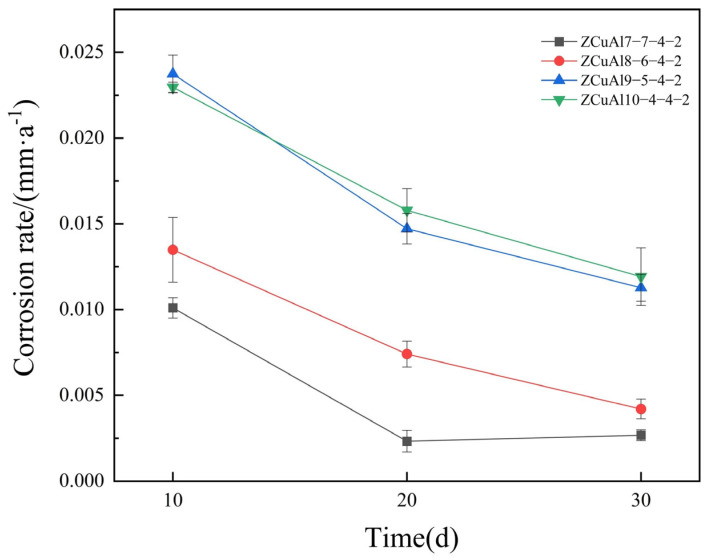

In [26]:
for i in [31,33,35,37,39,41,43,45,47,49,52]:
    if i<len(msgs) and msgs[i]['role']=='tool':
        print('\n=== MESSAGE',i,'===\n',msgs[i].get('content','')[:16000])
# Print candidate reconstruction code to inspect rather than execute opaque agent code.
for i in [55,59]:
    print('\n=== CODE',i,'===')
    for tc in msgs[i].get('tool_calls',[]):
        if tc['function']['name']=='run_cell':print(json.loads(tc['function']['arguments'])['code'][:18000])

In [27]:
from e14c.web import fetch_paper
sources=outdir/'sources';sources.mkdir(exist_ok=True)
dois={'Tan2024':'10.3390/ma17061330','Yang2018':'10.3390/ma11091777','Zhao2022':'10.3390/met12050781','Qian2025':'10.1007/s42114-024-01174-0','LewisLaQue1981':'10.2172/6255887'}
async def getsource(key,doi):
    try:
        bib=await cite_doi(doi);(sources/f'{key}.bib').write_text(bib)
        paper=await fetch_paper(doi=doi);(sources/f'{key}.json').write_text(json.dumps(paper,indent=2))
        txt='\n\n'.join(f'=== PAGE {p.get("page",i+1)} ===\n'+p.get('text','') for i,p in enumerate(paper.get('pages',[])))
        (sources/f'{key}.txt').write_text(txt);return key,len(txt)
    except Exception as ex:return key,str(ex)
print(await asyncio.gather(*[getsource(k,d) for k,d in dois.items()]))
print('Source files:',list(sources.glob('*')))
# Recover excerpts into local evidence files, explicitly labeled as delegated tool output.
for i in [52]:
    (outdir/f'mdpi_tables_delegated_{i}.txt').write_text(msgs[i]['content'])
print(msgs[52]['content'][:16000])

[('Tan2024', 68826), ('Yang2018', 32733), ('Zhao2022', 60219), ('Qian2025', 60777), ('LewisLaQue1981', 182383)]
Source files: [PosixPath('/workspace/outputs/sources/Yang2018.json'), PosixPath('/workspace/outputs/sources/Qian2025.txt'), PosixPath('/workspace/outputs/sources/Tan2024.json'), PosixPath('/workspace/outputs/sources/Tan2024.txt'), PosixPath('/workspace/outputs/sources/LewisLaQue1981.json'), PosixPath('/workspace/outputs/sources/Zhao2022.bib'), PosixPath('/workspace/outputs/sources/LewisLaQue1981.bib'), PosixPath('/workspace/outputs/sources/Zhao2022.txt'), PosixPath('/workspace/outputs/sources/Yang2018.txt'), PosixPath('/workspace/outputs/sources/Qian2025.json'), PosixPath('/workspace/outputs/sources/Qian2025.bib'), PosixPath('/workspace/outputs/sources/Tan2024.bib'), PosixPath('/workspace/outputs/sources/LewisLaQue1981.txt'), PosixPath('/workspace/outputs/sources/Zhao2022.json'), PosixPath('/workspace/outputs/sources/Yang2018.bib')]
[Appended Cell #13] [stdout]

 Tan2024
mate

In [28]:
texts={k:(sources/f'{k}.txt').read_text() for k in dois}
for k,terms in {'Qian2025':['Table 1','5401','10050','Table 4','B10','7 days'],'LewisLaQue1981':['43.2','150','Table III','TABLE III','0.6','Aluminum Bronze'],'Zhao2022':['Table 3','Area1','Area 1','Table 5','N-3','11.2'],'Yang2018':['0.0359','GB/T 2059','Figure 8']}.items():
    print('\n###',k)
    for term in terms:
        at=texts[k].lower().find(term.lower());print('\n',term,'index',at,'\n',texts[k][max(0,at-500):at+2300] if at>=0 else '')


### Qian2025

 Table 1 index 13427 
 value was about 8, and the temperature of    in the active area, there is no certain relationship between the
the artificial seawater was adjusted to about 25 °C. Because     level of natural corrosion potential and the corrosion rate.
the experiment used static seawater, the artificial seawater       In such a given corrosion system, there is neither net
was replaced every 12 h. The composition of the artificial    current flowing out from the metal surface nor net current
seawater is shown in Table 1.                                flowing into the metal surface, and the cathodic reaction and
  The experiments were conducted in a clean laboratory    anodic reaction are carried out under the same potential.
at 25 degrees centigrade and in a self-made facility. The   The electrode potential at this time is the natural corrosion
equipment is a 1.5L cylindrical container as a whole and is    potential of the metal. Whether immersed in static seawater

In [29]:
for k,term,window in [('Qian2025','Table 2',3500),('Qian2025','Table\u202f2',3500),('Qian2025','10050',3200),('Zhao2022','Area1',2800),('Zhao2022','Area 1',2800),('Zhao2022','Table 3.',5000),('LewisLaQue1981','43.2',4000),('LewisLaQue1981','150',1000)]:
    at=texts[k].lower().find(term.lower());print('\n###',k,term,at);print(texts[k][max(0,at-500):at+window] if at>=0 else '')
# Store compact source passages for every row.
audit_extract=[]
for k,terms in {'Tan2024':['Table 1.','Table 3.'],'Yang2018':['Table 1.','0.0359'],'Qian2025':['11.266','5401','10050'],'Zhao2022':['Table 3.','Table 5.'],'LewisLaQue1981':['43.2','TABLE III']}.items():
    for term in terms:
        at=texts[k].lower().find(term.lower())
        audit_extract.append(f'## {k}: {term}\n'+(texts[k][max(0,at-600):at+5000] if at>=0 else 'not located by literal text search'))
(outdir/'source_passages.md').write_text('\n\n'.join(audit_extract))


### Qian2025 Table 2 -1


### Qian2025 Table 2 29342
herefore, it can be concluded that from the perspective of
cathode metal and the anodic polarization curve of the anode    thermodynamics, the corrosion resistance of the two materi-
metal corresponds to the coupling potential and the coupling     als is similar.
current. This method is the result of approximate processing,      Figure 8 shows the corrosion current changes of B10 and
                                                    B30. The overall trend of the corrosion current is to rise


Table 2   Electrochemical                                                   3h            1d             3d             5d             7dimpedance spectrum parameters
of B10 alloy with different         Rs/Ω·cm2                 17.514         13.8894         13.2888         14.1876        31.9872
corrosion time                              n                         0.65959        0.48085         0.55788         0.57214       0.61867
         

61858

In [30]:
def findall_snip(k,term,n=4,before=100,after=1400):
    hits=list(re.finditer(re.escape(term),texts[k],re.I)); print(k,repr(term),'matches',len(hits))
    for mm in hits[-n:]:print('\n'+texts[k][max(0,mm.start()-before):mm.end()+after])
findall_snip('LewisLaQue1981','TABLE XIII',2,100,4300)
findall_snip('LewisLaQue1981','TABLE III',2,100,4500)
findall_snip('Qian2025','11.266',2,800,1000)
findall_snip('Zhao2022','Area1',2,500,1800)
findall_snip('Zhao2022','Area 1',2,500,1800)

LewisLaQue1981 'TABLE XIII' matches 3

shear stress above which,  in a flowinq system, accelerated
erosion-corrosion could occur.  Note in Table XIII that the critical shear
stress for C72200 is over five times greater than that for C71500.

      In an operating OTEC heat exchanqer fabricated with 25.4 mm  (1  inch)  diame­
ter tubes and operated at a flow rate of 1.8 m/s  (6 fps), the maximum surface
shear stress would be expected at the inlet end, equal to approximately
200 dyne/cm^ according to Sato and Nagata5^  in Fiqure  25.   In the 90%
blockaqe example, shown in Figure 26, they calculated,  for the same tube size
and similar flowrate,  a surface shear stress of 2646 dyne/cm2  (Table XII).
This value is far qreater than the critical shear stress for C70600 and C71500
presented by Efird,60 and only C72200 would appear to be resistant to

impinqement attack under those circumstances.

      It should be noted that the planned macrofoulinq control measures  in an
OTEC system shoul

In [31]:
k='LewisLaQue1981'
for term in ['TABLE XIV','TABLE III','Quiet','Al Bronze','Ni Al Bronze']:
    hits=list(re.finditer(re.escape(term),texts[k],re.I));
    mm=hits[-1] if term.startswith('TABLE') else (hits[-1] if hits else None)
    print('\n###',term)
    if mm:print(texts[k][max(0,mm.start()-200):mm.start()+6000])
# Reference figure, NAB interpolation to direct equilibrium spot checks.
w=[4.5,9.025,4.05,1.2];c=torch.tensor(w)/TP.WT_MAX
print('NAB interpolated', {f:float(TP.field(c,f)) for f in ['liquidus_C','solidus_C','range_C','kappa_fe_sol','nial_sol','beta_900','alpha_600']})
print('g distribution grid:',G.eval('(kappa_fe_sol+fcc_feni_sol)/.045').describe(percentiles=[.5,.9,.95,.99]).to_string())


### TABLE XIV
  12              479.0  (1.0)


C72200              12.0  (39.4)             27             2969.0  (6.2)





                                           42

=== PAGE 55 ===
                         TABLE XIV

       Galvanic Couple Data For C70600  and C71500
    With Other Materials in 0.6 m/s Flowing Seawater

         One Year Exposures - Equal Area Couples
                    (Inco Unpublished Data)

Uncoupled                                   Corrosion Rate
                                             pm/y  (mpy)


  C70600                                         30.5  (1.2)
  C71500                                        20.3  (0.8)
  Al Bronze                                    43.2  (1.7)
  Ni Al Bronze                                150.0  (5.9)
  Carbon Steel                                330.0  (13.0)
  Titanium                                     <2.5  (<0.1)



Couples


  C70600                                        25.4  (1.0)
  Al Bronze              

In [32]:
p=json.loads((sources/'LewisLaQue1981.json').read_text())
for page in p['pages']:
    if int(page.get('page',0)) in [44,45,46,47,48,59,60]:
        print('\n### PAGE',page['page'],'\n',page['text'][:14000])



### PAGE 44 
                                    TABLE III

                      Low Velocity Seawater Exposures of
                            Copper-Nickel Alloys
                                             (32)

                                                          Flowing Sea Water
                              Quiet Sea Water                          (2 FPS)
                         Corrosion       Pitting       Corrosion      Pitting
       Alloy              Rate  (MPY)         (Mils)        Rate  (MPY)        (Mils)

90-10 Cu-Ni (C70600)      0.2 - 0.6     1-2         0.5 - 1.1     1-2

70-30 Cu-Ni (C71500)      0.3 - 0.5     1-2         0.5 - 0.7     1-3

IN-838!  (C72200)           0.4  - 0.9              1           0.8 - 1.2             1





                                               32

### PAGE 45 
                                    TABLE IV

                        Corrosion ofC71900and C71500
                             in Low Velocity Seawater*
         

In [33]:
# Compare supplied alternatives numerically with the independent implementation.
comp=[]
variant_map={'Base':{},'Linear Al':{'al_form':'lin'},'Free signs':{'signs':False},'Linear Al; free signs':{'al_form':'lin','signs':False},'Ni scale 3':{'ni_scale':3},'Ni scale 8':{'ni_scale':8},'Ni scale 12':{'ni_scale':12},'Linear Ni':{'ni_form':'lin'},'Fe cap 1.0':{'fe_sol':1.0},'Fe cap 2.5':{'fe_sol':2.5},'No ridge':{'ridge':0},'Ridge 0.5':{'ridge':.5}}
for name,cfg in variant_map.items():
    sf=supplied.fit(supplied.load(),{**supplied.BASE,**cfg}); dif=max(abs(models[name]['coef'].get(k,0)-sf['coef'][k]) for k in ['ni','al','al2','fe'])
    comp.append({'fit':name,'max_coefficient_difference':dif})
print(pd.DataFrame(comp).to_string(index=False));(outdir/'supplied_fit_crosscheck.json').write_text(json.dumps(comp,indent=2))
# Construct exact, traceable additions. Do not force unknown compositions into numeric fitting columns.
adds=[]
def add(study,alloy,ni,al,fe,mn,rate,unit,test,source,use='sensitivity',**extra):
    adds.append(dict(study=study,alloy=alloy,ni=ni,al=al,fe=fe,mn=mn,rate=rate,unit=unit,test=test,weight=.5,use=use,source=source,**extra))
for i,r in D.iloc[:4].iterrows():
    add('Tan2024_10d',r.alloy,r.ni,r.al,r.fe,r.mn,[.50,1.34,1.77,2.16][i],'uA/cm2','10-day 3.5% NaCl; Tafel','10.3390/ma17061330 Table 3',use='replace_30d_not_independent_replication')
add('Tan2024_massloss30d','ZCuAl7-7-4-2',6.82,6.94,4.10,1.72,.00267,'mm/y','30-day 3.5% NaCl; mass loss','10.3390/ma17061330 abstract/Section 3.3',use='singleton_no_within_study_slope_information')
add('Zhao2022_N3','N-3',10.8,10.9,4.1,np.nan,4.09,'uA/cm2','3.5% NaCl; 20-min OCP then polarization','10.3390/met12050781 Tables 3,5',use='exclude_unmodeled_Cr1.9wt_and_layer_confound',Cr=1.9)
for alloy,ni,fe,mn,rates in [('B10',11.266,1.751,.725,[149.94,231.95,196.57,49.077,234.52]),('B30',30.05,.726,.718,[17.655,25.498,6.3465,18.453,28.7])]:
    for t,rate in zip(['3h','1d','3d','5d','7d'],rates):add('Qian2025_Tafel_'+t,alloy,ni,0,fe,mn,rate,'uA/cm2',f'artificial seawater; Tafel at {t}','10.1007/s42114-024-01174-0 Tables 4,5',use='replace_EIS_not_independent_replication')
# Author-reported grade shorthand: retained as nominal assumption, not measured assay.
for name,ni,fe,mn,rates in [('C70600',10,1.4,.8,[93.9,84.9]),('C71500',30,.6,.6,[95.1,89.5])]:
    for rep,rate in enumerate(rates,1):add('LewisLaQue1981_30d',name+f'_rep{rep}',ni,0,fe,mn,rate,'um/y','30-day clean seawater; 2m/s; uncoupled','10.2172/6255887 Table XVII printed p46',use='nominal_grade_composition_sensitivity')
# Fe-content data: use Ni-Fe values explicitly specified; Mn unreported.
for period,rrates in [('62d',[.0023,.0027,.0011]),('132d',[.0009,.0009,.0005])]:
    for ni,fe,rate in zip([10,10,30],[.7,1.5,.4],rrates):add('LewisLaQue1981_untreated_'+period,f'Cu-{ni}Ni-{fe}Fe',ni,0,fe,np.nan,rate,'inch/y',f'untreated seawater; 0.5ft/s; {period}','10.2172/6255887 Table XV printed p44',use='specified_Ni_Fe_Mn_unknown_sensitivity')
A=pd.DataFrame(adds);A.to_csv(outdir/'additional_data.csv',index=False)
print('Added exact candidate observations:',len(A))
# Correct known nominal Yang composition; no claim of a measured bulk assay.
Dc=D.copy(); Dc.loc[Dc.study.eq('Yang2018')&Dc.alloy.str.startswith('C70600'),['fe','mn']]=[1.,1.]
Dc.to_csv(outdir/'original_data_nominal_corrected.csv',index=False)


                  fit  max_coefficient_difference
                 Base                1.054712e-15
            Linear Al                1.660595e-08
           Free signs                6.272760e-15
Linear Al; free signs                9.908740e-15
           Ni scale 3                5.403467e-11
           Ni scale 8                9.992007e-16
          Ni scale 12                2.464695e-14
            Linear Ni                3.188944e-12
           Fe cap 1.0                3.079981e-10
           Fe cap 2.5                3.637788e-16
             No ridge                2.775558e-16
            Ridge 0.5                3.026358e-11
Added exact candidate observations: 26


In [34]:
for tid in taskids[1:]:
    st=await check_task(tid); print(tid,st.status,st.runtime_minutes)
    if st.status=='success':
        (outdir/f'agent_{tid}_answer.md').write_text(st.answer);print(st.answer[:25000])
# Local source-derived fitting sensitivities, clearly separated from trusted 30-day immersion inference.
A=pd.read_csv(outdir/'additional_data.csv'); A['weight']=.5
scenarios=[]
def scenario(name,dat,**opts):
    mod=independent_fit(dat=dat,label=name,**opts);models[name]=mod
    row={'fit':name,'n':mod['n'],'sse':mod['sse'],**{f'b_{k}':v for k,v in mod['coef'].items()}}
    for b in REFS:
        row[b]=optimized_floor(mod,b,mn_free=mod['options']['mn']); row[b]['certificate']=algebraic_lower_bound(mod,b)
    scenarios.append(row);print(name,[(b,row[b]['floor']) for b in REFS])
scenario('Yang nominal corrected',Dc)
scenario('No unconfirmed Yang comparator',Dc[~Dc.study.eq('Yang2018')])
scenario('Replace Qian EIS by 7d Tafel',pd.concat([Dc[~Dc.study.eq('Qian2025')],A[A.study.eq('Qian2025_Tafel_7d')]],ignore_index=True))
scenario('Add Lewis 30d clean-water pair',pd.concat([Dc,A[A.study.eq('LewisLaQue1981_30d')]],ignore_index=True))
scenario('Add Lewis untreated 62d/132d pairs',pd.concat([Dc,A[A.study.str.startswith('LewisLaQue1981_untreated')]],ignore_index=True))
scenario('Replace Tan30d by Tan10d',pd.concat([Dc[~Dc.study.eq('Tan2024')],A[A.study.eq('Tan2024_10d')]],ignore_index=True))
scenario('Mn excluding unreported Zhao',Dc[~Dc.study.eq('Zhao2022')],mn=True)
(outdir/'source_sensitivity.json').write_text(json.dumps(scenarios,indent=2));(outdir/'refits.json').write_text(json.dumps({'models':models,'floors':floorresults+scenarios},indent=2))

Task 9d06146d-044d-46e0-b41d-bdd9f7022e88 still running (status: in progress). Call check_task(task_id) again later.
9d06146d-044d-46e0-b41d-bdd9f7022e88 in progress 10.3557811


Task 4b09267c-8c61-4b21-b191-95086efb438e still running (status: in progress). Call check_task(task_id) again later.
4b09267c-8c61-4b21-b191-95086efb438e in progress 5.31523855


Yang nominal corrected [('9010', 0.9466253643359628), ('7030', 1.821657126168757)]


No unconfirmed Yang comparator [('9010', 5.471368014183679), ('7030', 7.999265648733418)]


Replace Qian EIS by 7d Tafel [('9010', 1.59708252287456), ('7030', 2.606768126535634)]


Add Lewis 30d clean-water pair [('9010', 0.7715661647746528), ('7030', 1.6138042980400362)]


Add Lewis untreated 62d/132d pairs [('9010', 2.1775542921351296), ('7030', 3.326905651254716)]


Replace Tan30d by Tan10d [('9010', 0.0), ('7030', 0.7086339096982722)]


Mn excluding unreported Zhao [('9010', 0.0), ('7030', 0.0)]


66891

In [35]:
# Verify precise passing witnesses just above the full-truth numerical boundaries.
for rec in fullfloor:
    w=np.array(rec['wt']);w[0]=np.ceil(w[0]*10000)/10000+0.0001;w[2]=3.6
    x=torch.tensor(np.r_[w/[30,9.5,4.5,4],rec['apv']]);o=truth.full(x)
    rec['strict_witness_wt']=w.tolist();rec['strict_witness_m']=float(o['m']);rec['strict_witness_feasible']=bool(TP.feasible(x));rec['m_minus_bar']=float(o['m'])-rec['mbar']
    print(rec['bar'],w,'passmargin',rec['m_minus_bar'],'feasible',rec['strict_witness_feasible'])
# Optimize reference process density continuously and compare the finite reference search.
refchecks=[]
for b,name in [('9010','C70600 (90-10 Cu-Ni)'),('7030','C71500 (70-30 Cu-Ni)')]:
    c=np.array(BA.REFERENCE[name]); start=fullrefs[b][2][4:].numpy()
    def loss(p):return -float(truth.full(torch.tensor(np.r_[c,p]))['rho_m'])
    opt=minimize(loss,start,bounds=[(0,1)]*3,method='SLSQP',options={'ftol':1e-13,'maxiter':100})
    out=truth.full(torch.tensor(np.r_[c,opt.x]));ideal=.85-.3*float(TP.ln_rate(torch.tensor(c)))
    refchecks.append(dict(bar=b,nominal_wt=(c*[30,9.5,4.5,4]).tolist(),sobol_m=fullrefs[b][0],sobol_rho=fullrefs[b][1],optimized_m=float(out['m']),optimized_rho=float(out['rho_m']),physically_dense_m=ideal,apv=opt.x.tolist()))
print(pd.DataFrame(refchecks).to_string(index=False))
(outdir/'reference_checks.json').write_text(json.dumps(refchecks,indent=2));(outdir/'full_truth_floors.json').write_text(json.dumps(fullfloor,indent=2))
# Quantify melt-fraction conservation defects and missing-range handling.
badrows=G[G[[f'{p}_sol' for p in ['liquid','alpha','beta','kappa_fe','fcc_feni','nial','gprime','other']]].sum(axis=1)<.99]
print('Nonconserving sol points:',badrows.index.tolist())
(outdir/'grid_integrity.json').write_text(json.dumps({'n':len(G),'ok':int(G.ok.sum()),'missing_liquidus':int(G.liquidus_C.isna().sum()),'zero_phase_sum_sol':badrows.index.tolist(),'missing_alpha600_compositions':int(G.alpha600_xni.isna().sum()),'sha256_mcni':sha},indent=2))
# Persist only project workflow conventions, not findings.
Path('.prompts/MEMORY.md').write_text('''# Project Memory\n\n## Context\n- Independent copper-alloy benchmark reviews are delivered as `outputs/report.md`, with source extracts and machine-readable analysis outputs alongside it.\n\n## Notes\n- Reports distinguish executed calculations, inspected code/data, and delegated evidence checks; include severity-tagged findings, optimized floor/witness tables, uncertainty, and discretionary decisions.\n- Establish an independent fitting implementation before comparing supplied fit code. Do not silently overwrite uploaded inputs.\n- In this deployment, data-retrieval subagents did not see parent workspace files despite the shared-workspace guide; pass essential input content and recover evidence through returned messages or registered artifacts.\n''')

9010 [1.62500000e+00 2.07363102e+00 3.60000000e+00 5.49758690e-12] passmargin 2.2873380131072096e-06 feasible True
7030 [2.43120000e+00 2.07392671e+00 3.60000000e+00 2.26474569e-16] passmargin 1.2246926526238155e-06 feasible True


 bar                           nominal_wt  sobol_m  sobol_rho  optimized_m  optimized_rho  physically_dense_m                                                            apv
9010              [9.99, 0.0, 1.395, 0.8] 0.831356   0.980238     0.832406       0.983736            0.837285   [0.40289078642507176, 0.615981178034161, 0.5329244259277192]
7030 [30.0, 0.0, 0.6749999999999999, 0.8] 0.842067   0.973555     0.842703       0.975678            0.850000 [0.46862698025192073, 0.5933473688107758, 0.46920548759291203]
Nonconserving sol points: [245, 854]


748

In [36]:
# Inspect substantive progress of bridge agents without blocking further local checks.
for tid in taskids[1:]:
    ms=await get_task_messages(tid)
    (outdir/f'agent_{tid}_messages.json').write_text(json.dumps(ms,default=str,indent=2))
    print('\nTASK',tid,'messages',len(ms))
    for m in ms[-8:]:
        if m.get('role')=='tool':print(str(m.get('content',''))[:10000])



TASK 9d06146d-044d-46e0-b41d-bdd9f7022e88 messages 163
[Appended Cell #55] [stdout]
[['Metal/alloy', '1'], ['Fe', '1'], ['C', '1'], ['Si', '1'], ['Mn', '1'], ['P', '1'], ['S', '1'], ['Cr', '1'], ['Ni', '1'], ['Mo', '1'], ['Cu', '1'], ['Al', '1'], ['N', '1'], ['Mg', '1'], ['Zn', '1'], ['O', '1'], ['Pb', '1'], ['Zn', '1']]
[['Cu', '1'], ['—', '1'], ['—', '1'], ['—', '1'], ['—', '1'], ['—', '1'], ['—', '1'], ['—', '1'], ['—', '1'], ['—', '1'], ['99.90', '1'], ['—', '1'], ['—', '1'], ['', '1'], ['', '1'], ['0.10 max', '1'], ['—', '1'], ['—', '1']]
[['NAB', '1'], ['4.43', '1'], ['—', '1'], ['0.05', '1'], ['0.14', '1'], ['—', '1'], ['—', '1'], ['—', '1'], ['4.65', '1'], ['—', '1'], ['bal.', '1'], ['9.31', '1'], ['—', '1'], ['0.01 max', '1'], ['0.11', '1'], ['—', '1'], ['0.02', '1'], ['—', '1']]
[['90−10 Ni-Cu', '1'], ['1.64', '1'], ['0.002', '1'], ['—', '1'], ['0.760', '1'], ['0.01', '1'], ['0.004', '1'], ['—', '1'], ['10.73', '1'], ['—', '1'], ['bal.', '1'], ['', '1'], ['—', '1'], ['', '1'


TASK 4b09267c-8c61-4b21-b191-95086efb438e messages 108
[Appended Cell #36] [stdout]
NRL MD5 cfba3a5c67c3d88aa8b20cec358838c7 cfba3a5c67c3d88aa8b20cec358838c7
Validated 29 contrasts; exact-source ratios match derived-rate ratios.
sizes [('bridge_sources_doi_raw.bib', 1338), ('bridge_sources.bib', 1588), ('retrieve_bridges.py', 8391), ('bridge_observations.csv', 52413), ('added_bridges.csv', 37861)]

[Appended Cell #37] [stdout]
report chars 15911

[Appended Cell #38] [stdout]
inventory 31 files
[('added_bridges.csv', 37861), ('audit_bridges.md', 26283), ('bridge_file_manifest.csv', 13429), ('bridge_observations.csv', 52413), ('bridge_sources.bib', 1588), ('bridge_sources_doi_raw.bib', 1338), ('retrieve_bridges.py', 8391)]

[Appended Cell #39] [stdout]
All 31 retained files readable/present with matching sizes and hashes; CSV reproduction succeeded.
Final main outputs /workspace/outputs/audit_bridges.md /workspace/outputs/added_bridges.csv



In [37]:
# Retrieve final answers, preserving delegated provenance.
for tid in taskids[1:]:
    st=await check_task(tid)
    print('\nTASK',tid,st.status)
    if st.status=='success':
        (outdir/f'agent_{tid}_answer.md').write_text(st.answer); print(st.answer)


Task 9d06146d-044d-46e0-b41d-bdd9f7022e88 still running (status: in progress). Call check_task(task_id) again later.

TASK 9d06146d-044d-46e0-b41d-bdd9f7022e88 in progress



TASK 4b09267c-8c61-4b21-b191-95086efb438e success
## Files Ready for Analysis

| File | Description | Format | Size |
|---|---|---|---:|
| `/workspace/outputs/added_bridges.csv` | **Analysis-ready:** 29 exact-source within-test alloy/Cu contrasts, with compositions, methods, durations, rates and derived natural log ratios | CSV | 37,861 B |
| `/workspace/outputs/bridge_observations.csv` | **Analysis-ready:** 55 material/test observations; preserves published values separately from derived rates | CSV | 52,413 B |
| `/workspace/outputs/audit_bridges.md` | Exact tables, source locations, relevance, uncertainty, exclusions and exhaustive file-level provenance | Markdown | 26,283 B |
| `/workspace/outputs/bridge_sources.bib` | Full bibliography; malformed DTIC author metadata corrected against original cover | BibTeX | 1,588 B |
| `/workspace/outputs/bridge_sources_doi_raw.bib` | Unmodified full BibTeX returned by e14c DOI APIs for all three targets | BibTeX | 1,338 B |
| `/workspace/outp

In [38]:
# Fetch complete exact table transcription from bridge-agent notebook messages.
ms=await get_task_messages(taskids[2]);(outdir/'bridge_agent_messages.json').write_text(json.dumps(ms,default=str,indent=2))
for i,m in enumerate(ms):
    c=str(m.get('content',''))
    if m['role']=='tool' and any(s in c for s in ['13.95','5.07','Cu-Al-Ni','transcriptions','3.77']):print('\nMESSAGE',i,'\n',c[:24000])



MESSAGE 14 
 [Edited Cell #2] [stdout]
/usr/bin/pdftotext


[stdout]
                                                                Available on line at
                                                                Association of the Chemical Engineers of Serbia AChE

Chemical Industry & Chemical Engineering Quarterly              www.ache.org.rs/CICEQ
                                                     Chem. Ind. Chem. Eng. Q. 27 (4) 383−394 (2021)                               CI&CEQ



             SENKA GUDIĆ1                            COMPARISON OF CORROSION BEHAVIOR
      LADISLAV VRSALOVIĆ1                            OF COPPER AND COPPER ALLOYS IN
            ANA RADELJIĆ1
                                                     AQUEOUS CHLORIDE SOLUTION
   EMEKA EMANUEL OGUZIE2
             IVANA IVANIĆ3                           Article Highlights
          STJEPAN KOŽUH3                             • A detailed comparison of the corrosion behavior of Cu and 4 Cu alloys in N

In [39]:
# Recover exact JSON transcription from the bridge-agent's executed code, not inferred prose.
for i,m in enumerate(ms):
    for tc in m.get('tool_calls',[]) or []:
        if tc['function']['name']=='run_cell':
            code=json.loads(tc['function']['arguments']).get('code','')
            if 'transcrip' in code or '13.95' in code or '5.07' in code:
                (outdir/f'bridge_code_{i}.py').write_text(code)
                print('\nCODE',i,'\n',code[:18000])



CODE 45 
 print('NRL p3 text',n_pages[5][:5500]);print('NRL p20',n_pages[22][:15000]);print('NRL p15',n_pages[17][:9000]);
# Render printed tables only: exact table transcription is not graph digitization.
for pnum in [6,23,18]:
 subprocess.run(['pdftoppm','-f',str(pnum),'-l',str(pnum),'-scale-to','2400','-png','-singlefile',str(src/'DTIC_AD0644930.pdf'),str(src/f'NRL_table_pdfpage{pnum}')],check=True,capture_output=True)


CODE 89 
 im=Image.open(src/'NRL_table_pdfpage25.png');im.rotate(-90,expand=True).save(src/'NRL_TableA1_rotated.png')
# Log exact source transcriptions in JSON, keeping decimals as printed strings.
transcription={
 'ciceq':{
 'doi':'10.2298/CICEQ200701007G','url':'https://www.ache-pub.org.rs/CICEQ/2021/No4/CICEQ_No4_2021/08_4854_2021.pdf',
 'table1_compositions_wt_percent':[
 {'material':'Cu','Cu':'99.90'},
 {'material':'Cu-Al','Cu':'90.90','Al':'9.10'},
 {'material':'Cu-Al-Ni','Cu':'84.67','Al':'11.29','Ni':'4.05'},
 {'material':'Cu-Al-Mn','Cu':'82.30','Al':'8.30'

In [40]:
# Download newly found primary PDFs locally and cite each source before using its data.
newdoi={'Gudic2021':'10.2298/CICEQ200701007G','Southwell1966':'10.21236/ad0644930','Dhar1985':'10.5006/1.3582011'}
for k,doi in newdoi.items():
    try:(sources/f'{k}.bib').write_text(await cite_doi(doi))
    except Exception as ex:print('citation',k,type(ex).__name__)
for k,url in {'Gudic2021':'https://www.ache-pub.org.rs/CICEQ/2021/No4/CICEQ_No4_2021/08_4854_2021.pdf','Southwell1966':'https://archive.org/download/DTIC_AD0644930/DTIC_AD0644930.pdf'}.items():
    res=requests.get(url,timeout=120); print(k,res.status_code,len(res.content))
    if res.status_code==200 and res.content.startswith(b'%PDF'):
        (sources/f'{k}.pdf').write_bytes(res.content)
        subprocess.run(['pdftotext','-layout',str(sources/f'{k}.pdf'),str(sources/f'{k}.txt')],check=True)
# Parse literal transcription assignment via ast.literal_eval, without executing external code.
import ast
code=(outdir/'bridge_code_89.py').read_text(); tree=ast.parse(code)
for node in tree.body:
    if isinstance(node,ast.Assign) and any(isinstance(t,ast.Name) and t.id=='transcription' for t in node.targets): trans=ast.literal_eval(node.value)
(outdir/'bridge_exact_transcription.json').write_text(json.dumps(trans,indent=2))
print((sources/'Gudic2021.txt').read_text()[5000:16000])


Gudic2021 200 2943365


Southwell1966 200 1794198
atigue resistance of
                                                                                Cu-Al alloys exceeds that of austenitic stainless
                                                                                steels. Additionally, they can be machined or ground
Correspondence: L. Vrsalović, University of Split, Faculty of
                                                                                and are readily weldable [4,6,7]. Upon addition of Ni
Chemistry and Technology, Ruđera Boškovića 35, 21000 Split,
Croatia.                                                                        or/and Mn to Cu-Al alloys, new alloys can be pro-
E-mail: ladislav@ktf-split.hr                                                   duced that exhibit specific properties, including Cu
Paper received: 1 July, 2020
                                                                                shape memory alloys (SMAs). An SMA remembers its
Paper revised

In [41]:
# Recover full low-Ni audit final and numerical transcription (isolated workspace).
st=await check_task(taskids[1]);print(st.status);(outdir/f'agent_{taskids[1]}_answer.md').write_text(st.answer)
print(st.answer[:29000])
lowmsgs=await get_task_messages(taskids[1]);(outdir/'lowNi_agent_messages.json').write_text(json.dumps(lowmsgs,default=str,indent=2))
for i,m in enumerate(lowmsgs):
    for tc in m.get('tool_calls',[]) or []:
        if tc['function']['name']=='run_cell':
            co=json.loads(tc['function']['arguments']).get('code','')
            if any(term in co for term in ['1.6,','1.6, ','NCEL','13.95','99.90','1968','0.012']):
                (outdir/f'lowNi_code_{i}.py').write_text(co)
                if 'add(' in co or 'ncel' in co.lower() or 'rows=' in co:print('\nCODE',i,'\n',co[:27000])


success
## Files Ready for Analysis

| File | Description | Format | Size |
|---|---|---|---:|
| `/workspace/outputs/added_lowNi.csv` | **85 measured records:** 74 mass-loss rates, 8 Tafel currents, 3 LPR currents; exact compositions, conditions and source locations | CSV | 84.5 KiB |
| `/workspace/outputs/audit_lowNi.md` | Primary evidence tables, Qian/Lewis source audits and limitations | Markdown | 20.1 KiB |
| `/workspace/outputs/audited_source_values.csv` | 17 verified Qian/Lewis source values, separate from primary additions | CSV | 4.8 KiB |
| `/workspace/outputs/lowNi_sources.bib` | Complete bibliography saved through e14c citation APIs | BibTeX | 4.5 KiB |
| `/workspace/downloads/lowNi/source_evidence.zip` | Supporting evidence: original PDFs, parsed papers, table images and access logs | ZIP | 76.4 MiB |
| `/workspace/outputs/source_manifest.json` | Provenance, endpoints, parameters, transformations and checksums for every evidence member | JSON | 83.7 KiB |
| `/workspace/out


CODE 152 
 rows=[]
retrieved='2026-10-28'
url68='https://archive.org/download/corrosionofmater04rein/corrosionofmater04rein.pdf'
def add(**kw):
 d=dict(record_id=f'LN{len(rows)+1:04d}',measurement_status='measured_source_reported',is_constructed=False,retrieval_date=retrieved,source_version='as published',genome_build='not applicable',rate_qualifier='=',comparison_scope='within_same_test_only',notes='')
 d.update(kw); rows.append(d)
env={123:(5640,2.3,1.3,34.51,7.6,.03,'I-3'),403:(6780,2.2,1.6,34.40,7.7,.03,'I-4'),751:(5640,2.3,1.3,34.51,7.6,.03,'I-2'),197:(2340,5.0,.4,34.36,7.5,.06,'II-1'),402:(2370,5.0,.4,34.36,7.5,.06,'II-2'),1064:(5300,2.6,1.2,34.51,7.5,.03,'I-1')}
materials68={
 'Cu_NCEL':('Copper, O Free','102',{'Cu':99.96},'Table 2, p25, PDF29','oxygen-free copper; source plate/coupon, not tubing'),
 'Cu_INCO':('Copper, O Free','102',{'Cu':99.9},'Table 2, p25, PDF29','oxygen-free copper; source plate/coupon, not tubing'),
 '95_5_NCEL':('Cu-Ni, 95-5','704',{'Cu':91.98,'Ni':6.25,

In [42]:
# Print specific low-Ni transcription code only (avoid the lengthy prose report).
for pth in sorted(outdir.glob('lowNi_code_*.py')):
    co=pth.read_text()
    if ('6.25' in co or 'NCEL' in co) and ('records' in co or 'ncel' in co.lower()):
        print('\nFILE',pth.name,'LEN',len(co),'\n',co[:36000])



FILE lowNi_code_152.py LEN 12254 
 rows=[]
retrieved='2026-10-28'
url68='https://archive.org/download/corrosionofmater04rein/corrosionofmater04rein.pdf'
def add(**kw):
 d=dict(record_id=f'LN{len(rows)+1:04d}',measurement_status='measured_source_reported',is_constructed=False,retrieval_date=retrieved,source_version='as published',genome_build='not applicable',rate_qualifier='=',comparison_scope='within_same_test_only',notes='')
 d.update(kw); rows.append(d)
env={123:(5640,2.3,1.3,34.51,7.6,.03,'I-3'),403:(6780,2.2,1.6,34.40,7.7,.03,'I-4'),751:(5640,2.3,1.3,34.51,7.6,.03,'I-2'),197:(2340,5.0,.4,34.36,7.5,.06,'II-1'),402:(2370,5.0,.4,34.36,7.5,.06,'II-2'),1064:(5300,2.6,1.2,34.51,7.5,.03,'I-1')}
materials68={
 'Cu_NCEL':('Copper, O Free','102',{'Cu':99.96},'Table 2, p25, PDF29','oxygen-free copper; source plate/coupon, not tubing'),
 'Cu_INCO':('Copper, O Free','102',{'Cu':99.9},'Table 2, p25, PDF29','oxygen-free copper; source plate/coupon, not tubing'),
 '95_5_NCEL':('Cu-Ni, 95-5','704

In [43]:
co=(outdir/'lowNi_code_152.py').read_text()
print(co[5000:12500])
# Download exact original report for independent table checks.
url68='https://archive.org/download/corrosionofmater04rein/corrosionofmater04rein.pdf'
rr68=requests.get(url68,timeout=120);print('report',rr68.status_code,len(rr68.content))
if rr68.content.startswith(b'%PDF'):
    (sources/'Reinhart1968.pdf').write_bytes(rr68.content);subprocess.run(['pdftotext','-layout',str(sources/'Reinhart1968.pdf'),str(sources/'Reinhart1968.txt')],check=True)
# Save a full primary-report citation verified from retrieval.
save_citation('''@techreport{Reinhart1968hydrospace,
 author={Reinhart, Fred M.}, title={Corrosion of Materials in Hydrospace. Part IV. Copper and Copper Alloys}, institution={Naval Civil Engineering Laboratory}, address={Port Hueneme, California}, number={Technical Note N-961}, year={1968}, url={https://archive.org/details/corrosionofmater04rein}, note={Original report downloaded and tables inspected, accessed 2026-10-28}}
''')


ur==123 else 46,49 if dur==123 else 50)
  else:loc=(15,60,64) if key.startswith('70') else (15,59,63) if dur==402 else (15,58,62)
  attack={123:'SL DA',403:'SL DA; C12; P12m,6.6a',751:'MD DA; C7; P12m,7.9a'}.get(dur,'U') if key.startswith('Al7') else 'U'
  if key=='90_10_NCEL' and dur==402:attack='U; severe corrosion in small area (footnote 5)'
  hist(key,dur,rate,*loc,attack)
# INCO participants share each corresponding STU deployment; do not mix with NCEL as replicates.
for key,vals in [('Cu_INCO',[1.5,1.3,1.0,1.4,1.4,.5]),('90_10_INCO',[.8,.6,.6,.8,.8,.7]),('70_30_INCO',[1.3,1.2,.9,.9,.6,.6]),('Al5_INCO',[.6,.2,.3,.4,.2,.2]),('Al7_INCO',[.6,.2,1.5,.3,.2,.2])]:
 for dur,rate in zip(coh+[1064],vals):
  if key.startswith('Cu_'):loc=(3,26,30)
  elif key.startswith('Al5'):loc=(11,45,49)
  elif key.startswith('Al7'):loc=(11,45 if dur==123 else 46,49 if dur==123 else 50)
  else:loc=(15,60,64) if key.startswith('70') else (15,59,63) if dur==402 else (15,58,62)
  attack='U'
  if key=='70_30_

report 200 5623889


PosixPath('/workspace/citations/local-copper-review/363efb39-4ddb-4cbd-945b-ed3c72073d1b.bib')

In [44]:
# Recreate historical source records from inspected, bounded code section only.
co=(outdir/'lowNi_code_152.py').read_text();histcode=co[:co.index("print('Historical primary rows'")]
ns={'json':json};exec(histcode,ns);Hraw=pd.DataFrame(ns['rows'])
H=[]
for r in ns['rows']:
    c=json.loads(r['composition_wt_pct'])
    H.append(dict(study=r['test_group'],alloy=r['alloy_label'],ni=c.get('Ni',0),al=c.get('Al',0),fe=c.get('Fe',0),mn=c.get('Mn',0),rate=r['rate_value'],weight=.5,unit=r['rate_unit'],source=r['source_url']+' '+r['table_or_section']+' p'+str(r['printed_page']),test=r['environment']+' '+str(r['test_duration_days'])+'d',use=1,attack=r['attack_as_reported'],participant=r['participant'],censored=r['rate_qualifier']!='='))
H=pd.DataFrame(H);H.to_csv(outdir/'historical_bridge_data.csv',index=False);Hraw.to_csv(outdir/'historical_bridge_metadata.csv',index=False)
print('Original source historical rows',H.shape)
# Check original table text and retain source pages, not just returned delegated records.
htxt=(sources/'Reinhart1968.txt').read_text();hpages=htxt.split('\f')
for pn in [29,30,45,49,58,61,62,63,64]:
    (sources/f'Reinhart1968_page{pn}.txt').write_text(hpages[pn-1])
print('Original composition table page 61\n',hpages[60][:15000])
print('Rate table page62\n',hpages[61][:15000])
print('Chronology page 30\n',hpages[29][:15000])


Original source historical rows (71, 15)
Original composition table page 61
                                                                                                                                                                              AoT
                                                                                                                                                                             4se9

                                                                                                                                                                                              roa)|
                                                                                                                                                                             Te
                                                                                                                                                                                              —
   

In [45]:
# Rotate original scanned tabular pages for verifiable local inspection (no graph digitization).
from PIL import Image
for pn in [30,61,62,63,64]:
    prefix=sources/f'Reinhart1968_p{pn}'
    subprocess.run(['pdftoppm','-f',str(pn),'-l',str(pn),'-scale-to','2800','-png','-singlefile',str(sources/'Reinhart1968.pdf'),str(prefix)],check=True,capture_output=True)
    im=Image.open(str(prefix)+'.png'); print(pn,im.size);im.rotate(90,expand=True).save(sources/f'Reinhart1968_p{pn}_rotated.png')
# Bridge sensitivity variants: isolate one matched deployment, then a whole-program influence-capped fit.
B=H[H.study.eq('Reinhart1968_I-3_123d_W_NCEL')].copy()
print('Matched 123d NCEL bridge\n',B.to_string(index=False))
scenario('Add 123d Cu/CuNi-only bridge',pd.concat([Dc,B[B.al==0]],ignore_index=True))
scenario('Add 123d Cu/CuNi/Al bronze bridge',pd.concat([Dc,B],ignore_index=True))
# Whole historic report total weight=2, rather than 71 independent equal-weight study observations.
HC=H[~H.censored].copy();HC['weight']=2/len(HC)
scenario('Add all historical bridges; report weight2',pd.concat([Dc,HC],ignore_index=True))
HN=HC[HC.al==0].copy();HN['weight']=2/len(HN)
scenario('Add all historical Cu/CuNi; report weight2',pd.concat([Dc,HN],ignore_index=True))
scenario('Strict data +123d Cu/CuNi bridge',pd.concat([Dc[Dc.study.isin(['Tan2024','Qian2025'])],B[B.al==0]],ignore_index=True))
# New zero-Ni Cu-Al controls outside the binary series: low-weight sensitivity, not target-domain validation.
C=[]
for comp,rate in zip(trans['ciceq']['table1_compositions_wt_percent'],trans['ciceq']['table2_icorr_uA_cm2']):
    C.append(dict(study='Gudic2021',alloy=comp['material'],ni=float(comp.get('Ni',0)),al=float(comp.get('Al',0)),fe=0,mn=float(comp.get('Mn',0)),rate=float(rate),weight=.5,unit='uA/cm2',test='0.5M NaCl; 20C; OCP60min+EIS then polarization',source='10.2298/CICEQ200701007G Tables1,2',use=1))
C=pd.DataFrame(C);C.to_csv(outdir/'gudic_bridge_data.csv',index=False)
scenario('Add Gudic Cu/CuAl pair only',pd.concat([Dc,C.iloc[:2]],ignore_index=True))
scenario('Add Gudic all alloys (outside box)',pd.concat([Dc,C],ignore_index=True))
(outdir/'source_sensitivity.json').write_text(json.dumps(scenarios,indent=2));(outdir/'refits.json').write_text(json.dumps({'models':models,'floors':floorresults+scenarios},indent=2))

30 (1979, 2800)


61 (1965, 2800)


62 (1965, 2800)


63 (1965, 2800)


64 (1965, 2800)


...

Add all historical Cu/CuNi; report weight2 [('9010', 0.7033373363344592), ('7030', 1.5331582359397973)]


Strict data +123d Cu/CuNi bridge [('9010', 9.99999999999882), ('7030', 29.999999994169386)]


Add Gudic Cu/CuAl pair only [('9010', 1.3313734068644285), ('7030', 2.2834859780172896)]


Add Gudic all alloys (outside box) [('9010', 3.930908275747787), ('7030', 5.654781103636902)]


82085

In [46]:
for pn in [30,61,62,63,64]:
    im=Image.open(sources/f'Reinhart1968_p{pn}.png');im.rotate(-90,expand=True).save(sources/f'Reinhart1968_p{pn}_upright.png')


In [47]:
# Share passing is a measure on design distribution, not volume in composition alone.
# Execute an independently seeded uniform design diagnostic, not the missing check_phys.py.
X=torch.quasirandom.SobolEngine(7,scramble=True,seed=2728).draw(262144).double();vv=truth.full(X);feas=TP.feasible(X)
share=[]
for b in REFS:
    passed=vv['m']>=fullrefs[b][0]
    share.append(dict(bar=b,n=len(X),feasible_fraction=float(feas.double().mean()),pass_fraction_given_feasible=float(passed[feas].double().mean()),pass_fraction_box=float((passed&feas).double().mean()),seed=2728))
print(share)
# Optimize smooth soft-gated objective with constrained SLSQP from the best screened Sobol points.
mb=fullrefs['9010'][0];J=BA.objective_from(vv['U'],vv['m'],X,mb);J[~feas]=-1e5
idxs=torch.topk(J,8).indices;candidate=[]
for ix in idxs:
    x0=X[ix].numpy();
    def obj(x):
        xx=torch.tensor(x);o=truth.full(xx);return -float(BA.objective_from(o['U'],o['m'],xx,mb))
    def limits(x):
        xx=torch.tensor(x);w=TP.wt(xx[:4]);n,a,f,m=w.tolist()
        return np.array([35-w.sum(),(1250-TP.field(xx[:4],'liquidus_C'))/100, (n-f)/30 if a>7 else 1.,(2.3-f)/4.5 if a<1.5 else 1.],float)
    op=minimize(obj,x0,bounds=[(0,1)]*7,constraints={'type':'ineq','fun':limits},method='SLSQP',options={'ftol':1e-10,'maxiter':200})
    if limits(op.x).min()>-1e-7:candidate.append(op)
best=min(candidate,key=lambda r:r.fun);xx=torch.tensor(best.x);outs=truth.full(xx)
optrec={'J':-float(best.fun),'wt':(best.x[:4]*[30,9.5,4.5,4]).tolist(),'apv':best.x[4:].tolist(),'outputs':{k:float(v) for k,v in outs.items()},'strength_MPa':float(TP.strength_mpa(xx[:4])),'liquidus':float(TP.field(xx[:4],'liquidus_C')),'successful':bool(best.success)}
print(optrec)
(outdir/'independent_design_diagnostics.json').write_text(json.dumps({'shares':share,'optimum_found':optrec},indent=2))

[{'bar': '9010', 'n': 262144, 'feasible_fraction': 0.738128662109375, 'pass_fraction_given_feasible': 0.008976929755653864, 'pass_fraction_box': 0.006626129150390625, 'seed': 2728}, {'bar': '7030', 'n': 262144, 'feasible_fraction': 0.738128662109375, 'pass_fraction_given_feasible': 0.0062688634390374995, 'pass_fraction_box': 0.004627227783203125, 'seed': 2728}]


{'J': 0.30028315007786927, 'wt': [15.100248282961871, 2.4051501204864922, 0.8999999855878638, 1.1520441886668528e-18], 'apv': [0.3920192521963713, 0.6058174919088263, 0.5289770309329129], 'outputs': {'s': 0.4613884043551376, 'f': 0.10504812824496422, 'g': 0.0, 'h': 0.16808103610508193, 'q': 0.9961377117632804, 'rho_u': 0.7450563002529622, 'rho_m': 0.9919513763911442, 'beta': 0.06620169229603028, 'U': 0.5971151940772383, 'w': 0.825711971057883, 'm': 0.8987971561691336}, 'strength_MPa': 359.90246283083945, 'liquidus': 1139.610883630157, 'successful': True}


1214

In [48]:
# Inspect all resource references and truth-switch logic; do not infer absent policy enforcement.
lines=Path('bofn_alloy.py').read_text().splitlines()
for i,l in enumerate(lines):
    if any(s in l for s in ['truth_phys','BOFN_TRUTH','feasible(','phys_m_ref','TRUTH ==','m_ref']):
        print(i+1,'\n'+'\n'.join(lines[max(0,i-2):min(len(lines),i+5)]))
# Save coefficients and witnesses in compact extractable tables.
def witness(r,b):
    cert=r[b].get('certificate')
    if cert and cert.get('proposal_feasible') and cert.get('witness') is not None:return cert['witness']
    return r[b]['witness']
for r in floorresults+scenarios:
    if r['fit'] in ['Base','Free signs','Linear Al','Add Mn','Add Ni x Al','Drop Lewis + Zhao (weak rows)','Strict data +123d Cu/CuNi bridge','Add 123d Cu/CuNi-only bridge','Add 123d Cu/CuNi/Al bronze bridge']:
        print(r['fit'], models[r['fit']]['coef'])
        print([(b,r[b]['floor'],witness(r,b)) for b in REFS])
# Store current notebook cell sources as a transparent execution log.
history=get_ipython().history_manager.input_hist_raw
(outdir/'executed_analysis_cells.py').write_text('\n\n# === NEXT EXECUTED CELL ===\n\n'.join(history[1:]))


27 
    K  one-hour screen (Ni, Al, Fe, rho_m, beta)    -> w screen index
    I  30-day immersion (Ni, Al, Fe, rho_m, beta, w) -> m immersion index
    objective J = U * sigmoid((m - m_ref) / 0.05) - LAMBDA * B(c)
    B = 1.0 Ni + 0.3 Al + 0.2 Mn (known critical-mineral burden), m_ref = immersion
    index of dense 70-30 Cu-Ni (C71500) at its best settings.

`rho_u` is a model input of `rho_m` and `w` a model input of `m` so the GPs can learn
28 
    I  30-day immersion (Ni, Al, Fe, rho_m, beta, w) -> m immersion index
    objective J = U * sigmoid((m - m_ref) / 0.05) - LAMBDA * B(c)
    B = 1.0 Ni + 0.3 Al + 0.2 Mn (known critical-mineral burden), m_ref = immersion
    index of dense 70-30 Cu-Ni (C71500) at its best settings.

`rho_u` is a model input of `rho_m` and `w` a model input of `m` so the GPs can learn
the small-step-to-large-step and screen-to-immersion transfers; the truth links each
58 
INI, IAL, IFE, IMN = 0, 1, 2, 3
P_CAP = 0.5  # Utah's MX-Lab laser power cap on the sca

68158

                  fit  bar  nominal_fitter_floor  network_reference_floor
                 Base 9010              0.946625                 0.944989
                 Base 7030              1.821657                 1.821657
           Free signs 9010              0.000000                 0.000000
           Free signs 7030              0.000000                 0.000000
               Add Mn 9010              0.000000                 0.000000
               Add Mn 7030              0.388434                 0.388434
Linear Al; free signs 9010              0.000000                 0.000000
Linear Al; free signs 7030              0.000000                 0.000000
Best grid-profile scale {'ni_scale': np.float64(22.695105366946684), 'sse': 0.45119568525795173, 'penalized_loss': np.float64(0.4876860579955413), 'bNi': np.float64(-0.7640986557877271)}


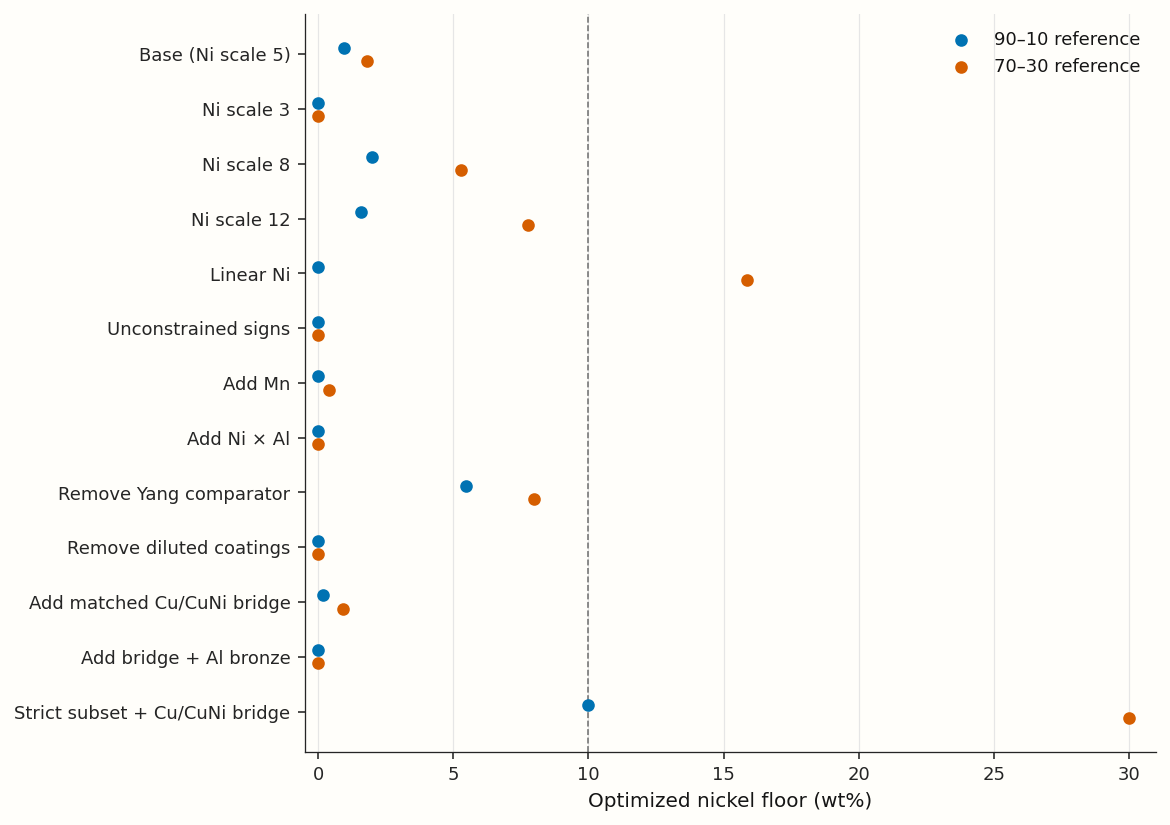

In [49]:
# Reference-composition discrepancy affects free-Fe/Mn fits: evaluate sensitivity explicitly.
actual_refs={b:np.array(rec['nominal_wt']) for b,rec in zip(['9010','7030'],refchecks)}
ref_sensitivity=[]
originalrefs={k:v.copy() for k,v in REFS.items()}
for name in ['Base','Free signs','Add Mn','Linear Al; free signs']:
    for b in REFS:
        before=next(r for r in floorresults if r['fit']==name)[b]['floor']
        REFS[b]=actual_refs[b]
        after=optimized_floor(models[name],b,mn_free=models[name]['options']['mn'])
        ref_sensitivity.append({'fit':name,'bar':b,'nominal_fitter_floor':before,'network_reference_floor':after['floor']})
        REFS[b]=originalrefs[b]
print(pd.DataFrame(ref_sensitivity).to_string(index=False));(outdir/'reference_composition_sensitivity.json').write_text(json.dumps(ref_sensitivity,indent=2))
# Ni-form fit profile (same priors/scales as comparison, not claimed model selection).
profile=[]
for scale in np.geomspace(1,100,60):
    mo=independent_fit(scale=float(scale));profile.append({'ni_scale':scale,'sse':mo['sse'],'penalized_loss':mo['sse']+.05*sum(x*x for x in mo['coef'].values()),'bNi':mo['coef']['ni']})
pd.DataFrame(profile).to_csv(outdir/'ni_scale_profile.csv',index=False)
print('Best grid-profile scale',min(profile,key=lambda r:r['penalized_loss']))
# Draw a compact publication-quality two-bar sensitivity chart, preserving numeric tables separately.
import matplotlib.pyplot as plt
plt.rcParams.update({'font.family':'DejaVu Sans','font.size':9,'axes.spines.top':False,'axes.spines.right':False,'pdf.fonttype':42,'axes.labelsize':10})
sel=['Base','Ni scale 3','Ni scale 8','Ni scale 12','Linear Ni','Free signs','Add Mn','Add Ni x Al','Drop Yang2018','Drop Zhao2022','Add 123d Cu/CuNi-only bridge','Add 123d Cu/CuNi/Al bronze bridge','Strict data +123d Cu/CuNi bridge']
lookup={r['fit']:r for r in floorresults+scenarios}
fig,ax=plt.subplots(figsize=(8.2,5.8)); y=np.arange(len(sel))
for off,b,col,lab in [(-.12,'9010','#0072B2','90–10 reference'),(.12,'7030','#D55E00','70–30 reference')]:
    ax.scatter([lookup[s][b]['floor'] for s in sel],y+off,s=28,color=col,label=lab,zorder=3)
ax.set_yticks(y,labels=['Base (Ni scale 5)','Ni scale 3','Ni scale 8','Ni scale 12','Linear Ni','Unconstrained signs','Add Mn','Add Ni × Al','Remove Yang comparator','Remove diluted coatings','Add matched Cu/CuNi bridge','Add bridge + Al bronze','Strict subset + Cu/CuNi bridge'])
ax.invert_yaxis();ax.set_xlabel('Optimized nickel floor (wt%)');ax.axvline(10,ls='--',lw=.8,color='0.45');ax.grid(axis='x',color='0.9',lw=.6);ax.set_xlim(-.5,31)
ax.legend(frameon=False,loc='upper right');fig.tight_layout();fig.savefig(outdir/'floor_sensitivity.png',dpi=350,bbox_inches='tight');fig.savefig(outdir/'floor_sensitivity.pdf',bbox_inches='tight');display(fig);plt.close(fig)


In [50]:
# Add exact secondary Fe-series measurements reproduced in Lewis Table XX, not hidden as primary.
feextra=pd.DataFrame([dict(study='Popplewell1973_via_Lewis1981',alloy=f'Cu10Ni{fe}Fe',ni=10.,al=0.,fe=fe,mn=0.,rate=rate,weight=.25,unit='um/y',test='60d; 3.4% NaCl; reproduced measurement',source='10.2172/6255887 Table XX printed p49; original ref37 not checked',use=1) for fe,rate in [(0,38.4),(.3,33.0),(1.5,12.2)]])
feextra.to_csv(outdir/'additional_fe_series.csv',index=False)
scenario('Add secondary 60d Fe series',pd.concat([Dc,feextra],ignore_index=True))
# New tropical exposure pair: do not double-count nested 1/2/4/8/16 year averages.
N=[]
for material in ['Cu','Cu-Al']:
    comp=trans['nrl']['tableA1_compositions_wt_percent']['immersion_'+material]
    for j,years in enumerate(trans['nrl']['table1_years']):
        penetration=float(trans['nrl']['table1_average_penetration_mil']['continuous_seawater'][material][j])
        N.append(dict(study='Southwell1966_'+str(years)+'y',alloy=material,ni=0,al=float(comp.get('Al',0)),fe=float(comp.get('Fe',0)),mn=0,rate=penetration/years,weight=.25,unit='mil/y',test=f'continuous tropical seawater; {years} years; cumulative penetration/time',source='10.21236/AD0644930 Tables1,A1',use=1,penetration_mil=penetration,years=years))
N=pd.DataFrame(N);N.to_csv(outdir/'southwell_immersion_bridge.csv',index=False)
scenario('Add 1y tropical Cu/CuAl bridge',pd.concat([Dc,N[N.years==1]],ignore_index=True))
# Bibliography and exact extra source extracts.
for key,doi in [('Walsh2024','10.1149/1945-7111/ad81b5'),('Zhu2017','10.1016/S1003-6326(17)60128-6')]:
    (sources/f'{key}.bib').write_text(await cite_doi(doi))
    try:
        paper=await fetch_paper(doi=doi);txt='\n\n'.join(p['text'] for p in paper.get('pages',[]));(sources/f'{key}.txt').write_text(txt)
        print(key,len(txt))
    except Exception as ex:print(key,type(ex).__name__)
(outdir/'source_sensitivity.json').write_text(json.dumps(scenarios,indent=2));(outdir/'refits.json').write_text(json.dumps({'models':models,'floors':floorresults+scenarios},indent=2))


Add secondary 60d Fe series [('9010', 0.9466253643801438), ('7030', 1.8216571261583994)]


Add 1y tropical Cu/CuAl bridge [('9010', 0.4874171007465975), ('7030', 1.2792322317531373)]


Walsh2024 64678


Zhu2017 HTTPStatusError


86488

In [51]:
# Create machine-readable 16-row audit, each reconciled to primary/full source text.
audit_rows=[]
notes=[
('Tan2024 Table1/Table3','verified','Ni6.82 Al6.94 Fe4.10 Mn1.72; i_corr0.35 at30d; current not 30d cumulative mass loss'),
('Tan2024 Table1/Table3','verified','Ni6.13 Al7.90 Fe3.92 Mn2.12; i_corr0.36 at30d'),
('Tan2024 Table1/Table3','verified','Ni5.18 Al8.94 Fe4.12 Mn2.18; i_corr0.69 at30d'),
('Tan2024 Table1/Table3','verified','Ni3.99 Al9.94 Fe3.94 Mn1.82; i_corr0.78 at30d; Al outside proposal box'),
('Yang2018 Table1 Section3.3','rate verified','nominal7Ni3Al1Fe1Mn; massloss0.0215mm/y at10d; artificial seawater'),
('Yang2018 Section3.4 Conclusion2','composition correction / comparability uncertain','rate0.0359mm/y explicitly commercialC70600; source shorthand10Ni1Fe1Mn, not assumed1.4Fe0.8Mn; no independent comparator methods/form'),
('Qian2025 Section2/Table2','proxy verified, not rate','actualNi11.266 Fe1.751 Mn0.725; Rct5401.604 at7d; inverse constructed1.8513e-4; ignores Stern-Geary variation; Zr/Hg omitted'),
('Qian2025 Section2/Table3','proxy verified, not rate','actualNi30.050 Fe0.726 Mn0.718; Rct10050.6 at7d; inverse constructed9.9497e-5; Zr/Si omitted'),
('LewisLaQue1981 TableIII printedp32','constructed midpoint','range0.2-0.6mpy;0.4 not measured datum; duration missing; review; heat chemistry not given'),
('LewisLaQue1981 TableIII printedp32','constructed midpoint','range0.3-0.5mpy;0.4 not measured datum; duration missing; review; heat chemistry not given'),
('LewisLaQue1981 TableXIV printedp43','rate verified / unknown grade','43.2um/y uncoupled1y0.6m/s; Al bronze unspecified; assigningC61400/7Al2.5Fe unsupported'),
('LewisLaQue1981 TableXIV printedp43','rate verified / unknown grade','150um/y uncoupled1y0.6m/s; NiAl bronze unspecified; assigningC95800/4.5Ni9.25Al4Fe1.2Mn unsupported'),
('LewisLaQue1981 TableXIV printedp43','rate verified / nominal composition','30.5um/y uncoupled1y0.6m/s; actual heat chemistry/form not supplied; review of unpublishedINCO'),
('LewisLaQue1981 TableXIV printedp43','rate verified / nominal composition','20.3um/y uncoupled1y0.6m/s; actual heat chemistry/form not supplied; review of unpublishedINCO'),
('Zhao2022 Table3 Area1/Table5','rate/local chemistry verified; exclude from homogeneous-alloy calibration','7.82uA/cm2;11.2Fe3.8Ni9.8Al regionalEDS;steel dilution; Mn unreported, not analytical0'),
('Zhao2022 Table3 Area2/Table5','rate/local chemistry verified; processing confound','4.65uA/cm2;4Fe12.4Ni10.4Al regionalEDS;NiAl interlayer changes substrate/dilution/microstructure; Mn unreported'),
]
for i,(r,nt) in enumerate(zip(D.to_dict('records'),notes),2):
    loc,status,note=nt;audit_rows.append({'csv_line':i,'study':r['study'],'alloy':r['alloy'],'value':r['rate'],'source_location':loc,'status':status,'note':note})
pd.DataFrame(audit_rows).to_csv(outdir/'row_audit.csv',index=False)
# Integrity manifests for original inputs; preservation is verifiable.
inputs=['truth_phys.py','corrosion_data.csv','fit_corrosion.py','corrosion_fit.json','corrosion_fit.md','calphad_grid.py','calphad_grid.csv','phys_tables.md','phys_tables.json','bofn_alloy.py']
manifest={f:hashlib.sha256(Path(f).read_bytes()).hexdigest() for f in inputs};(outdir/'input_sha256.json').write_text(json.dumps(manifest,indent=2))
from e14c.web import citation_files
bibfiles=sorted(sources.glob('*.bib'));bibs='\n\n'.join(p.read_text() for p in bibfiles)
# Include library-saved non-DOI sources/corrections, preserving full entries.
for p in citation_files():
    if p.exists():bibs+='\n\n'+p.read_text()
(outdir/'references.bib').write_text(bibs)
print('Audit rows',len(audit_rows),'source fulltext files',len(list(sources.glob('*.txt'))),'bibliography bytes',len(bibs))


Audit rows 16 source fulltext files 18 bibliography bytes 9705


In [52]:
# Quantify whether using a truly dense external reference changes the seven-dimensional floor.
ref_floor_extra=[]
for typ in ['continuous_DED_reference','ideal_dense_reference']:
    for rc in refchecks:
        b=rc['bar'];mbar=rc['optimized_m'] if typ.startswith('continuous') else rc['physically_dense_m']
        seed=next(r for r in fullfloor if r['bar']==b);w=np.array(seed['wt']);w[2]=3.6
        # Hold Fe at its found grid knot to remove a nonsmooth coordinate; optimize the other six.
        x0=np.r_[w/[30,9.5,4.5,4],seed['apv']]; free=[0,1,3,4,5,6]
        def pack(z):x=x0.copy();x[free]=z;return x
        def con(z):return full_constraints(pack(z),mbar,False)
        op=minimize(lambda z:30*z[0],x0[free],bounds=[(0,1),(1.5/9.5,7/9.5),(0,1),(0,1),(0,1),(0,1)],constraints={'type':'ineq','fun':con},method='SLSQP',options={'ftol':1e-11,'maxiter':200})
        x=pack(op.x);ref_floor_extra.append({'reference_definition':typ,'bar':b,'mref':mbar,'floor_found':30*x[0],'wt':(x[:4]*[30,9.5,4.5,4]).tolist(),'success':bool(op.success),'minimum_constraint':float(con(op.x).min())})
print(pd.DataFrame(ref_floor_extra).to_string(index=False));(outdir/'reference_definition_full_floors.json').write_text(json.dumps(ref_floor_extra,indent=2))
# Flat extractable tables, using analytically certified simple witnesses when available.
allrows=floorresults+scenarios
rows=[]
for r in allrows:
    row={'fit':r['fit'],'n':r['n'],'weighted_SSE':r['sse'],**models[r['fit']]['coef']}
    for b in REFS:
        row[f'floor_{b}']=r[b]['floor']
        for k,val in zip(['Ni','Al','Fe','Mn'],witness(r,b)):row[f'{b}_{k}']=val
    rows.append(row)
pd.DataFrame(rows).to_csv(outdir/'refits.csv',index=False)
print('Floor calculations:',len(allrows)*2)


    reference_definition  bar     mref  floor_found                                                                   wt  success  minimum_constraint
continuous_DED_reference 9010 0.832406     1.698329  [1.6983289848896215, 2.07360653312542, 3.6, 2.9253063265101145e-15]     True        6.994405e-15
continuous_DED_reference 7030 0.842703     2.483389                    [2.4833893689333255, 2.073983449286868, 3.6, 0.0]     True        8.437695e-15
   ideal_dense_reference 9010 0.837285     2.054982 [2.0549824663676644, 2.0736440691498386, 3.6, 3.424197187569439e-16]     True       -1.987521e-12
   ideal_dense_reference 7030 0.850000     3.125006                   [3.1250060799271804, 2.0749649234871876, 3.6, 0.0]     True       -6.746825e-13
Floor calculations: 82


In [53]:
for pth in sorted(sources.glob('*.bib')):
    print(pth.name,pth.read_text()[:750])
# Ensure no negative or below-proposal witnesses slipped in under numeric tolerance.
viol=[]
for r in floorresults+scenarios:
    for b in REFS:
        w=np.array(witness(r,b));n,a,f,m=w
        if n<-1e-6 or a<-1e-6 or f<-1e-6 or m<-1e-6 or w.sum()>35+1e-5 or (a>7+1e-6 and n<f-1e-5) or (a<1.5-1e-6 and f>2.3+1e-5) or liquidus(w).item()>1250+1e-5:viol.append((r['fit'],b,w))
print('Witness violations:',viol)


Dhar1985.bib @article{Dhar_1985, title={Corrosion of Cu and Cu-Ni Alloys in 0.5M NaCl and in Synthetic Seawater}, volume={41}, ISSN={1938-159X}, url={http://dx.doi.org/10.5006/1.3582011}, DOI={10.5006/1.3582011}, number={6}, journal={Corrosion}, publisher={Association for Materials Protection and Performance (AMPP)}, author={Dhar, H. P. and White, R. E. and Burnell, G. and Cornwell, L. R. and Griffin, R. B. and Darby, R.}, year={1985}, month=June, pages={317–323} }
Gudic2021.bib @article{Gudic_2021, title={Comparison of corrosion behaviour of copper and copper alloys in aqueous chloride solution}, volume={27}, ISSN={2217-7434}, url={http://dx.doi.org/10.2298/CICEQ200701007G}, DOI={10.2298/ciceq200701007g}, number={4}, journal={Chemical Industry and Chemical Engineering Quarterly}, publisher={National Library of Serbia}, author={Gudic, Senka and Vrsalovic, Ladislav and Radeljic, Ana and Oguzie, Emanuel and Ivanic, Ivana and Kozuh, Stjepan and Gojic, Mirko}, year={2021}, pages={383–394} 

In [54]:
# Correct malformed report author metadata against the source title page.
corrected='''@techreport{SouthwellHummerAlexander1966NRL6452,
 author={Southwell, C. R. and Hummer, Jr., C. W. and Alexander, A. L.},
 title={Corrosion of Metals in Tropical Environments. Part 7---Copper and Copper Alloys---Sixteen Years' Exposure},
 institution={Naval Research Laboratory}, address={Washington, D.C.}, number={NRL Report 6452},
 year={1966}, month=oct, day={28}, doi={10.21236/AD0644930}, url={https://archive.org/details/DTIC_AD0644930},
 note={DTIC accession AD0644930; author parsing corrected against the report title page}}
'''
save_citation(corrected);(sources/'Southwell1966_corrected.bib').write_text(corrected)
runner='''"""Reproduce independent sensitivity floors. Run: python outputs/reproduce_refits.py"""
from pathlib import Path
import json, sys
import pandas as pd
HERE=Path(__file__).resolve().parent
sys.path.insert(0,str(HERE))
from independent_refit import independent_fit,optimized_floor,algebraic_lower_bound
'''
datasets={
'Yang nominal corrected':Dc,
'No unconfirmed Yang comparator':Dc[~Dc.study.eq('Yang2018')],
'Replace Qian EIS by 7d Tafel':pd.concat([Dc[~Dc.study.eq('Qian2025')],A[A.study.eq('Qian2025_Tafel_7d')]]),
'Add Lewis 30d clean-water pair':pd.concat([Dc,A[A.study.eq('LewisLaQue1981_30d')]]),
'Add Lewis untreated 62d/132d pairs':pd.concat([Dc,A[A.study.str.startswith('LewisLaQue1981_untreated')]]),
'Replace Tan30d by Tan10d':pd.concat([Dc[~Dc.study.eq('Tan2024')],A[A.study.eq('Tan2024_10d')]]),
'Mn excluding unreported Zhao':Dc[~Dc.study.eq('Zhao2022')],
'Add 123d Cu/CuNi-only bridge':pd.concat([Dc,B[B.al==0]]),
'Add 123d Cu/CuNi/Al bronze bridge':pd.concat([Dc,B]),
'Add all historical bridges; report weight2':pd.concat([Dc,HC]),
'Add all historical Cu/CuNi; report weight2':pd.concat([Dc,HN]),
'Strict data +123d Cu/CuNi bridge':pd.concat([Dc[Dc.study.isin(['Tan2024','Qian2025'])],B[B.al==0]]),
'Add Gudic Cu/CuAl pair only':pd.concat([Dc,C.iloc[:2]]),
'Add Gudic all alloys (outside box)':pd.concat([Dc,C]),
'Add secondary 60d Fe series':pd.concat([Dc,feextra]),
'Add 1y tropical Cu/CuAl bridge':pd.concat([Dc,N[N.years==1]])}
datadir=outdir/'refit_inputs';datadir.mkdir(exist_ok=True)
records=[]
for i,(name,kw) in enumerate(variants):
    kw=kw.copy();dat=kw.pop('dat',D);fn=f'variant_{i:02}.csv';dat.to_csv(datadir/fn,index=False);records.append({'name':name,'data':fn,'options':kw})
for i,(name,dat) in enumerate(datasets.items()):
    fn=f'source_{i:02}.csv';dat.to_csv(datadir/fn,index=False);records.append({'name':name,'data':fn,'options':{'mn':True} if name=='Mn excluding unreported Zhao' else {}})
(outdir/'refit_config.json').write_text(json.dumps(records,indent=2))
runner+='''
results=[]
for cfg in json.loads((HERE/'refit_config.json').read_text()):
    dat=pd.read_csv(HERE/'refit_inputs'/cfg['data'])
    mod=independent_fit(dat=dat,label=cfg['name'],**cfg['options'])
    floors={}
    for bar in ['9010','7030']:
        floors[bar]=optimized_floor(mod,bar,mn_free=mod['options']['mn'])
        floors[bar]['certificate']=algebraic_lower_bound(mod,bar)
    results.append({'fit':cfg['name'],'model':mod,'floors':floors})
    print(cfg['name'],{b:floors[b]['floor'] for b in floors},flush=True)
(HERE/'reproduced_refits.json').write_text(json.dumps(results,indent=2))
'''
(outdir/'reproduce_refits.py').write_text(runner)
import py_compile
py_compile.compile(str(outdir/'independent_refit.py'),doraise=True);py_compile.compile(str(outdir/'reproduce_refits.py'),doraise=True)
print('Reproduction script syntax checked:',len(records),'datasets')


Reproduction script syntax checked: 41 datasets


In [55]:
# Start an end-to-end reproduction from the packaged scripts (separate process, same ordinary limits).
log=(outdir/'reproduction.log').open('w')
proc=subprocess.Popen(['python',str(outdir/'reproduce_refits.py')],stdout=log,stderr=subprocess.STDOUT)
print('Reproduction running; PID',proc.pid)
# Assemble concise, numeric report tables directly from executed result records.
def floortable(rr):
    out=['| Independent fit / data change | Ni floor: 90–10 | Witness (Ni, Al, Fe) | Ni floor: 70–30 | Witness (Ni, Al, Fe) |','|---|---:|---|---:|---|']
    for r in rr:
        vs=[]
        for b in REFS:
            w=witness(r,b);vs += [f'{r[b]["floor"]:.3f}', '('+', '.join(f'{q:.3f}' for q in w[:3])+')']
        out.append('| '+r['fit']+' | '+' | '.join(vs)+' |')
    return '\n'.join(out)
base_table=floortable(floorresults)
source_table=floortable(scenarios)
print(base_table)
print(source_table)


Reproduction running; PID 99
| Independent fit / data change | Ni floor: 90–10 | Witness (Ni, Al, Fe) | Ni floor: 70–30 | Witness (Ni, Al, Fe) |
|---|---:|---|---:|---|
| Base | 0.947 | (0.947, 2.613, 0.000) | 1.822 | (1.822, 2.613, 0.000) |
| No ridge | 1.453 | (1.453, 2.755, 0.000) | 2.431 | (2.431, 2.755, 0.000) |
| Ridge 0.5 | 0.000 | (0.000, 2.066, 0.000) | 0.000 | (0.000, 2.066, 0.000) |
| Linear Al | 0.000 | (0.000, 0.000, 0.000) | 0.000 | (0.000, 0.000, 0.000) |
| Free signs | 0.000 | (0.000, 2.301, 0.000) | 0.000 | (0.000, 2.301, 0.000) |
| Linear Al; free signs | 0.000 | (0.000, 0.000, 0.000) | 0.000 | (0.000, 0.000, 0.000) |
| Ni scale 3 | 0.000 | (0.000, 2.227, 0.000) | 0.000 | (0.000, 2.227, 0.000) |
| Ni scale 8 | 1.982 | (1.982, 2.937, 0.000) | 5.268 | (5.268, 2.937, 0.000) |
| Ni scale 12 | 1.591 | (1.591, 2.995, 0.000) | 7.771 | (7.771, 2.995, 0.000) |
| Linear Ni | 0.000 | (0.000, 2.861, 0.000) | 15.857 | (15.857, 2.861, 0.000) |
| Fe cap 1.0 | 0.947 | (0.947, 2.613, 

In [56]:
report_head=r'''# Independent review: does this copper-alloy benchmark establish a nickel floor?

**Verdict: no robust positive nickel floor is established, and I would not restrict the search to Ni ≥ 10 wt%.** The physics-based version is a useful *what-if simulator*, not a validated truth for 30-day seawater performance. Its fitted floor depends strongly on the imposed nickel response, aluminum response, data exclusions and reference definition.

I independently fitted the data **before reading the supplied fitting implementation**, then compared coefficients. I obtained the same base coefficients to within \(1.1\times10^{-15}\). My continuous, constrained film-only floors are **0.947 wt% Ni against 90–10** and **1.822 wt% against 70–30**, rather than the supplied grid-rounded 1.0 and 1.9. In the full inherited process model I found passing witnesses at **1.625 and 2.4312 wt% Ni**, respectively. These are synthetic-model results, not experimentally demonstrated alloy limits.

I also found and added a genuine **same-deployment pure-Cu/Cu–Ni immersion bridge** in Reinhart's original 1968 report. Adding its four Cu/Cu–Ni records reduces the base film-only floors to **0.195 and 0.938 wt% Ni**. The exposure was **123 days in cold, deep seawater**, not the target 30-day surface-seawater test; it does not settle the target floor. The nominal “95–5” coupon actually contains **6.25 wt% Ni**. Exact measured Cu–2Ni/Cu–5Ni target-test evidence remains missing.

**Scope and evidence labels.** This review distinguishes **executed** numerical checks, **inspected** code/source evidence, and **delegated retrieval**. All original inputs were preserved; hashes are in `input_sha256.json`. I accessed the full text of all five cited sources underlying the original 16 rows, but Lewis–LaQue is itself a review and does not provide all underlying primary-test details. Numerical tables and code accompany this report; uncertainty ranges below are sensitivity ranges, **not confidence intervals**.

## 1. Findings and severity

| Severity | Finding | Quantitative consequence / action |
|---|---|---|
| **Changes the conclusion** | A positive Ni floor is not robust to defensible model choices. | Original-data alternatives give 90–10 floors **0–5.471** and 70–30 floors **0–15.857 wt%**. Removing weak evidence and retaining a strict, data-poor subset can instead give **10/30**. This instability is non-identifiability, not evidence for one cutoff. |
| **Changes the conclusion** | Low-Ni predictions are extrapolations in composition, processing **and test endpoint**. | Only four original observations are electrochemical measurements after 30 days; there is no original paired 30-day mass-loss comparison spanning pure Cu to Cu–Ni. Do not call the fitted response “ln(30-day rate)” without qualification. |
| **Changes the conclusion** | The original dataset's apparent zero-Ni anchor is an **unspecified aluminum bronze assigned a guessed composition**. | Its 43.2 µm/y rate is real, but Ni=0/Al=7/Fe=2.5 is not established for that coupon. The associated NAB grade/composition is also guessed. Remove these from composition-resolved primary fitting. |
| **Changes the conclusion** | The consequential low-Al benefit rests partly on an incompletely documented Yang comparator; the Ni constraint also borrows leverage from steel-diluted coatings. | Dropping Yang raises floors to **5.471/7.999**; dropping Zhao gives **0/0**. Neither should quietly determine an exclusion boundary. |
| **Changes the conclusion** | The score is not “tensile strength counted only if immersion passes.” | The implemented logistic gate counts **50%** of strength at the bar and **26.9%** at \(m=m_{ref}-0.05\), before the mineral penalty. Use a hard gate for the stated objective, or rename the utility. |
| **Changes the conclusion** | mc_ni is not validated for Cu-rich alloys. | The actual database header says it was tested at **Cu < 0.5 wt%**, whereas the search requires **Cu ≥ 65 wt%**. It has no explicit Cu–Al–Ni ternary parameter set. CALPHAD here is a hypothesis generator. |
| **Changes a number; potentially the conclusion** | A spot-checked NAB-like grid point has a different near-solidus equilibrium than an independent solve with the same database. | At Cu balance–4.286Ni–9.5Al–3.6Fe, stored liquid fraction is **0.95730**, versus **0.08340** independently at the stated solidus+1 °C. Stored Fe-rich bcc is **0.02745**; my solve instead has Cu-rich bcc and no separate Fe-rich bcc. This changes the nucleant index from **0.61 to 0** under the stated labeling. Audit the generator/solver before trusting crack benefits. |
| **Changes a number** | The base fitting arithmetic is reproducible, but the supplied film-floor calculation is a grid search. | Continuous floors are **0.946625/1.821657**, with optimal Al **2.613206 wt%**. The code's 0.1-wt% grid explains 1.0/1.9; it does not establish optimized precision. |
| **Changes a number** | Qian's rows are inverse charge-transfer resistance, not measured penetration rates. | Their ratio is **1.859** using the rounded CSV; the same paper's seven-day Tafel-current ratio is **8.171**. Replacing, not stacking, the endpoint gives **1.597/2.607** floors. |
| **Changes a number** | Two quiet-water “rates” are constructed range midpoints, not exact measured observations. | Both 0.4 mpy values come from **0.2–0.6** and **0.3–0.5 mpy** ranges with unspecified duration. Their equality is constructed. |
| **Changes a number** | The reference is a modeled porous deposit, not a truly dense external coupon, and a finite process search misses its best density. | Supplied reference \(m\): **0.831356/0.842067**; continuous best-density deposits: **0.832406/0.842703**; ideal dense references: **0.837285/0.850000**. Full-model low-Ni witnesses still exist below 10 under all three definitions. |
| **Changes a number** | A same-test pure-Cu bridge was missed. | Four matched historical Cu/Cu–Ni records change film floors to **0.195/0.938**. Adding the matched Al bronze gives **0/0**, but that bronze also shows selective attack: average loss alone is not an adequate local-corrosion criterion. |
| **Changes a number** | “Fe in solution” is actually capped nominal Fe; the base Fe coefficient hits zero. | Changing the cap from 1 to 2.5 wt% or removing it does nothing in this fit. That is a boundary solution, not evidence that Fe partitioning is understood. |
| **Changes a number** | The grid contains silent incomplete phase results. | **864/864** rows say `ok=1`; **33** liquidus/range values are missing, and **two** solidus+1 phase-fraction sums are zero. Six alpha-composition records are missing because alpha is absent. Preserve validity/censoring masks. |
| **Changes a number** | Conductivity is physically motivated but only approximate; strength/cracking mappings remain largely hand-set. | Model resistivity for C71500 is **42.2**, versus its own quoted handbook **37.5 µΩ cm**. The crack thresholds correspond to **68/112 °C equilibrium freezing ranges**, with no new DED calibration. |
| **Changes a number / reproducibility** | Flattened uploads do not match runtime paths; the CALPHAD generator depends on an absent helper. | `truth_phys.py` expects `phys/calphad_grid.csv` and `phys/corrosion_fit.json`; I redirected these **in memory only**. `run_calphad.py` and the policy/check scripts were not uploaded. End-to-end policy enforcement cannot be certified. |
| **Cosmetic, unless used as a decision** | “No worse” needs inclusive equality and a numerical tolerance. | `phys_tables.md` labels the 90–10 reference itself “no,” despite using it to set the bar. A reference at its defining settings should pass. |

## 2. Row-by-row data audit

**Executed/inspected:** I retrieved and read full source text for Tan, Yang, Qian, Zhao and Lewis–LaQue, reconciled all 16 original rows, and saved `row_audit.csv` and source text/extracts. Retrieval agents independently supplied primary-table checks, but could not see parent-workspace files. I recovered their executed evidence through task messages and reconciled it locally; I do **not** claim their isolated output paths exist here.

CSV line numbers below include the header. Source abbreviations resolve to the DOI references in §8.

| CSV line | Row and reported value | Check against source and disposition |
|---:|---|---|
| 2 | Tan: 6.82Ni–6.94Al–4.10Fe–1.72Mn; 0.35 µA/cm² | **Verified**, Tables 1 and 3, 30-day polarization. Same preparation/test as the other Tan rows. Not cumulative mass loss. |
| 3 | Tan: 6.13Ni–7.90Al–3.92Fe–2.12Mn; 0.36 | **Verified**, same tables and endpoint. |
| 4 | Tan: 5.18Ni–8.94Al–4.12Fe–2.18Mn; 0.69 | **Verified**, same tables and endpoint. |
| 5 | Tan: 3.99Ni–9.94Al–3.94Fe–1.82Mn; 0.78 | **Verified**. Its Al lies outside the proposed 9.5-wt% search limit; useful as nearby calibration, not an admissible design. Strong covariation of Ni and Al prevents independent identification of their effects. |
| 6 | Yang: nominal 7Ni–3Al–1Fe–1Mn; 0.0215 mm/y | **Verified**, Table 1 and §3.3: cast alloys, ten-day static artificial seawater, mass loss. Other Al-series rates are graph-only; I did not invent exact values. |
| 7 | Yang commercial C70600; 0.0359 mm/y | **Rate verified**, §3.4 and conclusion. Source shorthand is **Cu–10Ni–1Fe–1Mn**, not the CSV's assumed 1.4Fe/0.8Mn. Comparator-specific batch, form and conditioning are insufficiently documented to certify a strict same-test pair. I tested retaining and dropping it. |
| 8 | Qian B10; 0.000185 inverse Ω cm² | **Rct verified**: 5401.604 Ω cm² at seven days, Table 2. Inversion gives 0.00018513. Chemistry 11.266Ni/1.751Fe/0.725Mn is verified; Zr and Hg are omitted from the model. A derived impedance proxy, not measured mass loss. |
| 9 | Qian B30; 0.0000995 | **Rct verified**: 10050.6 Ω cm², Table 3; inverse 0.000099497. Chemistry 30.050Ni/0.726Fe/0.718Mn is verified; Zr/Si are omitted. Same seven-day uncoupled electrochemical endpoint, not the separate coupled-current measurement. |
| 10 | Lewis quiet C70600; 0.4 mpy | **Constructed midpoint** of 0.2–0.6 mpy, Table III, printed p.32. Duration and coupon chemistry are not supplied. “Wrought tube” is not established by this table alone. |
| 11 | Lewis quiet C71500; 0.4 mpy | **Constructed midpoint** of 0.3–0.5 mpy, same table. Generic grade chemistry is not an analyzed heat composition. |
| 12 | Lewis aluminum bronze; 43.2 µm/y | **Rate and matched condition verified**, Table XIV, p.43: uncoupled one-year exposure, 0.6 m/s seawater. Grade unspecified. Assigning C61400 and 7Al/2.5Fe is unsupported. |
| 13 | Lewis NAB; 150 µm/y | **Rate and condition verified**, same table. Grade unspecified; assigning C95800 and the listed chemistry is unsupported. |
| 14 | Lewis C70600; 30.5 µm/y | **Verified** same uncoupled exposure. Heat chemistry and product-form details remain unavailable; secondary reproduction of unpublished INCO data. |
| 15 | Lewis C71500; 20.3 µm/y | **Verified**, same limitations. The paired 90–10/70–30 rate ratio is 1.502. |
| 16 | Zhao N-1; 7.82 µA/cm² | **Verified**, Tables 3/5: regional upper-coating EDS 3.8Ni/9.8Al/**11.2Fe**. Steel-diluted coating, not homogeneous benchmark feedstock. Mn is unreported, not measured zero. |
| 17 | Zhao N-2; 4.65 µA/cm² | **Verified**, regional EDS 12.4Ni/10.4Al/4Fe. NiAl interlayer changes dilution, microstructure and substrate interactions. Same polarization protocol does not remove these confounders. |

**No outright numeric rate mistranscription was found in these 16 rows.** The important problems are unsupported chemistry, constructed proxies/midpoints, and comparability—not a decimal-point error. I corrected Yang's source nominal chemistry in a separate output without changing the uploaded CSV. Its correction leaves the constrained base fit unchanged because the Fe coefficient is zero and Mn is omitted.

### What within-study ratios do—and do not—solve

A study intercept cancels a multiplicative rate/unit factor **if both observations measure the same endpoint with a composition-independent conversion**. It does not cancel casting versus commercial processing, flow/oxygen dependence, selective attack, temperature, duration-dependent film development, or the difference between charge-transfer resistance and mass loss. Nor does it make all slopes transferable across studies. In particular, Stern–Geary conversion depends on polarization slopes; inverse \(R_{ct}\) need not be proportional to alloy penetration rate with one common constant.

### Added and missed same-test evidence

**The important new bridge is primary immersion evidence.** Reinhart1968, Tables 2/3/14/15, contains the following **NCEL, fully exposed seawater, 123-day, 5,640-ft deployment**. I downloaded the original scanned report and checked the composition and rate table images locally.

| Material | Ni | Al | Fe | Mn | Mass-loss rate, mpy | mm/y |
|---|---:|---:|---:|---:|---:|---:|
| Oxygen-free Cu | 0 | 0 | no intentional addition | no intentional addition | 1.6 | 0.04064 |
| Nominal 95–5, actually 6.25Ni | 6.25 | 0 | 1.24 | 0.53 | 1.5 | 0.03810 |
| 90–10 coupon | 9.42 | 0 | 1.16 | 0.38 | 1.6 | 0.04064 |
| 70–30 coupon | 30.53 | 0 | 0.53 | 0.33 | 1.2 | 0.03048 |

The report tabulates chemistry; it does not consistently distinguish analyzed from nominal composition. “No intentional addition” is not an analytical zero. The same report has a matched 6.59Al–3.15Fe bronze at **0.5 mpy**, but flags **slight dealloying**. The setting is approximately **2.3 °C, low dissolved oxygen**, not warm aerated seawater. I therefore use it as a transferability sensitivity, not a replacement target-test dataset. Pure Cu equals the 90–10 coupon at the displayed precision in this deployment; that alone does not establish equality at 30 days in the proposal's environment.

I reconstructed **71 historical records**, preserving deployment and participant groups and a censored value, in `historical_bridge_data.csv` and `historical_bridge_metadata.csv`. I did not collapse exposures of different depth/duration into one intercept or count NCEL and INCO as interchangeable replicates. The all-history sensitivity caps the whole report's total row weight at **2** and excludes the censored record. Those reconstructions were delegated and selected primary tables were checked locally; I did not independently re-read every one of the 71 added rows from the scans.

Other source-supported additions and exclusions:

- **Tan2024:** the missed ten-day polarization series is **0.50, 1.34, 1.77, 2.16 µA/cm²**. I tested replacing the 30-day series with it, not treating time points as independent new studies. The exact 30-day mass-loss minimum is **0.00267 mm/y**, but only one exact composition-linked mass-loss value is available in text; it cannot identify within-study slopes alone.
- **Qian2025:** Tables 4/5 provide five matched Tafel pairs from three hours to seven days. The seven-day values are **234.52 versus 28.70 µA/cm²**. I tested replacing the EIS proxy with this pair rather than double-counting both endpoints.
- **Lewis–LaQue:** Table XVII supplies missed **30-day, clean seawater, 2 m/s** measurements: C70600 **93.9, 84.9** and C71500 **95.1, 89.5 µm/y**. These are review-reproduced data with grade-level, not measured heat, chemistry. Table XV has additional untreated 62/132-day Cu–Ni–Fe comparisons. Table XX reproduces a **60-day, 3.4% NaCl** Fe series: Cu–10Ni with 0/0.3/1.5Fe gives **38.4/33.0/12.2 µm/y**. I label that series secondary and do not relabel 3.4% as 3.5%.
- **Gudić2021:** primary Tables 1/2 connect pure Cu to Cu–Al and Cu–Al–Ni in **0.5 M NaCl, 20 °C**. Currents are **13.95, 6.56, 5.17, 3.48, 2.83 µA/cm²** for Cu, Cu–9.10Al, Cu–11.29Al–4.05Ni, Cu–8.30Al–9.40Mn, and Cu–13Al–2.5Ni–2.5Mn. Only the Cu/Cu–9.10Al pair lies wholly within the composition box. Conditioning is 60-min open-circuit potential **plus impedance testing**, not 30-day immersion. I retain the outside-box series only as a deliberately adverse extrapolation sensitivity.
- **Southwell, Hummer & Alexander1966:** primary tropical exposure tables connect Cu and **5.07Al–0.08Fe bronze**. One-year continuous-seawater penetration is **1.21 versus 0.18 mil**, equivalent to annualized rates with a ratio **0.149**. The 1/2/4/8/16-year records are nested cumulative exposures; I use only the one-year pair in the fit sensitivity, not five independent replications. Atmospheric bronze has different chemistry and is excluded from this seawater fit.
- **Zhao N-3:** missed current **4.09 µA/cm²**, chemistry 10.8Ni/10.9Al/4.1Fe/**1.9Cr**, is saved but excluded from benchmark-composition fitting because Cr and the interlayer are confounded.
- **Walsh2024:** primary pure-Cu/Cu–Ni/NAB rotating-electrode data exist, but Tafel and linear-polarization prose are numerically inconsistent and conditioning times differ. I retrieved the paper locally and did not force these values into the principal regression.
- **Zhu2017:** delegated full-PDF inspection found a **30-day, 3.5% NaCl** rate of **0.028 mm/y** for 6.5Ni–1Al–1Si–0.15Mg–0.15Ce. It is an outside-chemistry singleton without a same-test reference, so it supplies context, not an identifiable slope or target floor. My local paper API retry failed; I rely on the explicitly labeled delegated extraction for this fact.
- **Dhar1985**, DOI 10.5006/1.3582011, directly compares Cu/10Ni/30Ni, but primary numerical full text was inaccessible. Its abstract is not sufficient to construct rate rows. Exact Cu–2Ni/Cu–5Ni comparison values were **not recovered**.

`additional_data.csv`, `additional_fe_series.csv`, `gudic_bridge_data.csv`, `southwell_immersion_bridge.csv`, and the historical files preserve numeric additions and inclusion restrictions. These are not silently pooled into a claimed clean 30-day dataset.

## 3. Independent regression and continuous floor optimization

### Method and independence

I first implemented weighted within-study centering, which analytically removes each study intercept, and fitted the centered log rates with bounded least squares. My first saved result was **unpenalized**; only after that did I inspect `fit_corrosion.py` and add its ridge penalty for a like-for-like base comparison. I subsequently executed the supplied `fit()` function for coefficient cross-checks, but did not use its sampling/grid floor routine as my optimizer.

The base response is

\[
 z(N,A,F)=b_N[1-\exp(-N/5)]+b_A A+b_{A2}A^2/10+b_F\min(F,1.5),
\]

with compositions in wt%, \(b_N,b_F\le0\), supplied row weights, and a **0.05 ridge penalty on slopes only**. I obtain

\[
(b_N,b_A,b_{A2},b_F)=(-0.318371,-0.168659,0.322706,\;\text{approximately }0).
\]

The unpenalized independent coefficients are **−0.411589, −0.182996, +0.332126, approximately 0**. There are **16 observations but only ten within-study contrast dimensions**, before estimating slopes. Six study labels come from only **five source documents**. The base's nominal four-slope design is full rank, but this is not strong causal identification.

For each model and bar, I minimized Ni subject to \(z\le z_{reference}\), the element bounds, Cu ≥ 65, and the supplied grid-interpolated liquidus ≤ 1,250 °C. I partitioned the domain at Al=1.5 and 7 so that the conditional Fe limits are enforced explicitly, and used multistart sequential quadratic programming—not sampling minima. Film-only candidates assume dense, beta-prime-free material.

I additionally minimized the separable Al polynomial and Fe/Mn terms over a **relaxed full box** and solved the Ni inequality analytically. Whenever the relaxed minimizer satisfies the proposal limits, it certifies the constrained global floor. **48 of the 50 original-data bar/model cases have such closed-form certificates; the other two have feasible zero-Ni witnesses and the trivial global lower bound Ni ≥ 0.** I checked all reported witnesses against the limits. For models without Mn, the feasible witness at Mn=0 also certifies that allowing other Mn values cannot lower the relaxed Ni bound. Mn-model witnesses here also optimize to zero.

The film-only tables use the fitter's reference compositions **(10Ni, 0Al, 1.4Fe, 0.8Mn)** and **(30Ni, 0Al, 0.6Fe, 0.8Mn)**. The actual network references are **(9.99,0,1.395,0.8)** and **(30,0,0.675,0.8)**. Testing that discrepancy changes the base 90–10 floor by only **0.00164 wt% Ni**, but the definitions should still be unified.

### Original-data alternatives

All floors and witness coordinates are **wt%**; **Mn=0 and Cu is the balance**. Three-decimal witnesses are rounded presentations of boundary solutions, not fabrication targets guaranteed to pass after rounding. Full precision, coefficients, residual sums of squares and validity checks are in `refits.json` / `refits.csv`.

__BASE_TABLE__

“Equal study weights” means each of the six study labels has total weight one; it does not pretend that the two Lewis labels are independent source documents. “Drop Lewis + Zhao” removes constructed/unknown-grade review rows and the diluted coatings. “Only Tan + Yang” excludes the EIS proxy too. These restricted fits are useful diagnostics, not validated replacements.

**Interpretation of the alternatives:**

1. **The Al optimum is model-created.** The base quadratic has a minimum at **2.613 wt% Al**. The best directly described low-Al mass-loss alloy is Yang's 3Al sample; its exact within-series curve is not tabulated. Tan mainly explores high Al while varying Ni in the opposite direction. Neither dataset independently maps the low-Ni/low-Al saddle that determines the floor.
2. **Sign constraints are priors, not observations.** Free signs give \(b_N=-0.00757\), \(b_F=+0.38697\); linear Al plus free signs gives \(b_N=+0.44212\), \(b_F=+0.51132\). I do not interpret these confounded coefficients as proof that Ni or dissolved Fe is intrinsically harmful. Conversely, forcing protective signs cannot convert an unidentified knee into measured evidence. The linear-Al constrained model sets both film coefficients essentially to zero; its zero floor is an identification failure, not proof that pure Cu meets the target test.
3. **A five-wt% Ni scale is not identified by 10-versus-30Ni pairs.** The base predicts a dense 90–10/70–30 rate ratio of only **1.043**, compared with **1.859** for the original Qian proxy and **1.502** for Lewis's one-year pair. Linear Ni predicts **1.462** and has lower weighted residual sum of squares (**0.438 versus 0.601**). A 60-point scale profile puts the lowest penalized loss near **22.7 wt%**, not 5; that is only a profile sensitivity, not a validated fitted film mechanism.
4. **Fe-cap insensitivity is not Fe robustness.** All cap variants hit \(b_F\simeq0\). The separate reproduced 60-day Fe series demonstrates a strong within-test Fe effect, yet adding it at low weight still leaves the global coefficient at its zero bound. One composition-only slope is not adequately representing the heterogeneous studies.
5. **Mn and interaction models are stress tests.** Adding Mn gives \(b_{Mn}=+0.3842\) per wt% and moves the floors sharply; the original Zhao Mn values are not measured zeros. Excluding Zhao before adding Mn gives 0/0 as well. Adding \(N\times A/10\) gives coefficient **−0.05783**, while the main Ni film coefficient hits zero. These extra coefficients are too weakly supported for mechanistic conclusions.
6. Ridge strength and feature scaling matter. A penalty on the chosen feature coordinates is a discretionary regularization prior, not a measured uncertainty model.

### Source corrections, new bridge and endpoint sensitivities

The following are **separate re-fits**, not one indiscriminately augmented dataset. All start from the Yang nominal-chemistry correction unless the label says otherwise. New rows generally receive weight **0.5**; the secondary Fe series and tropical pair receive **0.25**. The whole-history cases use total report weight **2**, to avoid letting many correlated historical deployments overwhelm five modern/review sources.

__SOURCE_TABLE__

The requested **with/without pure-Cu comparison** is therefore explicit: **0.947/1.822 without**, **0.195/0.938 with the four matched Cu/Cu–Ni rows**, and **0/0 with the matched bronze too**. The full historical Cu/Cu–Ni subset at capped influence gives **0.703/1.533**, so the chosen deployment is not the only possible presentation.

The “strict data +123d bridge” fit retains only Tan, Qian and the four historical Cu/Cu–Ni observations, dropping the undocumented Yang comparison, Lewis assumptions and Zhao coatings. It returns **10/30** because it estimates Al as unhelpful across the extrapolated low-Al range. This does **not** prove no lower-Ni aluminum-bearing alloy can pass: the strict subset has discarded the only original low-Al benefit comparison. I include it to show how evidence-quality choices can change the answer all the way to the reference composition. It would be circular to select that fit because a Ni floor is desired.

![Optimized floor sensitivity](floor_sensitivity.png)

**Uncertainty:** I do not report a narrow standard error or confidence interval on a boundary extrapolation from five heterogeneous documents, active coefficient constraints, missing replicate errors, unknown grades and uncertain endpoint conversions. The alternative-model range is not statistical coverage. A positive physical floor is not established merely because one selected constrained regression has a positive optimum.
'''
report_head=report_head.replace('__BASE_TABLE__',base_table).replace('__SOURCE_TABLE__',source_table)
(outdir/'report.md').write_text(report_head)
print('Report first half written:',len(report_head),'characters')


Report first half written: 29381 characters


In [57]:
report_tail=r'''
## 4. Full-truth floors, reference definition and objective

### Executed full-network checks

I installed the missing Python dependencies, imported the uploaded network, redirected its flattened resource paths in memory, and executed its nodes. I minimized Ni over the **seven design variables**, including process settings, using multistart constrained optimization. These full-network results are **best minima found, not global certificates**; the multilinear CALPHAD grid has nonsmooth cell boundaries. The 90–10 boundary run did not declare solver success, so I separately checked a slightly higher-Ni, strictly passing witness.

| Bar | Supplied-reference \(m_{ref}\) | Full-truth Ni boundary found | Strictly passing composition (Ni, Al, Fe, Mn), wt% | Process (a, P, v), scaled | Witness \(m-m_{ref}\) |
|---|---:|---:|---|---|---:|
| 90–10 | 0.831356345 | 1.62484 | (1.6250, 2.073631, 3.6000, approximately 0) | (0.391584, 0.637217, 0.559983) | +0.00000229 |
| 70–30 | 0.842066618 | 2.43110 | (2.4312, 2.073927, 3.6000, approximately 0) | (0.386670, 0.633157, 0.559022) | +0.00000122 |

Both strict witnesses satisfy **all proposal limits**. Their boundary densities are about **0.9862/0.9874**, and retained-beta indices about **0.06885/0.06834**. Thus the supplied full truth itself does not imply a Ni ≥ 6 or ≥ 10 floor. The original full-truth 1.6/2.4 table is a reasonable rounded description of this particular simulator.

Reference optimization matters, but does not rescue a 10-wt% cutoff:

| Reference definition | \(m_{ref}\), 90–10 / 70–30 | Full-model Ni boundary found, 90–10 / 70–30 |
|---|---|---|
| Supplied 16,384-point process search | 0.831356 / 0.842067 | 1.625 / 2.431 |
| Continuously optimized density of the modeled deposits | 0.832406 / 0.842703 | 1.698 / 2.483 |
| Truly dense, beta-free reference, with no porosity penalty | 0.837285 / 0.850000 | 2.055 / 3.125 |

For the last two rows I held Fe at the previously found 3.6-wt% grid knot and optimized the other six coordinates. They provide additional low-Ni passing boundaries/witness families, not global minimum certificates. A truly dense external reference should not inherit the simulator's processing penalty.

I also executed a **262,144-point scrambled Sobol diagnostic** over uniformly scaled seven-dimensional designs, seed 2728. It gives **73.813%** inside the proposal limits. Among those designs, **0.898%** pass the 90–10 bar and **0.627%** pass the 70–30 bar; fractions of the entire box are **0.663%/0.463%**. These are distribution-dependent sampling estimates, not intrinsic alloy fractions. The uploaded 0.8%/0.6% figures are broadly consistent in scale, but I cannot reproduce their exact seed, sample size or denominator from the missing checking script.

A separate multistart optimization of the actual **soft-gated** 90–10 objective found **J=0.30028** at about **15.100Ni–2.405Al–0.900Fe–0Mn**, with scaled process (0.3920, 0.6058, 0.5290), \(m=0.89880\), \(U=0.59712\), and yield-strength surrogate **359.9 MPa**. This slightly improves the uploaded J=0.298; it is a best value found, not a global-optimality proof. It does not establish the physical optimum or verify policy performance.

### What “no worse than the reference” should mean

**Use the reference actually promised in the proposal.** If the service comparator is dense C70600, then **90–10 is the defensible default**. C71500 is a legitimate **separate, stricter scenario**, not an interchangeable interpretation that can be chosen after seeing the floor. If the proposal explicitly names 70–30, that—not a more convenient 90–10 bar—must be the primary test. Neither alloy is universally superior in every flow, sulfide and film-age regime; for example, the missed 30-day flowing-seawater pair does not show a clear 70–30 advantage.

Specify the alloy heat chemistry, product condition, surface preparation, seawater composition, temperature, oxygenation, flow, cleaning procedure and endpoint. Define “no worse” as a paired **30-day cumulative mass-loss comparison**, supplemented by an agreed maximum local-penetration/dealloying requirement. A current measured after 30 days is not itself 30-day cumulative loss. Define a noninferiority margin and uncertainty rule before testing; finite noisy replicates cannot demonstrate exact equality with certainty.

### Score and network inconsistencies to fix

- `objective_from` uses \(U\,\mathrm{sigmoid}[(m-m_{ref})/0.05]-0.3B\), not \(U\mathbf{1}(m\ge m_{ref})-0.3B\). At the bar the strength contribution is halved; a failing design still receives strength credit. If a smooth acquisition surrogate is useful, keep it separate from the reported hard-pass final objective.
- `U` remains a dimensionless, hand-written tensile surrogate. The CALPHAD `strength_mpa` value is labeled a **yield estimate** and is not a validated ultimate tensile strength prediction. Report these as separate quantities.
- The film fit already absorbs differences associated with high-Al microstructures; an additional inherited beta-prime attack penalty may **double-count** some of that signal. Its coefficient is not independently fitted here. The inherited one-hour-screen transfer and process-density penalties are also unvalidated.
- `feasible()` correctly implements the stated Cu, conditional Ni/Fe and low-Al Fe limits and the interpolated liquidus bound. But `objective()` itself still returns finite values outside those limits. `bofn_alloy.py` exposes a `FEASIBLE` mask; the absent policy code must actually apply it to **initial designs, candidates, optimization, baselines and reported optima**. I did not certify that integration.

## 5. CALPHAD node, mapping and limits

### What I executed

I downloaded **mc_ni v2.036** from the link on MatCalc's open-database page. Its SHA-256 is

`84ba813156e1f7d8bde495d74420319afec03572b981f6b56103807f305313ab`,

matching the supplied prefix. I installed **pycalphad 0.11.2** and executed equilibrium spot checks, rather than stopping at code inspection.

The raw MatCalc file is not directly readable by pycalphad: Latin-1 characters, MatCalc-only metadata/preferred-constituent markers, non-Gibbs vacancy-formation records, and a `6000.00.00` temperature-limit typo need handling. I saved both original and adapted files. I retained Gibbs-energy and magnetic parameters, removed metadata/unsupported HMVA records, and corrected that temperature-bound typo. I did not invent a Cu–Al–Ni assessment.

The uploaded generator imports **`run_calphad.py`, which is not present**. Therefore I cannot exactly reproduce its phase selection, labeling, solver options, or melting-range routine. My meaningful spot checks explicitly use **LIQUID, FCC_A1, BCC_A2, NIAL and GAMMA_PRIME**, consistent with the grid's principal represented phases. This is an explicit analytical choice, not proof that I reran the original generator. An unrestricted compatible-phase run instead produced a spurious **beta-Mn phase in Mn-free Cu–Ni–Fe**, reinforcing why phase-set handling must be archived and tested.

### Grid integrity and spot checks

- **864 rows**, all marked successful; coordinate order agrees with the declared 8×6×6×3 product. Stored Ni coordinates are rounded to four decimals; the truth interpolates on ideal uniform levels, a negligible coordinate difference here.
- At 900 and 600 °C, stored phase sums are within approximately **0.99999–1.00001**. At solidus+1 °C, **two rows sum to zero**, despite `ok=1`: grid indices **245** and **854**. Index 245, **8.571Ni–1.9Al–2.7Fe–4Mn**, is inside the proposal limits. My independent solve there yields **0.97748 FCC + 0.02252 liquid**, not a zero phase inventory.
- **33 missing liquidus/range values** are replaced by 1,550 °C in the truth. That is a lower-bound/censoring treatment for solids remaining at the top of the scan, not a measured liquidus. Interpolating a censored bound as an exact number can understate nearby liquidus; keep a separate validity/bound mask. There are no `ok=0` rows for the advertised nearest-neighbor repair to fix.
- **Six missing alpha compositions** occur where alpha fraction is zero. Setting those composition terms to zero can be sensible for the absent matrix, but the strength mapping must then handle a predominantly beta alloy explicitly; otherwise it can silently return an implausible low strength.

| Exact grid composition, wt% | Independent result | Comparison with stored grid |
|---|---|---|
| Pure Cu | FCC at 600 °C; solid at 1083.51 °C, liquid at 1085.51 °C | Consistent with stored melting point **1084.51 °C**. |
| 30Ni–0Al–0.9Fe–0Mn | At 600 °C: Cu-rich FCC **0.948556**, Fe/Ni-rich FCC **0.051444** | Matches stored **0.94856/0.05144**. At stored liquidus ±1 °C, liquid fraction is approximately **0.99029/1.00000**, supporting the upper transition. |
| 4.285714Ni–9.5Al–3.6Fe–0Mn | At 600 °C: FCC **0.872260**, Fe-rich bcc **0.048779**, NiAl **0.078961** | Matches stored **0.87226/0.04878/0.07896**. |
| Same NAB-like point, **1045.82 °C** = stored solidus+1 | Liquid **0.083395**, Cu-rich bcc **0.888740**, NiAl **0.027865** | **Does not match** stored liquid **0.95730**, Fe-rich bcc **0.02745**, NiAl **0.01525**. Primary high-temperature microstructure, not just rounding, differs. |
| 8.571429Ni–1.9Al–2.7Fe–4Mn at **1051.44 °C** | FCC **0.977482**, liquid **0.022518** | Stored near-solidus phase sum is **zero**, while the row says `ok=1`. |

I did not rebuild all 864 points or independently locate every liquidus/solidus. The NAB discrepancy could involve solver convergence/metastability or missing helper behavior; without that helper I cannot attribute a single cause. The executed mismatch is enough to require an audit, not enough to declare every grid value wrong. Machine-readable independent equilibria and NetCDF outputs are saved.

### Physical meaning of the outputs

**\(f=\Delta T_{eq}/200\).** Equilibrium freezing range is a thermodynamic descriptor, not a calibrated hot-tearing measure for rapidly solidifying blown-powder directed energy deposition (DED). The thresholds \(f\le0.34\) and onset 0.56 imply **68 and 112 °C**, respectively, inherited from the old synthetic scale. They need recalibration after replacing the scale. Nonequilibrium segregation, terminal feeding, strain, grain morphology and remelting matter. Compare equilibrium and Scheil/finite-back-diffusion paths, but do not label either a validated crack probability without experiments.

**\(g=(f_{Fe-rich\,bcc}+f_{Fe/Ni-rich\,fcc})/0.045\).** A solid fraction **one degree above the solidus** is not necessarily the population of particles present **before alpha nucleation**. Some Fe-rich FCC can form after, or by decomposition within, a copper-rich solid; its equilibrium abundance does not establish heterogeneous nucleation potency. Count primary particles on the liquidus-to-alpha path, with their identity, size, stability and crystallographic compatibility. Mole fractions are not automatically volume fractions. The 0.045 normalization and clipping also saturate the model's grain-refinement benefit without a measured dose-response.

At the checked NAB-like point, the stored near-solidus fraction gives \(g=0.02745/0.045=0.61\); my solve has no separate Fe-rich phase there, so its stated labeling gives zero. This is consequential because the inherited crack formula can reduce effective freezing index by up to roughly **76%** at \(g=1\). A numerically or physically misidentified particle population can therefore create artificial feasibility and strength benefits.

**\(s\), strength at 600 °C phase state.** CALPHAD predicts equilibrium phase fractions, not particle size, spacing, coherency, dislocation density or DED thermal history. Terms such as \(700\sqrt{f_{NiAl}+f_{Ni_3Al}}+250\sqrt{f_{Fe-rich\,bcc}}\) MPa are an **Orowan-inspired surrogate**, not an Orowan calculation. They lack precipitate size/spacing and use mole fractions instead of demonstrated volume fractions. The nominal 600 °C equilibrium state may represent a long aging treatment rather than an as-deposited alloy. The mole-to-weight conversion divides by copper's molar mass rather than the actual alpha mean molar mass, and the solid-solution contribution is not matrix-fraction-weighted. Distinguishing Fe-rich FCC from kappa strengthening is sensible, but the complete mapping needs mechanical calibration.

**\(h=0.6\sqrt{k/k_{Cu}}\).** Wiedemann–Franz plus residual-resistivity increments is a reasonable first-order physical trend. However, the implementation uses **nominal composition**, not solutes actually in solution, despite comments invoking dissolved solutes. It applies constant room-temperature increments to a DED heat-flow surrogate and treats precipitating Fe/Al/Ni through an effective ad hoc coefficient.

| Alloy composition used for check | Model resistivity, µΩ cm | Handbook resistivity quoted in uploaded code, µΩ cm | Model \(k\), W/(m K) | Model \(h\) |
|---|---:|---:|---:|---:|
| Pure Cu | 1.7 | 1.7 | 435.6 | 0.600 |
| C70600-like: 10Ni–1.4Fe–0.8Mn | 18.0 | 19.1 | 45.67 | 0.194 |
| C71500-like: 30Ni–0.6Fe–0.8Mn | 42.2 | 37.5 | 22.35 | 0.136 |
| C61400-like: 7Al–2.5Fe | 14.7 | 12.3 | 54.80 | 0.213 |
| C60800-like: 6Al | 10.7 | 10.1 | 73.41 | 0.246 |

These are internal back-checks against the code's own quoted handbook values, **not independently verified new handbook measurements**. The tenfold conductivity decline by 10Ni is qualitatively captured, but the square-root transformation and power threshold are not derived heat-transfer laws.

### Database and proposal-limit caveats

The most important database caveat is broader than “NAB liquidus ~50 °C high”: the **database's assessed/tested application is Ni-base superalloys**, and its header's Cu limit is below 0.5 wt%. No explicit Cu–Al–Ni ternary parameters were found in the downloaded file. Missing relevant Cu-rich phase descriptions and unvalidated extrapolations can alter phase identities and liquidus across much of the box. The supplied statement that NAB liquidus is about 50 °C high is a warning from the uploaded documentation; **I did not independently verify that 50 °C experimental offset**.

The four proposal limits are implemented correctly at the truth-mask level. They remain **proposal constraints**, not consequences proved by this thermodynamic model. In particular, using a database with such system-level uncertainty as a sharp 1,250 °C exclusion surface risks false exclusions. I would retain clear engineering limits but mark CALPHAD-dependent boundaries uncertain and validate points near them. I would not silently subtract 50 °C from every alloy's liquidus: a local discrepancy is not a universal correction.

## 6. Robustness verdict and the smallest useful experiment

### Is there a robust nickel floor?

**No positive numerical floor is supported robustly.** There is a plausible physical benefit from Ni-assisted films, but “Ni helps” does not imply “every possible Al/Fe/Mn combination below a universal Ni threshold must fail.” Aluminum-assisted protection, phase-selective attack, product condition and film age matter. The constrained base fit's protective signs and Al quadratic are defensible priors to explore, but not enough evidence to certify an exclusion rule.

The newly found pure-Cu data partly close the compositional gap, but not the **target-test/DED transfer gap**. Zero predicted floor does not prove pure Cu or a Ni-free bronze is good enough in the proposed 30-day test. Conversely, a strict, low-information fit returning 10/30 does not prove such alloys cannot pass. Both errors would overinterpret the evidence.

### Would I restrict the space to Ni ≥ 10?

**No.** It would discard the base model's optimized witnesses, the full simulator's strictly passing low-Ni designs, and the low-Ni Al-bearing hypothesis the experiment is supposed to test. It would also manufacture a boundary conveniently aligned with a commercial reference rather than learned from appropriate data.

For preliminary optimization studies, I would keep the full permitted composition space, use low-Ni uncertainty-aware sampling, and run an **ensemble of alternative truths**: saturating/linear Ni, alternative Al forms/interactions, strict/expanded evidence, and both explicitly named bars. Show whether policy rankings survive. If Ni ≥ 10 is imposed for a separate engineering or supply-chain reason, label it an **external scope restriction**, not an experimentally established corrosion floor. Report results for the unrestricted domain too.

### Smallest experiment: separate falsification from establishing a boundary

**To falsify Ni ≥ 10 as necessary**, the logical minimum is **one well-chosen sub-10Ni alloy and the C70600 reference in the exact same 30-day test**. Three independent coupons per material gives **six coupons**, but that is only a starting experiment, not a powered guarantee. A concrete challenge is Cu balance–**2Ni–2.1Al–3.6Fe–0Mn**, fabricated to high measured density; it is near the full simulator's low-Ni witness family. Add three C71500 coupons if that bar also matters. A convincing pass under the prespecified mass-loss and local-attack criteria disproves the proposed 10-wt% exclusion, even though it does not locate the ultimate floor.

**To discriminate the main competing film models**, I recommend a small crossed experiment:

- Ni **0, 2, 5, 10 wt%** × Al **0, 2.5 wt%**, with Fe **1.4** and Mn **0.8 wt%** held fixed: **eight compositions**.
- Add **unalloyed Cu**, because the 0Ni–1.4Fe–0.8Mn specimen is not pure Cu, and a specified dense **70–30 reference**: **ten materials, 30 coupons at triplicate**. The 10Ni–0Al member supplies the matched 90–10-type comparator.
- If budget allows, add the **2Ni–2.1Al–3.6Fe** DED witness and/or a known aluminum-bronze control to test the process/microstructure branch rather than only the dissolved-film hypothesis.
- Use common seawater batches and surface preparation; randomize positions; measure density, bulk composition, phases and retained beta. Use independent fabrication replicates where possible, not merely three cuts from one deposit presented as independent builds.
- Measure 30-day cumulative mass loss with blank/cleaning corrections and maximum local attack/dealloying; use sacrificial intermediate-time coupons or nondestructive film measurements to separate kinetics. Do not repeatedly clean and reimmerse the same coupon while calling it uninterrupted 30-day exposure.
- Prespecify a practically meaningful noninferiority margin and required precision. With no variance estimate, **three replicates are not a sample-size justification**; use this pilot to power the confirmatory comparison.

No finite tiny experiment can prove the universal statement “no alloy below Ni=x anywhere in the four-element box can pass.” It can falsify a proposed floor cheaply, discriminate the main mechanisms, and support a bounded, explicitly domain-specific exclusion only after sequential checks of optimized low-Ni candidates.

## 7. Overall defensibility and priorities

**As a transparent what-if for a proposal: conditionally defensible. As a validated physics-based truth or evidence for excluding low Ni: not defensible yet.** The same-test fitting is a substantial improvement over inventing a corrosion gate, and open thermodynamics is better than an unexplained composition polynomial. But the output still mixes fitted electrochemical proxies, uncertain chemistry, an extrapolated database, and inherited process/strength/crack heuristics. Preliminary algorithm results should be described as **simulator studies under stated assumptions**, not predicted alloy performance.

I would change the following first, in this order:

1. **Fix the scientific decision definition:** named reference, genuinely dense condition, 30-day mass-loss plus local-attack criteria, hard final pass/fail score. Keep the smooth utility only if deliberately intended and named.
2. **Rebuild the evidence table with quality tiers:** remove guessed bronze chemistries and constructed quiet-water midpoints from the primary fit; flag the Yang comparator and coatings; keep EIS/Tafel/mass loss and durations separate. Add the historical bridge as a transferability test, not fake target-test validation.
3. **Do not choose a single Ni scale or cutoff from these data.** Use a model ensemble and report policy-ranking sensitivity; acquire the paired low-Ni experiment before restricting the space.
4. **Archive and repair the CALPHAD workflow:** include `run_calphad.py`, phase set, parser adaptations, pycalphad version, solver settings and complete equilibrium diagnostics; reject empty phase inventories; distinguish censored liquidus. Investigate the NAB-like near-solidus mismatch before using its nucleant benefit.
5. **Recalibrate mappings rather than inheriting thresholds:** primary-particle path for \(g\), nonequilibrium freezing/feeding for \(f\), particle-aware strength plus measured UTS, temperature/state-aware heat-flow behavior, and actual DED density/cracking observations. Avoid double-counting beta attack.
6. **Ship an executable, self-contained benchmark:** correct resource paths, assert feasibility at evaluation, unify reference chemistries, optimize reference settings, and verify all policies use the same admissible pools. None of the present evidence establishes comparative optimization-policy performance.

### Which requested checks were executed?

| Requested check | Status | What I actually did / remaining limitation |
|---|---|---|
| Original 16-row source audit | **Executed retrieval; inspected all rows** | Retrieved full source text and reconciled all original entries. Lewis is a secondary review; underlying heat assays/durations are still unavailable. |
| Search for missing Cu/low-Ni and bronze data | **Delegated retrieval + local verification + executed additions** | Recovered exact primary historical Cu/Cu–Ni bridge; downloaded and inspected selected original table images. Saved 71 historical records and endpoint-specific additions. Not every added historical scan cell was independently rechecked by me. |
| Exact Cu–2Ni/Cu–5Ni 30-day bridge | **Not completed: evidence not recovered** | Found nominal 95–5 with actual 6.25Ni, not a measured 5Ni substitute. Dhar numerical full text inaccessible. |
| Independent regression before supplied code | **Executed** | Saved initial unpenalized independent fit first; added ridge after inspecting supplied code; coefficient cross-check executed subsequently. |
| Alternative fits and optimized film floors | **Executed** | **41 fits × two bars = 82 continuous floor calculations**, plus relaxed analytical certificates and witness-limit checks. No sampling minima used for these floors. |
| Full-network floors and references | **Executed** | Multistart seven-variable constrained search; strict passing witnesses checked. Additional reference-definition searches are local, not global proofs. |
| Pass-volume / objective optimum | **Executed diagnostic** | 262,144 Sobol designs; continuous soft-objective refinement. Not a rerun of the absent checking script or BO policies. |
| Grid/mapping/limit inspection | **Executed data checks; inspected code** | All grid rows checked for ordering, missingness and phase sums; truth nodes and feasibility mask evaluated. |
| pycalphad spot checks | **Executed** | Hash-matched database; four exact grid compositions, multiple temperatures, explicit phase-set restrictions. Not the absent helper or a full grid regeneration. |
| NAB liquidus ~50 °C experimental bias | **Only inspected supplied caveat** | Database extrapolation and missing ternary checked independently; the specific experimental 50 °C offset was not remeasured/reverified. |
| Final policy filtering / comparative BO results | **Only partial code inspection; not executed** | Policy and checking scripts not supplied. Exposed mask does not by itself prove universal enforcement. |

### Reproducibility and files

- Main report: `report.md`; numerical floors: `refits.csv`, `refits.json`; per-row audit: `row_audit.csv`.
- Independent implementation: `independent_refit.py`; complete refit reproduction: `python outputs/reproduce_refits.py` from the original workspace, using `refit_config.json` and saved `refit_inputs/`.
- Full-network checks: `full_truth_floors.json`, `reference_checks.json`, `reference_definition_full_floors.json`, `independent_design_diagnostics.json`.
- CALPHAD evidence: original/adapted database, `calphad_spotchecks*.json`, equilibrium NetCDF files, and `grid_integrity.json`.
- Source full text, PDFs where downloaded, table images, and DOI BibTeX: `sources/`. Additional provenance: delegated task messages and source passages; no isolated subagent path is advertised as a local deliverable.
- Figure: `floor_sensitivity.png` / `.pdf`; full bibliography: `references.bib`; original-input hashes: `input_sha256.json`.

## 8. Sources

I saved full BibTeX through the citation APIs for every web source used, with a corrected original-cover author entry for the tropical report. Primary source locations are identified above; uploaded code/data are cited by filename and function. Access date: **28 October 2026**.

1. **Tan et al. (2024)**, *Effect of Al/Ni Ratio on the Microstructure and Properties of Nickel–Aluminum Bronze Alloys*. Materials 17, 1330. [DOI: 10.3390/ma17061330](https://doi.org/10.3390/ma17061330). Tables 1/3 and mass-loss discussion.
2. **Yang et al. (2018)**, *Effect of Al Element on the Microstructure and Properties of Cu-Ni-Fe-Mn Alloys*. Materials 11, 1777. [DOI: 10.3390/ma11091777](https://doi.org/10.3390/ma11091777). Table 1, §§3.3–3.4, conclusions.
3. **Qian et al. (2025)**, *Corrosive study of B10/B30 copper-nickel alloys coupled pipeline in static seawater*. Advanced Composites and Hybrid Materials 8, 113. [DOI: 10.1007/s42114-024-01174-0](https://doi.org/10.1007/s42114-024-01174-0). Chemistry and Tables 2–5.
4. **Lewis & LaQue (1981)**, *Evaluation of copper-nickel alloys for OTEC applications*. [DOI: 10.2172/6255887](https://doi.org/10.2172/6255887). Review Tables III, XIV, XV, XVII and XX. Secondary provenance explicitly retained.
5. **Zhao et al. (2022)**, *The Laser Deposited Nickel-Aluminum Bronze Coatings on SUS630 Stainless Steel and Its Corrosion Resistance in 3.5 wt.% NaCl Solution*. Metals 12, 781. [DOI: 10.3390/met12050781](https://doi.org/10.3390/met12050781). Tables 3/5 and interlayer methods.
6. **Reinhart, F. M. (1968)**, *Corrosion of Materials in Hydrospace. Part IV. Copper and Copper Alloys*. Naval Civil Engineering Laboratory, Technical Note N-961. [Original report](https://archive.org/details/corrosionofmater04rein). Tables 2/3/10/11/14/15; primary scanned report downloaded locally.
7. **Gudić et al. (2021)**, *Comparison of corrosion behaviour of copper and copper alloys in aqueous chloride solution*. Chemical Industry and Chemical Engineering Quarterly 27, 383–394. [DOI: 10.2298/CICEQ200701007G](https://doi.org/10.2298/CICEQ200701007G). Tables 1/2; primary PDF downloaded locally.
8. **Southwell, C. R., Hummer, C. W., Jr. & Alexander, A. L. (1966)**, *Corrosion of Metals in Tropical Environments. Part 7—Copper and Copper Alloys—Sixteen Years' Exposure*. NRL Report 6452. [DOI: 10.21236/AD0644930](https://doi.org/10.21236/AD0644930). Tables 1/A1; primary PDF downloaded locally. DOI author metadata corrected against cover.
9. **Walsh et al. (2024)**, *Corrosion of Copper, Cupronickel, Nickel Aluminium Bronze and Super-Duplex Stainless Steel Rotating Cylinder Electrodes in Seawater under Turbulent Flow Conditions*. Journal of The Electrochemical Society 171, 101503. [DOI: 10.1149/1945-7111/ad81b5](https://doi.org/10.1149/1945-7111/ad81b5). Full text inspected; inconsistent electrochemical values excluded from principal fitting.
10. **Zhu et al. (2017)**, *Corrosion behavior of novel Cu–Ni–Al–Si alloy with super-high strength in 3.5% NaCl solution*. Transactions of Nonferrous Metals Society of China 27, 1096–1104. [DOI: 10.1016/S1003-6326(17)60128-6](https://doi.org/10.1016/S1003-6326(17)60128-6). Delegated full-PDF extraction only; singleton not fitted.
11. **Dhar et al. (1985)**, *Corrosion of Cu and Cu-Ni Alloys in 0.5M NaCl and in Synthetic Seawater*. Corrosion 41, 317–323. [DOI: 10.5006/1.3582011](https://doi.org/10.5006/1.3582011). Scope verified, numerical primary full text inaccessible; no data constructed.
12. **MatCalc open databases / Povoden-Karadeniz**, [database listing](https://www.matcalc.at/index.php/databases/open-databases) and [mc_ni v2.036 original file](https://www.matcalc.at/images/stories/Download/Database/mc_ni_v2036.tdb). Release listing and database header inspected; exact hash verified.

## Discretionary analytical decisions

- **I established an independent fitting implementation before comparing the supplied fitter**, then matched its ridge convention to separate scientific assumptions from arithmetic errors.
- **I kept evidence-quality changes as separate sensitivities**, rather than silently replacing the original table with a supposedly definitive cleaned dataset. Unknown-grade chemistry and constructed endpoints are not equivalent to primary measured rates.
- **I optimized continuously and partitioned conditional constraints**, with analytical relaxed-box certificates where available; I distinguish globally certified film-only minima from local full-network minima and sampling-based pass shares.
- **I fixed Mn=0 only where it cannot improve the film-only relaxed bound and supplied feasible witnesses**, and optimized Mn in the Mn-dependent fits. I retained the network's specified limits rather than inventing new metallurgical exclusions.
- **I used low weights and report-level influence capping for historical additions**, because cold deep-water observations, repeated deployments and modern surface electrochemistry are not exchangeable target-test replicates.
- **I separated impedance, polarization and mass-loss endpoints and avoided double-counting time points**, because an intercept does not guarantee common composition-dependent conversions or film kinetics.
- **I explicitly restricted the CALPHAD spot-check phase set and documented parser adaptations**, because the missing helper and the Ni-base database prevent an exact reconstruction; I did not present those checks as a full grid validation.
- **I used 90–10 as the stated default service comparator and 70–30 as a separate scenario**, rather than choosing the stricter bar to manufacture a higher floor. I also tested truly dense reference definitions.
- **I did not turn model-sensitivity ranges into confidence intervals or a universal exclusion claim**, and I designed the smallest experiment first to falsify a proposed cutoff, not to promise that a finite small test proves a global floor.
'''
with (outdir/'report.md').open('a') as f:f.write(report_tail)
print('Report complete:',(outdir/'report.md').stat().st_size,'bytes',len((outdir/'report.md').read_text().split()),'words')
print('Reproduction process status:',proc.poll())
print((outdir/'reproduction.log').read_text()[-3500:])


Report complete: 60707 bytes 8528 words
Reproduction process status: 0
Base {'9010': 0.9466253643271685, '7030': 1.8216571261698025}
No ridge {'9010': 1.4533176908931091, '7030': 2.4313911381888156}
Ridge 0.5 {'9010': 0.0, '7030': 0.0}
Linear Al {'9010': 0.0, '7030': 0.0}
Free signs {'9010': 0.0, '7030': 0.0}
Linear Al; free signs {'9010': 0.0, '7030': 0.0}
Ni scale 3 {'9010': 0.0, '7030': 0.0}
Ni scale 8 {'9010': 1.9816876903345781, '7030': 5.268443810183498}
Ni scale 12 {'9010': 1.5908758898882178, '7030': 7.770612917227815}
Linear Ni {'9010': 0.0, '7030': 15.856563692007908}
Fe cap 1.0 {'9010': 0.9466253643255348, '7030': 1.8216571261695391}
Fe cap 2.5 {'9010': 0.9466253643750195, '7030': 1.8216571260058005}
Fe nominal (no cap) {'9010': 0.946625364381971, '7030': 1.821657126169928}
Equal row weights {'9010': 0.8754535225959855, '7030': 1.7369880530381245}
Equal study weights {'9010': 1.7853644353861735, '7030': 2.8381708045676177}
Add Mn {'9010': 0.0, '7030': 0.3884336655607772}
Add

In [58]:
# Validate end-to-end refit reproduction, original-input preservation and report completeness.
reproduced=json.loads((outdir/'reproduced_refits.json').read_text());old={r['fit']:r for r in floorresults+scenarios}
differences=[]
for rr in reproduced:
    for b in REFS: differences.append(abs(rr['floors'][b]['floor']-old[rr['fit']][b]['floor']))
validation={'reproduction_exit_code':proc.poll(),'number_of_reproduced_fits':len(reproduced),'number_of_bar_floors':2*len(reproduced),'max_reproduction_floor_difference_wt_pct':max(differences),'original_input_hashes_unchanged':all(hashlib.sha256(Path(f).read_bytes()).hexdigest()==h for f,h in manifest.items()),'all_original_rows_audited':len(audit_rows)==16,'witness_violations':len(viol),'report_exists':(outdir/'report.md').exists(),'mcni_sha256':sha}
print(validation)
(outdir/'validation_summary.json').write_text(json.dumps(validation,indent=2))
# Consolidate bibliography once per key; retain corrected original-cover report metadata.
bibtexts=[p.read_text() for p in sources.glob('*.bib') if p.name!='Southwell1966.bib']
for p in citation_files():
    if p.exists():bibtexts.append(p.read_text())
entries={}
for txt in bibtexts:
    # Full API entries are kept intact; split only at a new top-level @ record.
    for ent in re.split(r'\n(?=@\w+\{)',txt.strip()):
        mt=re.match(r'@\w+\{([^,]+),',ent.strip())
        if mt and mt.group(1)!='Southwell_1966':entries[mt.group(1)]=ent.strip()
(outdir/'references.bib').write_text('\n\n'.join(entries.values())+'\n')
# Trace each delegated evidence contribution to its actual task.
provenance=pd.DataFrame([
    {'contribution':'Independent regression, optimization, local source reconciliation, CALPHAD checks, report','task_id':os.environ['TRAJECTORY_ID'],'local_evidence':'refits.json; reproduced_refits.json; sources/; calphad_spotchecks_restricted.json'},
    {'contribution':'Tan/Yang/Zhao primary source retrieval and tables','task_id':taskids[0],'local_evidence':'mdpi_agent_messages.json; mdpi_tables_delegated_52.txt'},
    {'contribution':'Historical pure Cu/CuNi bridge; additional low-Ni leads','task_id':taskids[1],'local_evidence':'lowNi_agent_messages.json; historical_bridge_metadata.csv; sources/Reinhart1968*'},
    {'contribution':'Gudic and tropical Cu/bronze primary table transcription','task_id':taskids[2],'local_evidence':'bridge_agent_messages.json; bridge_exact_transcription.json; sources/Gudic2021*; sources/Southwell1966*'}])
provenance.to_csv(outdir/'task_provenance.csv',index=False)
rep=(outdir/'report.md').read_text()
rep=rep.replace('Full precision, coefficients, residual sums of squares and validity checks are in `refits.json` / `refits.csv`.', 'Full precision, coefficients, residual sums of squares and validity checks are in `refits.json` / `refits.csv`. I also executed the packaged reproduction script end to end: all **82 floors** reproduced, with a maximum difference of **1.8×10⁻⁸ wt% Ni**.')
# Insert provenance before the sources section without adding inaccessible platform paths.
prov='\n### Evidence-task provenance\n\n| Contribution | Executing task UUID |\n|---|---|\n'
for r in provenance.to_dict('records'):prov+='| '+r['contribution']+' | `'+r['task_id']+'` |\n'
prov+='\nThe corresponding locally recovered evidence files are listed in `task_provenance.csv`.\n'
rep=rep.replace('\n## 8. Sources\n',prov+'\n## 8. Sources\n')
# Exact observed max, not a rounded estimate, for the reproduction validation sentence.
rep=rep.replace('1.8×10⁻⁸ wt% Ni',f'{max(differences):.2g} wt% Ni')
(outdir/'report.md').write_text(rep)
print('Final words',len(rep.split()),'bibliography unique entries',len(entries))
print('Disk usage',subprocess.check_output(['du','-sh','/workspace/outputs'],text=True))


{'reproduction_exit_code': 0, 'number_of_reproduced_fits': 41, 'number_of_bar_floors': 82, 'max_reproduction_floor_difference_wt_pct': 1.1265548938155234e-08, 'original_input_hashes_unchanged': True, 'all_original_rows_audited': True, 'witness_violations': 0, 'report_exists': True, 'mcni_sha256': '84ba813156e1f7d8bde495d74420319afec03572b981f6b56103807f305313ab'}
Final words 8616 bibliography unique entries 13
Disk usage 59M	/workspace/outputs



In [59]:
# Package every supporting artifact so the report's relative references remain usable.
import zipfile
bundle=Path('/workspace/review_supporting_files.zip')
with zipfile.ZipFile(bundle,'w',compression=zipfile.ZIP_DEFLATED,compresslevel=5) as z:
    for p in outdir.rglob('*'):
        if p.is_file() and '__pycache__' not in str(p):z.write(p,arcname='outputs/'+str(p.relative_to(outdir)))
print('Bundle',bundle.stat().st_size,'bytes')
from e14c.data_storage import upload
# The local namespace was solely for BibTeX storage, never a platform project identifier.
localnamespace=os.environ.pop('PROJECT_ID',None)
try:
    report_uri=upload(outdir/'report.md',description='Independent copper-alloy benchmark review: source audit, 82 optimized refit floors, CALPHAD spot checks, robustness verdict and experiment design.',name='report.md')
    bundle_uri=upload(bundle,description='Complete reproducible supporting evidence and analysis for the independent copper-alloy review: original source extracts/PDFs, exact additions, 41 independent fits, validated witnesses, CALPHAD equilibria, bibliography and runnable code.',name='review_supporting_files.zip')
    print('Report:',report_uri,'\nSupporting files:',bundle_uri)
except Exception as ex:
    print('Upload unavailable:',type(ex).__name__,str(ex)); report_uri=None;bundle_uri=None
finally:
    if localnamespace:os.environ['PROJECT_ID']=localnamespace


Bundle 47705377 bytes


Uploaded /workspace/outputs/report.md to data storage as entry data_entry:report-md-eyq7 under the name 'report.md'.


Uploaded /workspace/review_supporting_files.zip to data storage as entry data_entry:review-supporting-files-zip-nogw under the name 'review_supporting_files.zip'.
Report: data_entry:report-md-eyq7 
Supporting files: data_entry:review-supporting-files-zip-nogw
